In [ ]:
# copied from ~/analysis/run12/data/plotting/052725_efficiency_corrected_batch50000.ipynb
# stochastic uncertainties: 1) statistical, 2) seed, 3) MC bootstrap, 4) data bootstrap
# systematic uncertainties: 1) detector variations x 3, 2) prior variations x 2, 3) iteration number variation
# dominant source of uncertainty: prior variation

# fig numbers correspond to thesis fig numbers
# differences from thesis plots: 1) everything redone with `notrueptcons` (see HP PWG meeting slides from 9/25/25), 
#                                2) prior variation related code is commented out because i haven't redone prior variation with `notrueptcons` yet

In [3]:
import numpy as np
from matplotlib import pyplot as plt
import matplotlib.gridspec as gridspec
import pandas as pd
import uproot
import glob

In [4]:
def applyCut(inputDataframe, cut):
    dataframe = inputDataframe
    cutDataframe = dataframe.query(cut)
    return cutDataframe

In [5]:
def getData(observables, filename):
    return (uproot.open(filename)["MatchedTree"]).arrays(observables, library='pd')

In [6]:
# add new columns 'a' and 'loga' to dataframe
def addNewBranches(inputDataframe):
    df_temp = inputDataframe.copy()
    df_temp.eval('a=(m*m-mg*mg)/(pt*pt)', inplace=True)
    df_temp['a'] = df_temp['a'].mask(df_temp['a'] < 1e-4, 7.9e-5)
    df_temp.eval('loga=log10(a)', inplace=True)
    return df_temp

In [7]:
def get_eff(ob, binedges, truth_cut, file=None):
    if file is None:
        file = inputFiles[0]
    df = applyCut(addNewBranches(getData(observables+observabless, file)), truth_cut)
    match_miss, _ = np.histogram(df[ob], bins=binedges, weights=df['w'])
    match, _ = np.histogram(df[(df.pts>15)&(df.w<5e-9)][ob], bins=binedges, weights=df[(df.pts>15)&(df.w<5e-9)]['w'])
    return match/(1e-50+match_miss)

In [8]:
def calc_hist_nonuniform(vals, bins, weights, density=False):
    if weights is None:
        weights = np.ones(vals.shape)
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    digits = np.digitize(vals, bins)
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])
    for i in range(1, len(bins)):
        hist[i-1] /= (bins[i] - bins[i-1])
        errs[i-1] /= (bins[i] - bins[i-1])       
    if density:
        hist /= weights.sum()
        errs /= weights.sum()   
    return hist, errs, bins

# Read in prior

In [9]:
observables = ['pt','q','m','rg','zg','mg','w']
observabless = ['pts']#,'qs','ms','rgs','zgs','mgs']
inputFiles = ['/nfs/roberts/home/ys668/output/run12/all050124_rc_notrueptcons.root',\
             '/nfs/roberts/home/ys668/output/run12/all050124_rc_eff096_notrueptcons.root',\
             '/nfs/roberts/home/ys668/output/run12/all050124_rc_tow104_notrueptcons.root',\
             '/nfs/roberts/home/ys668/output/run12/all050124_rc_hadcorr05_notrueptcons.root']
df1 = applyCut(getData(observables+observabless, inputFiles[0]), 'pt>0 and pts>0 and w<5e-9')
df1 = addNewBranches(df1)

In [10]:
df1_eff096 = applyCut(getData(observables+observabless, inputFiles[1]), 'pt>0 and pts>0 and w<5e-9')
df1_eff096 = addNewBranches(df1_eff096)

In [11]:
df1_tow104 = applyCut(getData(observables+observabless, inputFiles[2]), 'pt>0 and pts>0 and w<5e-9')
df1_tow104 = addNewBranches(df1_tow104)

In [12]:
df1_hadcorr05 = applyCut(getData(observables+observabless, inputFiles[3]), 'pt>0 and pts>0 and w<5e-9')
df1_hadcorr05 = addNewBranches(df1_hadcorr05)

In [ ]:
# w_hw = pd.read_csv('/nfs/roberts/home/ys668/output/run12/herwig_20235003_notrueptcons.csv')['relw_new'] # file doesn't exist yet
# df1['w_hw'] = np.asarray(w_hw)

In [ ]:
# w_py8 = pd.read_csv('/nfs/roberts/home/ys668/output/run12/pythia_20235003_notrueptcons.csv')['relw_new'] # file doesn't exist yet
# df1['w_py8'] = np.asarray(w_py8)

# Read in unfolded

In [13]:
for it in range(1,9):
    filelist = glob.glob("/home/ys668/project_pi_hlc7/ys668/run12/csvs/final_0628/20235003_data_batch50000_notrueptcons/it"+str(it)+'_*')
    if (it == 1):
        print("Each iteration has", len(filelist), "trials.")
    for file in filelist:
        df_temp = pd.read_csv(file, usecols=['weight'], dtype={'weight': np.float32})
        seed_id = file.replace('.csv','').split("seed",1)[1]
        column_name = "w_it" + str(it) + "_seed" + seed_id
        df1[column_name] = np.asarray(df_temp['weight'])

Each iteration has 100 trials.


/tmp/tmp.XRiY78Fvze/ipykernel_3170111/981191441.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df1[column_name] = np.asarray(df_temp['weight'])
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/981191441.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df1[column_name] = np.asarray(df_temp['weight'])
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/981191441.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at onc

In [14]:
for it in range(2,3):
    filelist = glob.glob("/nfs/roberts/pi/pi_lbh35/youqi/csvs/20235003_stat_notrueptcons/it"+str(it)+'_*')
    if (it == 2):
        print("Each iteration has", len(filelist), "trials.")
    for file in filelist:
        df_temp = pd.read_csv(file, usecols=['weight'], dtype={'weight': np.float32})
        seed_id = file.replace('.csv','').split("statistic",1)[1]
        column_name = "w_it" + str(it) + "_bsmc" + seed_id
        df1[column_name] = np.asarray(df_temp['weight'])

Each iteration has 100 trials.


/tmp/tmp.XRiY78Fvze/ipykernel_3170111/922889024.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df1[column_name] = np.asarray(df_temp['weight'])
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/922889024.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df1[column_name] = np.asarray(df_temp['weight'])
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/922889024.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at onc

In [15]:
for it in range(2,3):
    filelist = glob.glob("/nfs/roberts/pi/pi_lbh35/youqi/csvs/20235003_datastat_notrueptcons/it"+str(it)+'_*')
    if (it == 2):
        print("Each iteration has", len(filelist), "trials.")
    for file in filelist:
        df_temp = pd.read_csv(file, usecols=['weight'], dtype={'weight': np.float32})
        seed_id = file.replace('.csv','').split("statistic",1)[1]
        column_name = "w_it" + str(it) + "_bsdata" + seed_id
        df1[column_name] = np.asarray(df_temp['weight'])

Each iteration has 100 trials.


/tmp/tmp.XRiY78Fvze/ipykernel_3170111/4252122271.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df1[column_name] = np.asarray(df_temp['weight'])
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/4252122271.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df1[column_name] = np.asarray(df_temp['weight'])
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/4252122271.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at 

In [16]:
for it in range(2,3):
    filelist = glob.glob("/nfs/roberts/pi/pi_lbh35/youqi/csvs/20235003_eff096_notrueptcons/it"+str(it)+'_*')
    if (it == 2):
        print("Each iteration has", len(filelist), "trials.")
    for file in filelist:
        df_temp = pd.read_csv(file, usecols=['weight'], dtype={'weight': np.float32})
        seed_id = file.replace('.csv','').split("seed",1)[1]
        column_name = "w_it" + str(it) + "_eff096seed" + seed_id
        df1_eff096[column_name] = np.asarray(df_temp['weight'])

Each iteration has 100 trials.


/tmp/tmp.XRiY78Fvze/ipykernel_3170111/1750542475.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df1_eff096[column_name] = np.asarray(df_temp['weight'])
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/1750542475.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df1_eff096[column_name] = np.asarray(df_temp['weight'])
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/1750542475.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining a

In [17]:
for it in range(2,3):
    filelist = glob.glob("/nfs/roberts/pi/pi_lbh35/youqi/csvs/20235003_tow104_notrueptcons/it"+str(it)+'_*')
    if (it == 2):
        print("Each iteration has", len(filelist), "trials.")
    for file in filelist:
        df_temp = pd.read_csv(file, usecols=['weight'], dtype={'weight': np.float32})
        seed_id = file.replace('.csv','').split("seed",1)[1]
        column_name = "w_it" + str(it) + "_tow104seed" + seed_id
        df1_tow104[column_name] = np.asarray(df_temp['weight'])

Each iteration has 100 trials.


/tmp/tmp.XRiY78Fvze/ipykernel_3170111/2210147104.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df1_tow104[column_name] = np.asarray(df_temp['weight'])
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/2210147104.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df1_tow104[column_name] = np.asarray(df_temp['weight'])
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/2210147104.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining a

In [18]:
for it in range(2,3):
    filelist = glob.glob("/home/ys668/project_pi_hlc7/ys668/run12/csvs/final_0628/20235003_hadcorr05_notrueptcons/it"+str(it)+'_*')
    if (it == 2):
        print("Each iteration has", len(filelist), "trials.")
    for file in filelist:
        df_temp = pd.read_csv(file, usecols=['weight'], dtype={'weight': np.float32})
        seed_id = file.replace('.csv','').split("seed",1)[1]
        column_name = "w_it" + str(it) + "_hadcorr05seed" + seed_id
        df1_hadcorr05[column_name] = np.asarray(df_temp['weight'])

Each iteration has 100 trials.


/tmp/tmp.XRiY78Fvze/ipykernel_3170111/406948084.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df1_hadcorr05[column_name] = np.asarray(df_temp['weight'])
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/406948084.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df1_hadcorr05[column_name] = np.asarray(df_temp['weight'])
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/406948084.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joinin

In [ ]:
# for it in range(4,5):
#     filelist = glob.glob("/gpfs/gibbs/project/havener/ys668/run12/20235003_herwig_prior_notrueptcons/it"+str(it)+'_*') # files don't exist yet
#     if (it == 1):
#         print("Each iteration has", len(filelist), "trials.")
#     for file in filelist:
#         df_temp = pd.read_csv(file, low_memory=False)
#         seed_id = file.replace('.csv','').split("seed",1)[1]
#         column_name = "w_it" + str(it) + "_hwseed" + seed_id
#         df1[column_name] = np.asarray(df_temp['weight'])

In [ ]:
# for it in range(4,5):
#     filelist = glob.glob("/gpfs/gibbs/project/havener/ys668/run12/20235003_pythia8_prior/it"+str(it)+'_*') # files don't exist yet
#     if (it == 1):
#         print("Each iteration has", len(filelist), "trials.")
#     for file in filelist:
#         df_temp = pd.read_csv(file, low_memory=False)
#         seed_id = file.replace('.csv','').split("seed",1)[1]
#         column_name = "w_it" + str(it) + "_py8seed" + seed_id
#         df1[column_name] = np.asarray(df_temp['weight'])

In [17]:
df1 # new columns are results (weights) from different iterations, different seeds (trials), and different bootstrap trials

,pt,q,m,rg,zg,mg,w,pts,a,loga,...,w_it2_bsdata90,w_it2_bsdata91,w_it2_bsdata92,w_it2_bsdata93,w_it2_bsdata94,w_it2_bsdata95,w_it2_bsdata96,w_it2_bsdata97,w_it2_bsdata98,w_it2_bsdata99
63,22.269343,-0.116126,4.720392,0.203809,0.189784,3.486002,1.335866e-10,24.310953,0.020426,-1.689810,...,0.000006,0.000006,0.000006,0.000006,0.000006,0.000006,0.000006,0.000006,0.000006,0.000006
135,13.327448,0.482896,5.602998,0.255045,0.225147,5.602998,1.335866e-10,18.980080,0.000079,-4.102373,...,0.000006,0.000006,0.000006,0.000006,0.000006,0.000006,0.000006,0.000006,0.000006,0.000006
288,15.950633,0.221033,4.089250,0.375994,0.152818,4.089250,1.335866e-10,15.322203,0.000079,-4.102373,...,0.000005,0.000005,0.000005,0.000005,0.000005,0.000005,0.000005,0.000005,0.000005,0.000005
424,11.627170,0.289864,4.260939,0.380580,0.284170,4.260939,1.335866e-10,17.218631,0.000079,-4.102373,...,0.000005,0.000005,0.000005,0.000005,0.000005,0.000005,0.000005,0.000005,0.000005,0.000005
669,18.259376,-0.426127,5.963011,0.309819,0.481809,5.963011,1.335866e-10,16.581160,0.000079,-4.102373,...,0.000005,0.000005,0.000005,0.000005,0.000005,0.000006,0.000005,0.000005,0.000005,0.000005
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21479914,12.440178,0.251657,4.784653,0.322813,0.138609,4.784653,3.372111e-10,15.281649,0.000079,-4.102373,...,0.000013,0.000013,0.000013,0.000013,0.000013,0.000013,0.000014,0.000014,0.000013,0.000013
21480187,11.145841,-0.931236,3.115816,0.299341,0.289531,3.115816,3.372111e-10,18.721520,0.000079,-4.102373,...,0.000013,0.000013,0.000013,0.000013,0.000013,0.000013,0.000013,0.000013,0.000013,0.000013
21480861,13.415522,-0.282619,6.646395,0.287769,0.450083,6.347381,3.372111e-10,15.268221,0.021588,-1.665789,...,0.000014,0.000013,0.000013,0.000013,0.000014,0.000014,0.000014,0.000014,0.000014,0.000013
21481999,15.122849,0.039113,4.660299,0.286580,0.137786,4.440372,3.372111e-10,18.864532,0.008752,-2.057916,...,0.000014,0.000014,0.000014,0.000013,0.000013,0.000014,0.000014,0.000014,0.000014,0.000014


# Obtain unfolded distribution and do efficiency correction

In [19]:
def get_seed_unc(df, it, ob, binedges, seed_string="_seed"):
    ys = []
    rels_stat_err = []
    diff_ys_y = []
    for column_name in df.columns:
        if column_name.startswith("w_it" + str(it) + seed_string):
            ys.append(np.histogram(df[ob], bins=binedges, weights=df[column_name], density=True)[0])
            rels_stat_err.append(np.sqrt(np.histogram(df[ob], bins=binedges, weights=df[column_name]**2, density=False)[0])/\
                                 np.histogram(df[ob], bins=binedges, weights=df[column_name], density=False)[0])
    y = np.median(ys, axis=0)
    y_err = 1.253 * np.std(ys, axis=0) / np.sqrt(len(ys))
    print("relative uncertainty from NN:", y_err/y)
    
    for i in range(len(ys)):
        diff_ys_y.append(abs(ys[i] - y))
    diff_ys_y = np.array(diff_ys_y)   
    y_stat_err = []
    for i in range(len(binedges)-1):
        trial_index = np.where(diff_ys_y[:,i] == min(diff_ys_y[:,i]))[0][0] # for bin i, which seed gives the y closest to the median?
        y_stat_err.append(rels_stat_err[trial_index][i]*y[i])
    print("relative uncertainty from stat:", y_stat_err/y)
    
    return y, y_err, y_stat_err # median over all seeds, uncertainty from different seeds, regular statistical uncertainty

In [20]:
def get_mc_bs_unc(df, it, ob, binedges):  
    ys = []
    for column_name in df.columns:
        if column_name.startswith("w_it" + str(it) + "_bsmc"):
            ys.append(np.histogram(df[ob], bins=binedges, weights=df[column_name], density=True)[0])
    y = np.average(ys, axis=0)
    y_err = np.std(ys, axis=0)
    print("relative uncertainty from MC bootstrap:", y_err/y)
    return y, y_err

In [21]:
def get_data_bs_unc(df, it, ob, binedges):  
    ys = []
    for column_name in df.columns:
        if column_name.startswith("w_it" + str(it) + "_bsdata"):
            ys.append(np.histogram(df[ob], bins=binedges, weights=df[column_name], density=True)[0])
    y = np.average(ys, axis=0)
    y_err = np.std(ys, axis=0)
    print("relative uncertainty from data bootstrap:", y_err/y)
    return y, y_err

In [22]:
def process_ob_nom(ob_index):
    
    print("observable:", obs[ob_index])
    ob = obs[ob_index]
    binedges = binedgess[ob_index]
    cut = cuts[ob_index]
    
    x = []
    for i in range(0, len(binedges)-1):
        midpoint = 0.5 * (binedges[i] + binedges[i+1])
        x.append(midpoint)
    
    df1_cut = applyCut(df1, cut)
    eff = get_eff(ob, binedges, cut)
    
    y_arr = []
    err_arr = []
    
    for it in range(1,9):
        print("iteration", it)
        y_seed, err_seed, err_stat = get_seed_unc(df1_cut, it, ob, binedges)
        if (it == 2): # nominal number of iterations
            y_mc_bs, err_mc_bs = get_mc_bs_unc(df1_cut, it, ob, binedges)
            y_data_bs, err_data_bs = get_data_bs_unc(df1_cut, it, ob, binedges)
        else:
            y_mc_bs = np.ones(len(y_seed))
            err_mc_bs = np.zeros(len(y_seed))
            y_data_bs = np.ones(len(y_seed))
            err_data_bs = np.zeros(len(y_seed))
        rel_err = np.sqrt( (err_stat/y_seed)**2 + (err_seed/y_seed)**2 + (err_mc_bs/y_mc_bs)**2 + (err_data_bs/y_data_bs)**2 )
        print('total (stat + NN + MC bootstrap + data bootstrap):', rel_err)
        err = y_seed * rel_err
        
        # scale by efficiency
        y_scaled = y_seed / (1e-50 + eff)
        err_scaled = err / (1e-50 + eff)
        
        # normalize
        bin_widths = np.diff(binedges)
        y_arr.append(y_scaled / sum(y_scaled) / bin_widths)
        err_arr.append(err_scaled / sum(y_scaled) / bin_widths)

    return x, y_arr, err_arr

In [23]:
def process_ob_hw(ob_index):
    
    print("observable:", obs[ob_index])
    ob = obs[ob_index]
    binedges = binedgess[ob_index]
    cut = cuts[ob_index]
    
    x = []
    for i in range(0, len(binedges)-1):
        midpoint = 0.5 * (binedges[i] + binedges[i+1])
        x.append(midpoint)
    
    df1_cut = applyCut(df1, cut)
    eff = get_eff(ob, binedges, cut)
    
    y_arr = []
    err_arr = []
    
    for it in range(4,5):
        print("iteration", it)
        y_seed, err_seed, err_stat = get_seed_unc(df1_cut, it, ob, binedges, seed_string="_hwseed")
        rel_err = np.sqrt( (err_stat/y_seed)**2 + (err_seed/y_seed)**2 )
        print('total (stat + NN):', rel_err)
        err = y_seed * rel_err
        
        # scale by efficiency
        y_scaled = y_seed / (1e-50 + eff)
        err_scaled = err / (1e-50 + eff)
        
        # normalize
        bin_widths = np.diff(binedges)
        y_arr.append(y_scaled / sum(y_scaled) / bin_widths)
        err_arr.append(err_scaled / sum(y_scaled) / bin_widths)
    
    return x, y_arr, err_arr


In [24]:
def process_ob_py8(ob_index):
    
    print("observable:", obs[ob_index])
    ob = obs[ob_index]
    binedges = binedgess[ob_index]
    cut = cuts[ob_index]
    
    x = []
    for i in range(0, len(binedges)-1):
        midpoint = 0.5 * (binedges[i] + binedges[i+1])
        x.append(midpoint)
    
    df1_cut = applyCut(df1, cut)
    eff = get_eff(ob, binedges, cut)
    
    y_arr = []
    err_arr = []
    
    for it in range(4,5):
        print("iteration", it)
        y_seed, err_seed, err_stat = get_seed_unc(df1_cut, it, ob, binedges, seed_string="_py8seed")
        rel_err = np.sqrt( (err_stat/y_seed)**2 + (err_seed/y_seed)**2 )
        print('total (stat + NN):', rel_err)
        err = y_seed * rel_err
        
        # scale by efficiency
        y_scaled = y_seed / (1e-50 + eff)
        err_scaled = err / (1e-50 + eff)
        
        # normalize
        bin_widths = np.diff(binedges)
        y_arr.append(y_scaled / sum(y_scaled) / bin_widths)
        err_arr.append(err_scaled / sum(y_scaled) / bin_widths)
    
    return x, y_arr, err_arr


In [25]:
def process_ob_detector(ob_index, detector_variation, dataframe):
    
    print("observable:", obs[ob_index])
    ob = obs[ob_index]
    binedges = binedgess[ob_index]
    cut = cuts[ob_index]
    
    x = []
    for i in range(0, len(binedges)-1):
        midpoint = 0.5 * (binedges[i] + binedges[i+1])
        x.append(midpoint)
    
    dataframe_cut = applyCut(dataframe, cut)
    eff = get_eff(ob, binedges, cut, file = '/nfs/roberts/home/ys668/output/run12/all050124_rc_'+str(detector_variation)+'_notrueptcons.root')
    
    y_arr = []
    err_arr = []
    
    for it in range(2,3):
        print("iteration", it)
        y_seed, err_seed, err_stat = get_seed_unc(dataframe_cut, it, ob, binedges, seed_string="_" + str(detector_variation) + "seed")
        rel_err = np.sqrt( (err_stat/y_seed)**2 + (err_seed/y_seed)**2 )
        print('total (stat + NN):', rel_err)
        err = y_seed * rel_err
        
        # scale by efficiency
        y_scaled = y_seed / (1e-50 + eff)
        err_scaled = err / (1e-50 + eff)
        
        # normalize
        bin_widths = np.diff(binedges)
        y_arr.append(y_scaled / sum(y_scaled) / bin_widths)
        err_arr.append(err_scaled / sum(y_scaled) / bin_widths)
    
    return x, y_arr, err_arr


In [26]:
plt.rcParams['font.size'] = 12

# $Q$

In [27]:
obs = ['q','q','q','q','q']
binedgess = [np.arange(-1.0,1.2,0.2),np.arange(-1.0,1.2,0.2),np.arange(-1.0,1.2,0.2),np.arange(-1.0,1.2,0.2),np.arange(-0.8,1.2,0.4)]
cuts = ['20<pt<25', '25<pt<30', '30<pt<40', '40<pt<60', '40<pt<60']

In [28]:
x, y_arr, err_arr = process_ob_nom(0)
# x, y_arr_hw, err_arr_hw = process_ob_hw(0)
# x, y_arr_py8, err_arr_py8 = process_ob_py8(0)
x, y_arr_eff096, err_arr_eff096 = process_ob_detector(0, "eff096", df1_eff096)
x, y_arr_tow104, err_arr_tow104 = process_ob_detector(0, "tow104", df1_tow104)
x, y_arr_hadcorr05, err_arr_hadcorr05 = process_ob_detector(0, "hadcorr05", df1_hadcorr05)

observable: q
iteration 1
relative uncertainty from NN: [0.00309815 0.00243588 0.00182506 0.00127692 0.00079346 0.00055328
 0.00074175 0.00127947 0.00197432 0.00278111]
relative uncertainty from stat: [0.01321151 0.00953045 0.0071292  0.00574757 0.00513081 0.00485712
 0.00493368 0.00561389 0.00683644 0.00949491]
total (stat + NN + MC bootstrap + data bootstrap): [0.01356992 0.00983681 0.0073591  0.00588771 0.0051918  0.00488853
 0.00498913 0.00575785 0.00711582 0.00989383]
iteration 2
relative uncertainty from NN: [0.00253078 0.00180483 0.00128885 0.0008884  0.00062658 0.00058944
 0.00058405 0.00085687 0.00134675 0.00196291]
relative uncertainty from stat: [0.01316594 0.00956967 0.00712949 0.00576905 0.00514379 0.0048607
 0.00494608 0.00560621 0.00682527 0.0095033 ]
relative uncertainty from MC bootstrap: [0.02360341 0.0171588  0.01313872 0.00897219 0.00659582 0.00559253
 0.0065368  0.00945583 0.01392765 0.02054631]
relative uncertainty from data bootstrap: [0.0059966  0.0051774  0.004

In [29]:
err1 = abs(np.array(y_arr[1])-np.array(y_arr_eff096[0]))
err2 = abs(np.array(y_arr[1])-np.array(y_arr_tow104[0]))
err3 = abs(np.array(y_arr[1])-np.array(y_arr_hadcorr05[0]))
err4 = np.zeros_like(err1) # abs(np.array(y_arr[1])-np.array(y_arr_hw[0]))
err5 = np.zeros_like(err1) # abs(np.array(y_arr[1])-np.array(y_arr_py8[0]))
err6 = err_arr[1]

delta_y = []
for it in range(2,7): 
    delta_y.append( abs(y_arr[it-1]-y_arr[1]) )
err7 = np.max(delta_y,axis=0)

err = []
for i in range(0,len(err1)):
    err.append( np.sqrt( (err1[i])**2 + (err2[i])**2 + (err3[i])**2 + (max(abs(err4[i]), abs(err5[i]), abs(err7[i])))**2 + (err6[i])**2 ) )
err = np.array(err)

<>:15: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:15: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/646098122.py:15: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
  plt.text(-0.5,0.22,'$p$+$p$ $\sqrt{s}=200$ GeV\nanti-$k_\mathrm{T}$, $R=0.4$')


(0.0, 0.6)

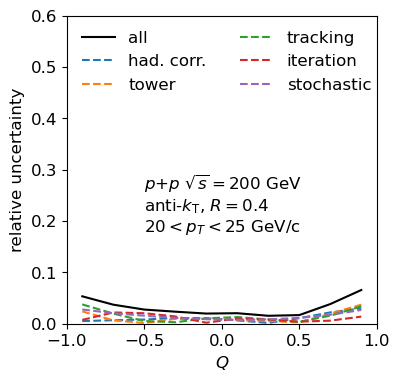

In [30]:
plt.figure(figsize=(4,4))

plt.plot(x, (err/y_arr[1]), color='k', label='all')
plt.plot(x, (err3/y_arr[1]), '--', label='had. corr.')
plt.plot(x, (err2/y_arr[1]), '--', label='tower')
plt.plot(x, (err1/y_arr[1]), '--', label='tracking')
# plt.plot(x, (err4/y_arr[1]), '--', label='Herwig')
# plt.plot(x, (err5/y_arr[1]), '--', label='Pythia8')
plt.plot(x, (err7/y_arr[1]), '--', label='iteration')
plt.plot(x, (err6/y_arr[1]), '--', label='stochastic')

plt.ylabel('relative uncertainty')
plt.xlabel('$Q$')
plt.legend(frameon=False, loc='upper left', ncol=2)
plt.text(-0.5,0.22,'$p$+$p$ $\sqrt{s}=200$ GeV\nanti-$k_\mathrm{T}$, $R=0.4$')
plt.text(-0.5,0.18,'$20<p_T<25$ GeV/c')
plt.xlim(-1,1)
plt.ylim(0,0.6)

In [31]:
mean_20_25 = y_arr[1]
err_20_25 = err

In [32]:
x, y_arr, err_arr = process_ob_nom(1)
# x, y_arr_hw, err_arr_hw = process_ob_hw(1)
# x, y_arr_py8, err_arr_py8 = process_ob_py8(1)
x, y_arr_eff096, err_arr_eff096 = process_ob_detector(1, "eff096", df1_eff096)
x, y_arr_tow104, err_arr_tow104 = process_ob_detector(1, "tow104", df1_tow104)
x, y_arr_hadcorr05, err_arr_hadcorr05 = process_ob_detector(1, "hadcorr05", df1_hadcorr05)

observable: q
iteration 1
relative uncertainty from NN: [0.00339467 0.00263567 0.0019526  0.00136503 0.00089057 0.00059893
 0.0007199  0.00129418 0.00202301 0.00295072]
relative uncertainty from stat: [0.01950886 0.01168115 0.00884119 0.00697624 0.00630845 0.00582389
 0.00601008 0.00660119 0.00815402 0.01139405]
total (stat + NN + MC bootstrap + data bootstrap): [0.019802   0.0119748  0.00905424 0.00710854 0.006371   0.00585461
 0.00605304 0.00672686 0.00840122 0.01176992]
iteration 2
relative uncertainty from NN: [0.00337108 0.00243336 0.0016708  0.00111775 0.00082987 0.00069335
 0.00068774 0.00110382 0.00164815 0.00238971]
relative uncertainty from stat: [0.01947152 0.01169857 0.00885509 0.006982   0.00634385 0.00584881
 0.0060358  0.0066039  0.00815095 0.01140395]
relative uncertainty from MC bootstrap: [0.02983845 0.02131698 0.01454231 0.01173577 0.007897   0.00653061
 0.00683214 0.00979854 0.01651431 0.02399581]
relative uncertainty from data bootstrap: [0.01239804 0.0103239  0.00

In [33]:
err1 = abs(np.array(y_arr[1])-np.array(y_arr_eff096[0]))
err2 = abs(np.array(y_arr[1])-np.array(y_arr_tow104[0]))
err3 = abs(np.array(y_arr[1])-np.array(y_arr_hadcorr05[0]))
err4 = np.zeros_like(err1) # abs(np.array(y_arr[1])-np.array(y_arr_hw[0]))
err5 = np.zeros_like(err1) # abs(np.array(y_arr[1])-np.array(y_arr_py8[0]))
err6 = err_arr[1]

delta_y = []
for it in range(2,7): 
    delta_y.append( abs(y_arr[it-1]-y_arr[1]) )
err7 = np.max(delta_y,axis=0)

err = []
for i in range(0,len(err1)):
    err.append( np.sqrt( (err1[i])**2 + (err2[i])**2 + (err3[i])**2 + (max(abs(err4[i]), abs(err5[i]), abs(err7[i])))**2 + (err6[i])**2 ) )
err = np.array(err)

<>:15: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:15: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/2806323.py:15: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
  plt.text(-0.5,0.22,'$p$+$p$ $\sqrt{s}=200$ GeV\nanti-$k_\mathrm{T}$, $R=0.4$')


(0.0, 0.6)

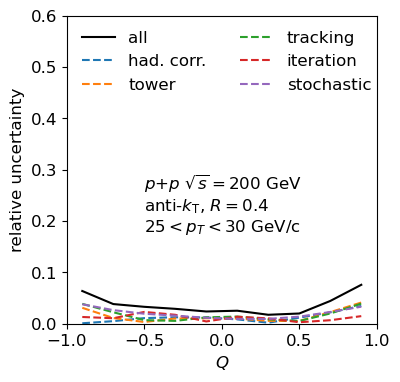

In [34]:
plt.figure(figsize=(4,4))

plt.plot(x, (err/y_arr[1]), color='k', label='all')
plt.plot(x, (err3/y_arr[1]), '--', label='had. corr.')
plt.plot(x, (err2/y_arr[1]), '--', label='tower')
plt.plot(x, (err1/y_arr[1]), '--', label='tracking')
# plt.plot(x, (err4/y_arr[1]), '--', label='Herwig')
# plt.plot(x, (err5/y_arr[1]), '--', label='Pythia8')
plt.plot(x, (err7/y_arr[1]), '--', label='iteration')
plt.plot(x, (err6/y_arr[1]), '--', label='stochastic')

plt.ylabel('relative uncertainty')
plt.xlabel('$Q$')
plt.legend(frameon=False, loc='upper left', ncol=2)
plt.text(-0.5,0.22,'$p$+$p$ $\sqrt{s}=200$ GeV\nanti-$k_\mathrm{T}$, $R=0.4$')
plt.text(-0.5,0.18,'$25<p_T<30$ GeV/c')
plt.xlim(-1,1)
plt.ylim(0,0.6)

In [35]:
mean_25_30 = y_arr[1]
err_25_30 = err

In [36]:
x, y_arr, err_arr = process_ob_nom(2)
# x, y_arr_hw, err_arr_hw = process_ob_hw(2)
# x, y_arr_py8, err_arr_py8 = process_ob_py8(2)
x, y_arr_eff096, err_arr_eff096 = process_ob_detector(2, "eff096", df1_eff096)
x, y_arr_tow104, err_arr_tow104 = process_ob_detector(2, "tow104", df1_tow104)
x, y_arr_hadcorr05, err_arr_hadcorr05 = process_ob_detector(2, "hadcorr05", df1_hadcorr05)

observable: q
iteration 1
relative uncertainty from NN: [0.00409245 0.00330058 0.00253924 0.00183259 0.00122138 0.00070032
 0.0008465  0.00154844 0.0024456  0.00347932]
relative uncertainty from stat: [0.02539247 0.01605401 0.01142246 0.00883877 0.00755052 0.00695143
 0.00708196 0.00783706 0.00989408 0.01487562]
total (stat + NN + MC bootstrap + data bootstrap): [0.02572014 0.01638979 0.0117013  0.00902676 0.00764866 0.00698662
 0.00713237 0.00798856 0.01019185 0.0152771 ]
iteration 2
relative uncertainty from NN: [0.00505129 0.0038661  0.0027813  0.00193878 0.00128564 0.00091461
 0.00106792 0.00159492 0.00232971 0.00332061]
relative uncertainty from stat: [0.02548649 0.01615306 0.0114573  0.00889863 0.00763102 0.00698521
 0.00712195 0.00784415 0.00994358 0.01494776]
relative uncertainty from MC bootstrap: [0.04346768 0.02581645 0.0219498  0.01682083 0.01097425 0.00854064
 0.00931142 0.01381655 0.01904166 0.03037411]
relative uncertainty from data bootstrap: [0.02283045 0.02006281 0.01

In [37]:
err1 = abs(np.array(y_arr[1])-np.array(y_arr_eff096[0]))
err2 = abs(np.array(y_arr[1])-np.array(y_arr_tow104[0]))
err3 = abs(np.array(y_arr[1])-np.array(y_arr_hadcorr05[0]))
err4 = np.zeros_like(err1) # abs(np.array(y_arr[1])-np.array(y_arr_hw[0]))
err5 = np.zeros_like(err1) # abs(np.array(y_arr[1])-np.array(y_arr_py8[0]))
err6 = err_arr[1]

delta_y = []
for it in range(2,7): 
    delta_y.append( abs(y_arr[it-1]-y_arr[1]) )
err7 = np.max(delta_y,axis=0)

err = []
for i in range(0,len(err1)):
    err.append( np.sqrt( (err1[i])**2 + (err2[i])**2 + (err3[i])**2 + (max(abs(err4[i]), abs(err5[i]), abs(err7[i])))**2 + (err6[i])**2 ) )
err = np.array(err)

<>:15: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:15: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/3372927218.py:15: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
  plt.text(-0.5,0.22,'$p$+$p$ $\sqrt{s}=200$ GeV\nanti-$k_\mathrm{T}$, $R=0.4$')


(0.0, 0.6)

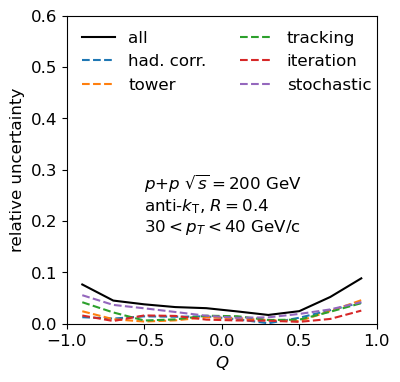

In [38]:
plt.figure(figsize=(4,4))

plt.plot(x, (err/y_arr[1]), color='k', label='all')
plt.plot(x, (err3/y_arr[1]), '--', label='had. corr.')
plt.plot(x, (err2/y_arr[1]), '--', label='tower')
plt.plot(x, (err1/y_arr[1]), '--', label='tracking')
# plt.plot(x, (err4/y_arr[1]), '--', label='Herwig')
# plt.plot(x, (err5/y_arr[1]), '--', label='Pythia8')
plt.plot(x, (err7/y_arr[1]), '--', label='iteration')
plt.plot(x, (err6/y_arr[1]), '--', label='stochastic')

plt.ylabel('relative uncertainty')
plt.xlabel('$Q$')
plt.legend(frameon=False, loc='upper left', ncol=2)
plt.text(-0.5,0.22,'$p$+$p$ $\sqrt{s}=200$ GeV\nanti-$k_\mathrm{T}$, $R=0.4$')
plt.text(-0.5,0.18,'$30<p_T<40$ GeV/c')
plt.xlim(-1,1)
plt.ylim(0,0.6)

In [39]:
mean_30_40 = y_arr[1]
err_30_40 = err

In [40]:
x, y_arr, err_arr = process_ob_nom(3)
# x, y_arr_hw, err_arr_hw = process_ob_hw(3)
# x, y_arr_py8, err_arr_py8 = process_ob_py8(3)
x, y_arr_eff096, err_arr_eff096 = process_ob_detector(3, "eff096", df1_eff096)
x, y_arr_tow104, err_arr_tow104 = process_ob_detector(3, "tow104", df1_tow104)
x, y_arr_hadcorr05, err_arr_hadcorr05 = process_ob_detector(3, "hadcorr05", df1_hadcorr05)

observable: q
iteration 1
relative uncertainty from NN: [0.00618163 0.00509529 0.00411679 0.00307775 0.00200886 0.0010288
 0.00112724 0.0022502  0.00356524 0.00491948]
relative uncertainty from stat: [0.05496943 0.02495554 0.0189677  0.01376441 0.01054654 0.00981802
 0.00868044 0.01033093 0.014414   0.01927176]
total (stat + NN + MC bootstrap + data bootstrap): [0.05531591 0.02547039 0.01940931 0.0141043  0.01073616 0.00987178
 0.00875333 0.01057315 0.01484838 0.01988975]
iteration 2
relative uncertainty from NN: [0.00891246 0.00722641 0.00583914 0.00441741 0.00294129 0.00176685
 0.0017933  0.00301455 0.00461405 0.00638642]
relative uncertainty from stat: [0.05402566 0.02516603 0.01901721 0.0132009  0.01070801 0.01004576
 0.00880418 0.01055792 0.01481038 0.01948049]
relative uncertainty from MC bootstrap: [0.06930188 0.04365536 0.03499663 0.02574705 0.0203561  0.01299094
 0.01217097 0.02082281 0.03274464 0.04147069]
relative uncertainty from data bootstrap: [0.03616473 0.0294136  0.023

In [41]:
err1 = abs(np.array(y_arr[1])-np.array(y_arr_eff096[0]))
err2 = abs(np.array(y_arr[1])-np.array(y_arr_tow104[0]))
err3 = abs(np.array(y_arr[1])-np.array(y_arr_hadcorr05[0]))
err4 = np.zeros_like(err1) # abs(np.array(y_arr[1])-np.array(y_arr_hw[0]))
err5 = np.zeros_like(err1) # abs(np.array(y_arr[1])-np.array(y_arr_py8[0]))
err6 = err_arr[1]

delta_y = []
for it in range(2,7): 
    delta_y.append( abs(y_arr[it-1]-y_arr[1]) )
err7 = np.max(delta_y,axis=0)

err = []
for i in range(0,len(err1)):
    err.append( np.sqrt( (err1[i])**2 + (err2[i])**2 + (err3[i])**2 + (max(abs(err4[i]), abs(err5[i]), abs(err7[i])))**2 + (err6[i])**2 ) )
err = np.array(err)

<>:15: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:15: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/833948395.py:15: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
  plt.text(-0.5,0.22,'$p$+$p$ $\sqrt{s}=200$ GeV\nanti-$k_\mathrm{T}$, $R=0.4$')


(0.0, 0.6)

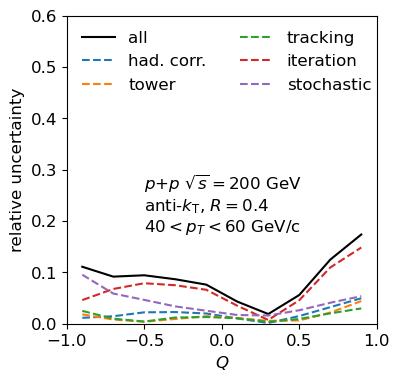

In [42]:
plt.figure(figsize=(4,4))

plt.plot(x, (err/y_arr[1]), color='k', label='all')
plt.plot(x, (err3/y_arr[1]), '--', label='had. corr.')
plt.plot(x, (err2/y_arr[1]), '--', label='tower')
plt.plot(x, (err1/y_arr[1]), '--', label='tracking')
# plt.plot(x, (err4/y_arr[1]), '--', label='Herwig')
# plt.plot(x, (err5/y_arr[1]), '--', label='Pythia8')
plt.plot(x, (err7/y_arr[1]), '--', label='iteration')
plt.plot(x, (err6/y_arr[1]), '--', label='stochastic')

plt.ylabel('relative uncertainty')
plt.xlabel('$Q$')
plt.legend(frameon=False, loc='upper left', ncol=2)
plt.text(-0.5,0.22,'$p$+$p$ $\sqrt{s}=200$ GeV\nanti-$k_\mathrm{T}$, $R=0.4$')
plt.text(-0.5,0.18,'$40<p_T<60$ GeV/c')
plt.xlim(-1,1)
plt.ylim(0,0.6)

In [43]:
mean_40_60 = y_arr[1]
err_40_60 = err

In [44]:
x, y_arr, err_arr = process_ob_nom(4)
# x, y_arr_hw, err_arr_hw = process_ob_hw(4)
# x, y_arr_py8, err_arr_py8 = process_ob_py8(4)
x, y_arr_eff096, err_arr_eff096 = process_ob_detector(4, "eff096", df1_eff096)
x, y_arr_tow104, err_arr_tow104 = process_ob_detector(4, "tow104", df1_tow104)
x, y_arr_hadcorr05, err_arr_hadcorr05 = process_ob_detector(4, "hadcorr05", df1_hadcorr05)

observable: q
iteration 1
relative uncertainty from NN: [0.00431061 0.00225923 0.00070612 0.00287889]
relative uncertainty from stat: [0.01514458 0.00813995 0.0065736  0.00838034]
total (stat + NN + MC bootstrap + data bootstrap): [0.0157461  0.00844765 0.00661141 0.00886104]
iteration 2
relative uncertainty from NN: [0.00614883 0.00326649 0.0012619  0.00378007]
relative uncertainty from stat: [0.01510382 0.00833436 0.00652286 0.00858481]
relative uncertainty from MC bootstrap: [0.0345127  0.01991576 0.00743811 0.02487069]
relative uncertainty from data bootstrap: [0.02436709 0.01189555 0.00302062 0.01511092]
total (stat + NN + MC bootstrap + data bootstrap): [0.04528593 0.0248651  0.01042064 0.03057579]
iteration 3
relative uncertainty from NN: [0.00820346 0.0042753  0.0017677  0.00475986]
relative uncertainty from stat: [0.01548869 0.00845779 0.00672588 0.00842486]
total (stat + NN + MC bootstrap + data bootstrap): [0.01752701 0.00947694 0.0069543  0.0096765 ]
iteration 4
relative un

In [45]:
err1 = abs(np.array(y_arr[1])-np.array(y_arr_eff096[0]))
err2 = abs(np.array(y_arr[1])-np.array(y_arr_tow104[0]))
err3 = abs(np.array(y_arr[1])-np.array(y_arr_hadcorr05[0]))
err4 = np.zeros_like(err1) # abs(np.array(y_arr[1])-np.array(y_arr_hw[0]))
err5 = np.zeros_like(err1) # abs(np.array(y_arr[1])-np.array(y_arr_py8[0]))
err6 = err_arr[1]

delta_y = []
for it in range(2,7): 
    delta_y.append( abs(y_arr[it-1]-y_arr[1]) )
err7 = np.max(delta_y,axis=0)

err = []
for i in range(0,len(err1)):
    err.append( np.sqrt( (err1[i])**2 + (err2[i])**2 + (err3[i])**2 + (max(abs(err4[i]), abs(err5[i]), abs(err7[i])))**2 + (err6[i])**2 ) )
err = np.array(err)

<>:15: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:15: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/833948395.py:15: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
  plt.text(-0.5,0.22,'$p$+$p$ $\sqrt{s}=200$ GeV\nanti-$k_\mathrm{T}$, $R=0.4$')


(0.0, 0.6)

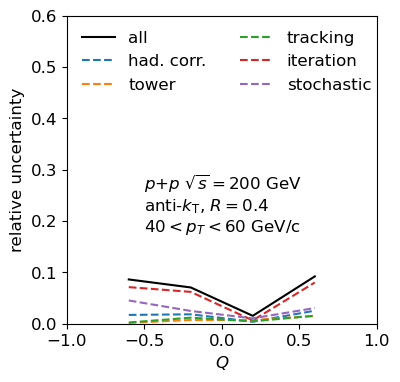

In [46]:
plt.figure(figsize=(4,4))

plt.plot(x, (err/y_arr[1]), color='k', label='all')
plt.plot(x, (err3/y_arr[1]), '--', label='had. corr.')
plt.plot(x, (err2/y_arr[1]), '--', label='tower')
plt.plot(x, (err1/y_arr[1]), '--', label='tracking')
# plt.plot(x, (err4/y_arr[1]), '--', label='Herwig')
# plt.plot(x, (err5/y_arr[1]), '--', label='Pythia8')
plt.plot(x, (err7/y_arr[1]), '--', label='iteration')
plt.plot(x, (err6/y_arr[1]), '--', label='stochastic')

plt.ylabel('relative uncertainty')
plt.xlabel('$Q$')
plt.legend(frameon=False, loc='upper left', ncol=2)
plt.text(-0.5,0.22,'$p$+$p$ $\sqrt{s}=200$ GeV\nanti-$k_\mathrm{T}$, $R=0.4$')
plt.text(-0.5,0.18,'$40<p_T<60$ GeV/c')
plt.xlim(-1,1)
plt.ylim(0,0.6)

In [47]:
mean_40_60_coarse = y_arr[1]
err_40_60_coarse = err

### Fig 7.17

<>:13: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:14: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:18: SyntaxWarning: "\k" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\k"? A raw string is also an option.
<>:30: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:34: SyntaxWarning: "\k" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\k"? A raw string is also an option.
<>:46: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:50: SyntaxWarning: "\k" is an invalid escape sequence. Such sequences wil

[Text(0, 0.0, ''),
 Text(0, 0.2, ''),
 Text(0, 0.4, ''),
 Text(0, 0.6000000000000001, ''),
 Text(0, 0.8, ''),
 Text(0, 1.0, ''),
 Text(0, 1.2000000000000002, ''),
 Text(0, 1.4000000000000001, ''),
 Text(0, 1.6, '')]

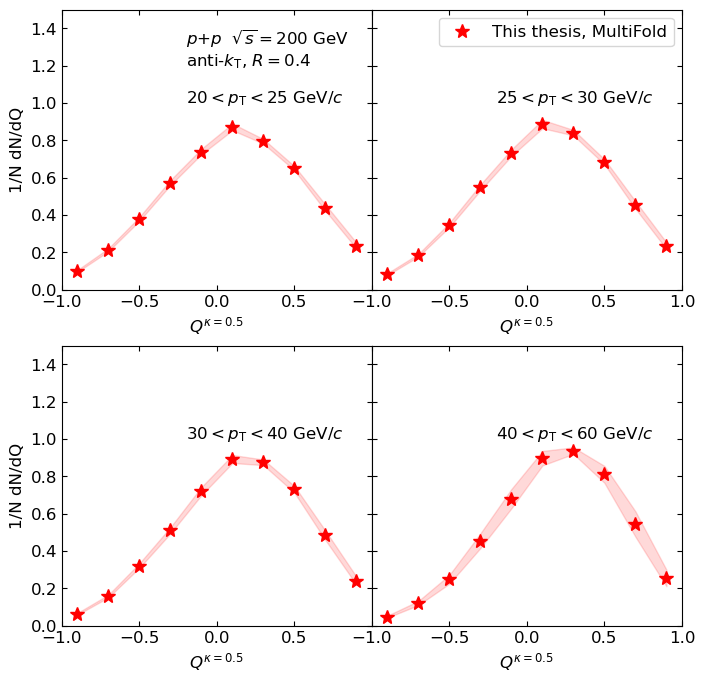

In [48]:
gs1 = gridspec.GridSpec(2,2,width_ratios=(1,1), height_ratios=(5,5))

fig = plt.figure(figsize=(8,8))
plt.subplots_adjust(wspace=0)

binedges = binedgess[0]
x = []
for i in range(0, len(binedges)-1):
    midpoint = 0.5 * (binedges[i] + binedges[i+1])
    x.append(midpoint)

ax1 = fig.add_subplot(gs1[0])
plt.text(-0.2,1.2,'$p$+$p$  $\sqrt{s}=200$ GeV\nanti-$k_\mathrm{T}$, $R=0.4$', fontsize=12)
plt.text(-0.2,1.,'$20 < p_\mathrm{T} < 25$ GeV/$c$', fontsize=12)
plt.plot(x, mean_20_25, color='red', marker='*', ls='none', markersize=10)
plt.fill_between(x, mean_20_25-err_20_25, mean_20_25+err_20_25, color='r', alpha=0.15)
plt.xlim(-1,1)
plt.xlabel('$Q^{\kappa=0.5}$')
plt.ylim(0,1.5)
plt.ylabel('1/N dN/dQ')
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')
#ax.axes.xaxis.set_minor_locator(MultipleLocator(0.5))
#ax.axes.xaxis.set_major_locator(MultipleLocator(2))
#ax.axes.yaxis.set_minor_locator(MultipleLocator(0.01))
#ax.axes.yaxis.set_major_locator(MultipleLocator(0.05))
plt.xticks(np.arange(-1.,1,0.5))

ax2 = fig.add_subplot(gs1[1])
plt.text(-0.2,1,'$25 < p_\mathrm{T} < 30$ GeV/$c$', fontsize=12)
plt.plot(x, mean_25_30, color='red', marker='*', ls='none', markersize=10, label='This thesis, MultiFold')
plt.fill_between(x, mean_25_30-err_25_30, mean_25_30+err_25_30, color='r', alpha=0.15)
plt.xlim(-1,1)
plt.xlabel('$Q^{\kappa=0.5}$')
plt.ylim(0,1.5)
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')
ax.axes.yaxis.set_ticklabels([])
#ax.axes.xaxis.set_minor_locator(MultipleLocator(0.5))
#ax.axes.xaxis.set_major_locator(MultipleLocator(2))
#ax.axes.yaxis.set_minor_locator(MultipleLocator(0.01))
#ax.axes.yaxis.set_major_locator(MultipleLocator(0.05))
plt.legend(fontsize=12, loc='upper right')

ax3 = fig.add_subplot(gs1[2])
plt.text(-0.2,1,'$30 < p_\mathrm{T} < 40$ GeV/$c$', fontsize=12)
plt.plot(x, mean_30_40, color='red', marker='*', ls='none', markersize=10)
plt.fill_between(x, mean_30_40-err_30_40, mean_30_40+err_30_40, color='r', alpha=0.15)
plt.xlim(-1,1)
plt.xlabel('$Q^{\kappa=0.5}$')
plt.ylabel('1/N dN/dQ')
plt.ylim(0,1.5)
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')
#ax.axes.xaxis.set_minor_locator(MultipleLocator(0.5))
#ax.axes.xaxis.set_major_locator(MultipleLocator(2))
#ax.axes.yaxis.set_minor_locator(MultipleLocator(0.01))
#ax.axes.yaxis.set_major_locator(MultipleLocator(0.05))
plt.xticks(np.arange(-1.,1,0.5))

ax4 = fig.add_subplot(gs1[3])
plt.text(-0.2,1,'$40 < p_\mathrm{T} < 60$ GeV/$c$', fontsize=12)
plt.plot(x, mean_40_60, color='red', marker='*', ls='none', markersize=10, label='MultiFold')
plt.fill_between(x, mean_40_60-err_40_60, mean_40_60+err_40_60, color='r', alpha=0.15)
plt.xlim(-1,1)
plt.xlabel('$Q^{\kappa=0.5}$')
plt.ylim(0,1.5)
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')
ax.axes.yaxis.set_ticklabels([])
#ax.axes.xaxis.set_minor_locator(MultipleLocator(0.5))
#ax.axes.xaxis.set_major_locator(MultipleLocator(2))
#ax.axes.yaxis.set_minor_locator(MultipleLocator(0.01))
#ax.axes.yaxis.set_major_locator(MultipleLocator(0.05))

# $M$

In [66]:
isaac_path = '/nfs/roberts/home/ys668/analysis/run12/data/fully_corrected/txts/m/'
mean_20_25_isaac = np.loadtxt(isaac_path+'20_25_mean_isaac.txt')
err_20_25_isaac = np.loadtxt(isaac_path+'20_25_err_isaac.txt')
mean_25_30_isaac = np.loadtxt(isaac_path+'25_30_mean_isaac.txt')
err_25_30_isaac = np.loadtxt(isaac_path+'25_30_err_isaac.txt')
mean_30_40_isaac = np.loadtxt(isaac_path+'30_40_mean_isaac.txt')
err_30_40_isaac = np.loadtxt(isaac_path+'30_40_err_isaac.txt')

In [49]:
obs = ['m','m','m','m']
binedgess = [np.arange(0,13),np.arange(0,13),np.arange(0,13),np.arange(0,13)]
cuts = ['20<pt<25', '25<pt<30', '30<pt<40', '40<pt<60']

In [51]:
x, y_arr, err_arr = process_ob_nom(0)
# x, y_arr_hw, err_arr_hw = process_ob_hw(0)
# x, y_arr_py8, err_arr_py8 = process_ob_py8(0)
x, y_arr_eff096, err_arr_eff096 = process_ob_detector(0, "eff096", df1_eff096)
x, y_arr_tow104, err_arr_tow104 = process_ob_detector(0, "tow104", df1_tow104)
x, y_arr_hadcorr05, err_arr_hadcorr05 = process_ob_detector(0, "hadcorr05", df1_hadcorr05)

observable: m
iteration 1
relative uncertainty from NN: [0.00462232 0.00238134 0.00125968 0.00048841 0.00045568 0.00082118
 0.00114883 0.00157388 0.00202916 0.00253427 0.00312557 0.0034106 ]
relative uncertainty from stat: [0.03139582 0.00971565 0.00482225 0.00386148 0.00398705 0.00494615
 0.00664983 0.01061709 0.01939415 0.03772275 0.07307822 0.17213042]
total (stat + NN + MC bootstrap + data bootstrap): [0.03173426 0.01000324 0.00498407 0.00389225 0.00401301 0.00501386
 0.00674834 0.01073312 0.01950001 0.03780778 0.07314503 0.17216421]
iteration 2
relative uncertainty from NN: [0.00354146 0.00205021 0.00108085 0.00049152 0.00042003 0.00070163
 0.00107649 0.00153278 0.00205749 0.00266739 0.00332538 0.00376965]
relative uncertainty from stat: [0.03108114 0.00971209 0.00484118 0.00387211 0.00398865 0.00493734
 0.00667289 0.01059644 0.0193756  0.03786597 0.07299155 0.17251943]
relative uncertainty from MC bootstrap: [0.04212571 0.01896208 0.00922315 0.0040633  0.00455798 0.0068826
 0.008

In [ ]:
err1 = abs(np.array(y_arr[1])-np.array(y_arr_eff096[0]))
err2 = abs(np.array(y_arr[1])-np.array(y_arr_tow104[0]))
err3 = abs(np.array(y_arr[1])-np.array(y_arr_hadcorr05[0]))
err4 = np.zeros_like(err1)
err5 = np.zeros_like(err1)
err6 = err_arr[1]

delta_y = []
for it in range(2,7): 
    delta_y.append( abs(y_arr[it-1]-y_arr[1]) )
err7 = np.max(delta_y,axis=0)

err = []
for i in range(0,len(err1)):
    err.append( np.sqrt( (err1[i])**2 + (err2[i])**2 + (err3[i])**2 + (max(abs(err4[i]), abs(err5[i]), abs(err7[i])))**2 + (err6[i])**2 ) )
err = np.array(err)

<>:15: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:15: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/3231818035.py:15: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
  plt.text(0.25,0.22,'$p$+$p$ $\sqrt{s}=200$ GeV\nanti-$k_\mathrm{T}$, $R=0.4$')


(0.0, 0.6)

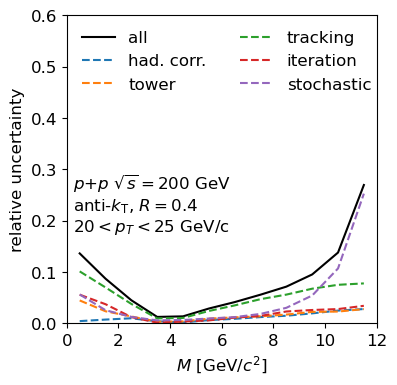

In [53]:
plt.figure(figsize=(4,4))

plt.plot(x, (err/y_arr[1]), color='k', label='all')
plt.plot(x, (err3/y_arr[1]), '--', label='had. corr.')
plt.plot(x, (err2/y_arr[1]), '--', label='tower')
plt.plot(x, (err1/y_arr[1]), '--', label='tracking')
# plt.plot(x, (err4/y_arr[1]), '--', label='Herwig')
# plt.plot(x, (err5/y_arr[1]), '--', label='Pythia8')
plt.plot(x, (err7/y_arr[1]), '--', label='iteration')
plt.plot(x, (err6/y_arr[1]), '--', label='stochastic')

plt.ylabel('relative uncertainty')
plt.xlabel('$M$ [GeV/$c^2$]')
plt.legend(frameon=False, loc='upper left', ncol=2)
plt.text(0.25,0.22,'$p$+$p$ $\sqrt{s}=200$ GeV\nanti-$k_\mathrm{T}$, $R=0.4$')
plt.text(0.25,0.18,'$20<p_T<25$ GeV/c')
plt.xlim(0,12)
plt.ylim(0,0.6)

In [54]:
mean_20_25 = y_arr[1]
err_20_25 = err

In [55]:
x, y_arr, err_arr = process_ob_nom(1)
# x, y_arr_hw, err_arr_hw = process_ob_hw(1)
# x, y_arr_py8, err_arr_py8 = process_ob_py8(1)
x, y_arr_eff096, err_arr_eff096 = process_ob_detector(1, "eff096", df1_eff096)
x, y_arr_tow104, err_arr_tow104 = process_ob_detector(1, "tow104", df1_tow104)
x, y_arr_hadcorr05, err_arr_hadcorr05 = process_ob_detector(1, "hadcorr05", df1_hadcorr05)

observable: m
iteration 1
relative uncertainty from NN: [0.00539317 0.00301155 0.00173226 0.00088132 0.00045042 0.00065442
 0.00108322 0.00154047 0.00201745 0.00252352 0.00320105 0.00353872]
relative uncertainty from stat: [0.0449166  0.01476259 0.00723999 0.00516249 0.0049805  0.0055033
 0.00685229 0.00907455 0.01513096 0.02369402 0.04736515 0.09346183]
total (stat + NN + MC bootstrap + data bootstrap): [0.04523922 0.01506664 0.00744434 0.00523718 0.00500083 0.00554208
 0.00693738 0.00920438 0.01526486 0.02382803 0.0474732  0.0935288 ]
iteration 2
relative uncertainty from NN: [0.00459357 0.00291451 0.00154058 0.00084063 0.0005436  0.00059314
 0.00097997 0.00146863 0.00201186 0.00259992 0.0033332  0.00383917]
relative uncertainty from stat: [0.04529703 0.01475125 0.00725333 0.00518085 0.00497615 0.00550799
 0.00685607 0.00907888 0.01519134 0.02372794 0.04726806 0.09486821]
relative uncertainty from MC bootstrap: [0.04817757 0.02763327 0.01394379 0.00621855 0.00508057 0.00703604
 0.008

In [ ]:
err1 = abs(np.array(y_arr[1])-np.array(y_arr_eff096[0]))
err2 = abs(np.array(y_arr[1])-np.array(y_arr_tow104[0]))
err3 = abs(np.array(y_arr[1])-np.array(y_arr_hadcorr05[0]))
err4 = np.zeros_like(err1)
err5 = np.zeros_like(err1)
err6 = err_arr[1]
delta_y = []
for it in range(2,7):
    delta_y.append(abs(y_arr[it-1] - y_arr[1]))
err7 = np.max(delta_y, axis=0)

err = []
for i in range(0,len(err1)):
    err.append( np.sqrt( (err1[i])**2 + (err2[i])**2 + (err3[i])**2 + (max(abs(err4[i]),abs(err5[i])))**2 + (err6[i])**2 ) )
err = np.array(err)

In [57]:
mean_25_30 = y_arr[1]
err_25_30 = err

In [58]:
x, y_arr, err_arr = process_ob_nom(2)
# x, y_arr_hw, err_arr_hw = process_ob_hw(2)
# x, y_arr_py8, err_arr_py8 = process_ob_py8(2)
x, y_arr_eff096, err_arr_eff096 = process_ob_detector(2, "eff096", df1_eff096)
x, y_arr_tow104, err_arr_tow104 = process_ob_detector(2, "tow104", df1_tow104)
x, y_arr_hadcorr05, err_arr_hadcorr05 = process_ob_detector(2, "hadcorr05", df1_hadcorr05)

observable: m
iteration 1
relative uncertainty from NN: [0.00556742 0.00388371 0.00247042 0.00145578 0.00088253 0.00059953
 0.00101156 0.00169066 0.00239711 0.00301368 0.00384632 0.00466405]
relative uncertainty from stat: [0.07994508 0.02446684 0.01139187 0.0073474  0.00638614 0.00657304
 0.00754003 0.00919539 0.01229854 0.01742317 0.02716372 0.05029457]
total (stat + NN + MC bootstrap + data bootstrap): [0.0801387  0.02477316 0.01165666 0.00749023 0.00644683 0.00660033
 0.00760758 0.00934952 0.01252997 0.01768189 0.02743469 0.05051037]
iteration 2
relative uncertainty from NN: [0.00656793 0.00465509 0.00253776 0.00139974 0.00098842 0.00077625
 0.00095214 0.00158311 0.00232261 0.00304201 0.00397908 0.00489715]
relative uncertainty from stat: [0.08114181 0.02458074 0.01142653 0.00740522 0.00643546 0.0065945
 0.00757231 0.00916109 0.01231428 0.01744587 0.0271865  0.05143661]
relative uncertainty from MC bootstrap: [0.09513357 0.0363556  0.01825577 0.01064312 0.00832012 0.00721109
 0.009

In [ ]:
err1 = abs(np.array(y_arr[1])-np.array(y_arr_eff096[0]))
err2 = abs(np.array(y_arr[1])-np.array(y_arr_tow104[0]))
err3 = abs(np.array(y_arr[1])-np.array(y_arr_hadcorr05[0]))
err4 = np.zeros_like(err1)
err5 = np.zeros_like(err1)
err6 = err_arr[1]
delta_y = []
for it in range(2,7):
    delta_y.append(abs(y_arr[it-1] - y_arr[1]))
err7 = np.max(delta_y, axis=0)

err = []
for i in range(0,len(err1)):
    err.append( np.sqrt( (err1[i])**2 + (err2[i])**2 + (err3[i])**2 + (max(abs(err4[i]),abs(err5[i])))**2 + (err6[i])**2 ) )
err = np.array(err)

In [60]:
mean_30_40 = y_arr[1]
err_30_40 = err

In [61]:
x, y_arr, err_arr = process_ob_nom(3)
# x, y_arr_hw, err_arr_hw = process_ob_hw(3)
# x, y_arr_py8, err_arr_py8 = process_ob_py8(3)
x, y_arr_eff096, err_arr_eff096 = process_ob_detector(3, "eff096", df1_eff096)
x, y_arr_tow104, err_arr_tow104 = process_ob_detector(3, "tow104", df1_tow104)
x, y_arr_hadcorr05, err_arr_hadcorr05 = process_ob_detector(3, "hadcorr05", df1_hadcorr05)

observable: m
iteration 1
relative uncertainty from NN: [0.00747625 0.00593893 0.00439088 0.00307277 0.00213783 0.00141383
 0.00107272 0.00172026 0.00280911 0.00418948 0.00543569 0.0067155 ]
relative uncertainty from stat: [0.096055   0.05998457 0.02116755 0.01161365 0.00949793 0.00931809
 0.01008616 0.01138426 0.01525735 0.02028676 0.0247195  0.02975562]
total (stat + NN + MC bootstrap + data bootstrap): [0.09634551 0.06027785 0.02161816 0.01201327 0.00973555 0.00942474
 0.01014305 0.0115135  0.0155138  0.02071484 0.02531008 0.03050402]
iteration 2
relative uncertainty from NN: [0.01179897 0.00904725 0.00615618 0.00391003 0.00255797 0.00182114
 0.00154826 0.0021385  0.00327025 0.00479027 0.00620888 0.00770925]
relative uncertainty from stat: [0.09581483 0.06070884 0.02169614 0.01166136 0.00963963 0.0090683
 0.01006526 0.01155324 0.0151744  0.0204208  0.02455974 0.03002868]
relative uncertainty from MC bootstrap: [0.1104307  0.07760696 0.0420662  0.0267777  0.0200348  0.01283477
 0.011

In [ ]:
err1 = abs(np.array(y_arr[1])-np.array(y_arr_eff096[0]))
err2 = abs(np.array(y_arr[1])-np.array(y_arr_tow104[0]))
err3 = abs(np.array(y_arr[1])-np.array(y_arr_hadcorr05[0]))
err4 = np.zeros_like(err1)
err5 = np.zeros_like(err1)
err6 = err_arr[1]

delta_y = []
for it in range(2,7): 
    delta_y.append( abs(y_arr[it-1]-y_arr[1]) )
err7 = np.max(delta_y,axis=0)

err = []
for i in range(0,len(err1)):
    err.append( np.sqrt( (err1[i])**2 + (err2[i])**2 + (err3[i])**2 + (max(abs(err4[i]), abs(err5[i]), abs(err7[i])))**2 + (err6[i])**2 ) )
err = np.array(err)

(0.0, 0.6)

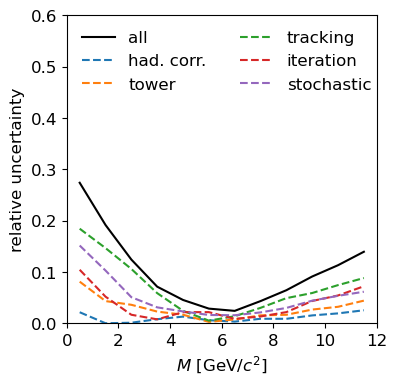

In [ ]:
plt.figure(figsize=(4,4))

plt.plot(x, (err/y_arr[1]), color='k', label='all')
plt.plot(x, (err3/y_arr[1]), '--', label='had. corr.')
plt.plot(x, (err2/y_arr[1]), '--', label='tower')
plt.plot(x, (err1/y_arr[1]), '--', label='tracking')
# plt.plot(x, (err4/y_arr[1]), '--', label='Herwig')
# plt.plot(x, (err5/y_arr[1]), '--', label='Pythia8')
plt.plot(x, (err7/y_arr[1]), '--', label='iteration')
plt.plot(x, (err6/y_arr[1]), '--', label='stochastic')

plt.ylabel('relative uncertainty')
plt.xlabel('$M$ [GeV/$c^2$]')
plt.legend(frameon=False, loc='upper left', ncol=2)
#plt.text(0.25,0.22,'$p$+$p$ $\sqrt{s}=200$ GeV\nanti-$k_\mathrm{T}$, $R=0.4$')
plt.text(0.25,0.18,'$40<p_T<60$ GeV/c')
plt.xlim(0,12)
plt.ylim(0,0.6)

In [64]:
mean_40_60 = y_arr[1]
err_40_60 = err

### Fig 7.12

<>:9: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:10: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:28: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:47: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:65: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:9: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:10: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will 

([<matplotlib.axis.XTick at 0x145b85cd1450>,
 [Text(0, 0, '0'),
  Text(2, 0, '2'),
  Text(4, 0, '4'),
  Text(6, 0, '6'),
  Text(8, 0, '8'),
  Text(10, 0, '10'),
  Text(12, 0, '12')])

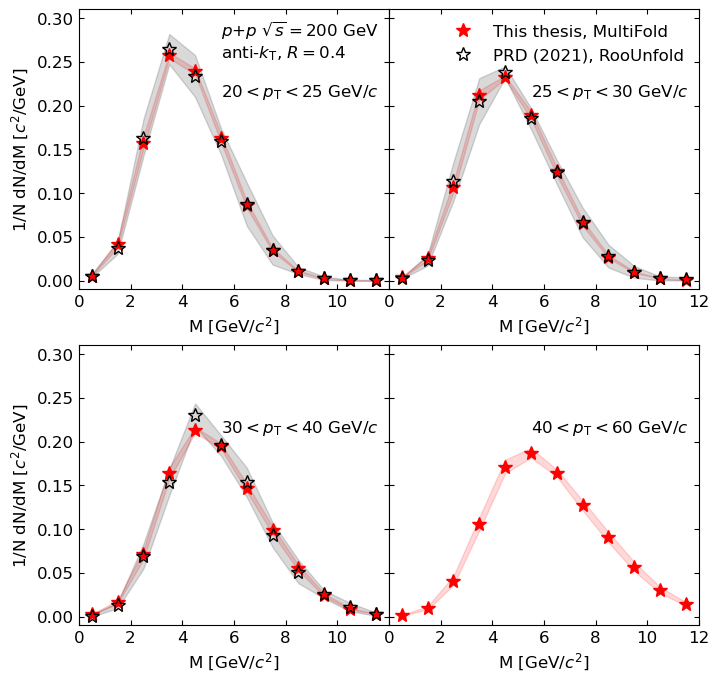

In [68]:
gs1 = gridspec.GridSpec(2,2,width_ratios=(1,1), height_ratios=(5,5))

fig = plt.figure(figsize=(8,8))
plt.subplots_adjust(wspace=0)

x = np.arange(0.5,12.5)

ax1 = fig.add_subplot(gs1[0])
plt.text(5.5,0.255,'$p$+$p$ $\sqrt{s}=200$ GeV\nanti-$k_\mathrm{T}$, $R=0.4$', fontsize=12)
plt.text(5.5,0.21,'$20 < p_\mathrm{T} < 25$ GeV/$c$', fontsize=12)
plt.plot(x, mean_20_25, color='red', marker='*', ls='none', markersize=10, label='MultiFold')
plt.fill_between(x, mean_20_25-err_20_25, mean_20_25+err_20_25, color='r', alpha=0.15)
plt.fill_between(x+0, mean_20_25_isaac-err_20_25_isaac, mean_20_25_isaac+err_20_25_isaac, color='k', alpha=0.15)
plt.plot(x+0, mean_20_25_isaac, label='PRD (2021), RooUnfold', ls='none', marker='*', markersize=10, color='none', mec='k')
plt.xlim(left=0, right=12)
plt.xlabel('M [GeV/$c^2$]')
plt.ylim(-0.01,0.31)
plt.ylabel('1/N dN/dM [$c^2$/GeV]')
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')
# ax.axes.xaxis.set_minor_locator(MultipleLocator(0.5))
# ax.axes.xaxis.set_major_locator(MultipleLocator(2))
# ax.axes.yaxis.set_minor_locator(MultipleLocator(0.01))
# ax.axes.yaxis.set_major_locator(MultipleLocator(0.05))
plt.xticks(np.arange(0,12,2))

ax2 = fig.add_subplot(gs1[1])
plt.text(5.5,0.21,'$25 < p_\mathrm{T} < 30$ GeV/$c$', fontsize=12)
plt.plot(x, mean_25_30, color='red', marker='*', ls='none', markersize=10, label='This thesis, MultiFold')
plt.fill_between(x, mean_25_30-err_25_30, mean_25_30+err_25_30, color='r', alpha=0.15)
plt.fill_between(x+0, mean_25_30_isaac-err_25_30_isaac, mean_25_30_isaac+err_25_30_isaac, color='k', alpha=0.15)
plt.plot(x+0, mean_25_30_isaac, label='PRD (2021), RooUnfold', ls='none', marker='*', markersize=10, color='none', mec='k')
plt.xlim(left=0, right=12)
plt.xlabel('M [GeV/$c^2$]')
plt.ylim(-0.01,0.31)
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')
ax.axes.yaxis.set_ticklabels([])
# ax.axes.xaxis.set_minor_locator(MultipleLocator(0.5))
# ax.axes.xaxis.set_major_locator(MultipleLocator(2))
# ax.axes.yaxis.set_minor_locator(MultipleLocator(0.01))
# ax.axes.yaxis.set_major_locator(MultipleLocator(0.05))
plt.legend(frameon=False, fontsize=12, loc='upper right')
plt.xticks(np.arange(0,14,2))

ax3 = fig.add_subplot(gs1[2])
plt.text(5.5,0.21,'$30 < p_\mathrm{T} < 40$ GeV/$c$', fontsize=12)
plt.plot(x, mean_30_40, color='red', marker='*', ls='none', markersize=10, label='MultiFold')
plt.fill_between(x, mean_30_40-err_30_40, mean_30_40+err_30_40, color='r', alpha=0.15)
plt.fill_between(x+0, mean_30_40_isaac-err_30_40_isaac, mean_30_40_isaac+err_30_40_isaac, color='k', alpha=0.15)
plt.plot(x+0, mean_30_40_isaac, label='PRD (2021), RooUnfold', ls='none', marker='*', markersize=10, color='none', mec='k')
plt.xlim(left=0, right=12)
plt.xlabel('M [GeV/$c^2$]')
plt.ylabel('1/N dN/dM [$c^2$/GeV]')
plt.ylim(-0.01,0.31)
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')
# ax.axes.xaxis.set_minor_locator(MultipleLocator(0.5))
# ax.axes.xaxis.set_major_locator(MultipleLocator(2))
# ax.axes.yaxis.set_minor_locator(MultipleLocator(0.01))
# ax.axes.yaxis.set_major_locator(MultipleLocator(0.05))
plt.xticks(np.arange(0,12,2))

ax4 = fig.add_subplot(gs1[3])
plt.text(5.5,0.21,'$40 < p_\mathrm{T} < 60$ GeV/$c$', fontsize=12)
plt.plot(x, mean_40_60, color='red', marker='*', ls='none', markersize=10, label='MultiFold')
plt.fill_between(x, mean_40_60-err_40_60, mean_40_60+err_40_60, color='r', alpha=0.15)
plt.xlim(left=0, right=12)
plt.xlabel('M [GeV/$c^2$]')
plt.ylim(-0.01,0.31)
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')
ax.axes.yaxis.set_ticklabels([])
# ax.axes.xaxis.set_minor_locator(MultipleLocator(0.5))
# ax.axes.xaxis.set_major_locator(MultipleLocator(2))
# ax.axes.yaxis.set_minor_locator(MultipleLocator(0.01))
# ax.axes.yaxis.set_major_locator(MultipleLocator(0.05))
plt.xticks(np.arange(0,14,2))

# $M_g$

In [69]:
mean_20_25_isaac = np.array([0.0293,0.1271,0.2229,0.2306,0.1829,0.1146,0.05737,0.02475,0.0084,0.001756,0.0001826,6.29e-05])
err_stat_20_25_isaac = np.array([0.0005,0.0012,0.0012,0.001,0.0009,0.0005,0.00033,0.00019,9e-05,3.5e-05,2.8e-06,2.3e-06])
err_sys_20_25_isaac = np.array([0.005,0.014,0.022,0.008,0.018,0.01,0.01,0.011,0.004,0.0014,0.00026,0.0005])
err_20_25_isaac = np.sqrt(err_stat_20_25_isaac**2 + err_sys_20_25_isaac**2)

In [70]:
mean_25_30_isaac = np.array([0.0294,0.1137,0.1858,0.2124,0.1813,0.1278,0.0787,0.0433,0.01744,0.00713,0.00123,0.00191])
err_stat_25_30_isaac = np.array([0.0008,0.0015,0.0017,0.0018,0.0015,0.0011,0.0008,0.0004,0.00021,0.00011,3.2e-05,1.6e-05])
err_sys_25_30_isaac = np.array([0.007,0.014,0.035,0.011,0.005,0.008,0.008,0.008,0.008,0.005,0.0012,0.0018])
err_25_30_isaac = np.sqrt(err_stat_25_30_isaac**2 + err_sys_25_30_isaac**2)

In [71]:
mean_30_40_isaac = np.array([0.0183,0.1097,0.1941,0.1933,0.1676,0.1187,0.0896,0.0536,0.0305,0.0169,0.00477,0.00193,0.000557,0.000207])
err_stat_30_40_isaac = np.array([0.001,0.0022,0.0029,0.0023,0.002,0.0014,0.0015,0.0008,0.0007,0.0005,0.00028,6e-05,2.8e-05,6e-06])
err_sys_30_40_isaac = np.array([0.006,0.012,0.013,0.008,0.014,0.012,0.008,0.006,0.008,0.0035,0.0033,0.0018,0.0006,0.00021])
err_30_40_isaac = np.sqrt(err_stat_30_40_isaac**2 + err_sys_30_40_isaac**2)

In [72]:
obs = ['mg','mg','mg','mg']
binedgess = [np.arange(0,13),np.arange(0,13),np.arange(0,13),np.arange(0,13)]
cuts = ['20<pt<25', '25<pt<30', '30<pt<40', '40<pt<60']

In [89]:
x, y_arr, err_arr = process_ob_nom(0)
# x, y_arr_hw, err_arr_hw = process_ob_hw(0)
# x, y_arr_py8, err_arr_py8 = process_ob_py8(0)
x, y_arr_eff096, err_arr_eff096 = process_ob_detector(0, "eff096", df1_eff096)
x, y_arr_tow104, err_arr_tow104 = process_ob_detector(0, "tow104", df1_tow104)
x, y_arr_hadcorr05, err_arr_hadcorr05 = process_ob_detector(0, "hadcorr05", df1_hadcorr05)

observable: mg
iteration 1
relative uncertainty from NN: [0.00369499 0.00164179 0.00086024 0.00049438 0.00081774 0.00128036
 0.0016717  0.00210987 0.00256675 0.00301158 0.00359864 0.00405247]
relative uncertainty from stat: [0.00979768 0.00514168 0.00425868 0.00414881 0.00460608 0.00587021
 0.00821054 0.01312627 0.02447684 0.04818402 0.08671773 0.24059591]
total (stat + NN + MC bootstrap + data bootstrap): [0.01047127 0.00539744 0.0043447  0.00417817 0.00467811 0.00600822
 0.00837899 0.01329475 0.02461105 0.04827805 0.08679237 0.24063003]
iteration 2
relative uncertainty from NN: [0.00296006 0.00146917 0.00077215 0.00052799 0.00071198 0.0010746
 0.00151004 0.00198995 0.0025216  0.00305684 0.00376725 0.00434322]
relative uncertainty from stat: [0.00984069 0.00515531 0.00426934 0.00415468 0.00461759 0.00585888
 0.00820848 0.01310632 0.02447036 0.04837609 0.08696181 0.23930164]
relative uncertainty from MC bootstrap: [0.02333608 0.01148384 0.00584159 0.00511262 0.00669602 0.00892268
 0.01

In [ ]:
err1 = abs(np.array(y_arr[1])-np.array(y_arr_eff096[0]))
err2 = abs(np.array(y_arr[1])-np.array(y_arr_tow104[0]))
err3 = abs(np.array(y_arr[1])-np.array(y_arr_hadcorr05[0]))
err4 = np.zeros_like(err1)
err5 = np.zeros_like(err1)
err6 = err_arr[1]

delta_y = []
for it in range(2,7): 
    delta_y.append( abs(y_arr[it-1]-y_arr[1]) )
err7 = np.max(delta_y,axis=0)

err = []
for i in range(0,len(err1)):
    err.append( np.sqrt( (err1[i])**2 + (err2[i])**2 + (err3[i])**2 + (max(abs(err4[i]),abs(err5[i]), abs(err7[i])))**2 + (err6[i])**2 ) )
err = np.array(err)

<>:13: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:13: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/917484527.py:13: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
  plt.xlabel('$M_{\mathrm{g}}$ [GeV/$c^2$]')


(0.0, 0.6)

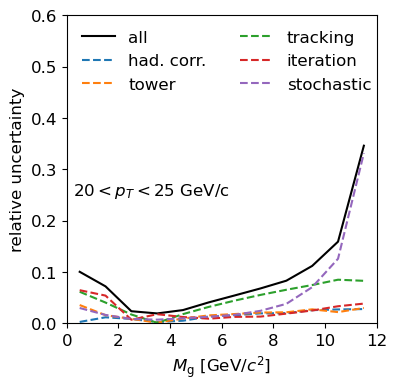

In [91]:
plt.figure(figsize=(4,4))

plt.plot(x, (err/y_arr[1]), color='k', label='all')
plt.plot(x, (err3/y_arr[1]), '--', label='had. corr.')
plt.plot(x, (err2/y_arr[1]), '--', label='tower')
plt.plot(x, (err1/y_arr[1]), '--', label='tracking')
# plt.plot(x, (err4/y_arr[1]), '--', label='Herwig')
# plt.plot(x, (err5/y_arr[1]), '--', label='Pythia8')
plt.plot(x, (err7/y_arr[1]), '--', label='iteration')
plt.plot(x, (err6/y_arr[1]), '--', label='stochastic')

plt.ylabel('relative uncertainty')
plt.xlabel('$M_{\mathrm{g}}$ [GeV/$c^2$]')
plt.legend(frameon=False, loc='upper left', ncol=2)
#plt.text(0.25,0.22,'$p$+$p$ $\sqrt{s}=200$ GeV\nanti-$k_\mathrm{T}$, $R=0.4$')
plt.text(0.25,0.25,'$20<p_T<25$ GeV/c')
plt.xlim(0,12)
plt.ylim(0,0.6)

In [92]:
mean_20_25 = y_arr[1]
err_20_25 = err
print(mean_20_25)
print(err_20_25)

[4.24690184e-02 1.31872488e-01 2.13920960e-01 2.25337168e-01
 1.80569456e-01 1.14295670e-01 5.90238165e-02 2.34072104e-02
 7.00484562e-03 1.68835577e-03 3.66866415e-04 4.41452907e-05]
[4.25442231e-03 9.46727315e-03 4.99984678e-03 4.29895006e-03
 4.63014469e-03 4.64836950e-03 3.19452338e-03 1.58687893e-03
 5.80372784e-04 1.88511046e-04 5.82916383e-05 1.52666366e-05]


In [93]:
x, y_arr, err_arr = process_ob_nom(1)
# x, y_arr_hw, err_arr_hw = process_ob_hw(1)
# x, y_arr_py8, err_arr_py8 = process_ob_py8(1)
x, y_arr_eff096, err_arr_eff096 = process_ob_detector(1, "eff096", df1_eff096)
x, y_arr_tow104, err_arr_tow104 = process_ob_detector(1, "tow104", df1_tow104)
x, y_arr_hadcorr05, err_arr_hadcorr05 = process_ob_detector(1, "hadcorr05", df1_hadcorr05)

observable: mg


iteration 1
relative uncertainty from NN: [0.00412661 0.00191261 0.00104438 0.00069409 0.00075793 0.0012738
 0.00185892 0.00233981 0.00282838 0.00332431 0.00387538 0.00425334]
relative uncertainty from stat: [0.01202064 0.00638712 0.00540277 0.00537382 0.00580497 0.00689711
 0.00861991 0.01175852 0.01963415 0.03030651 0.06087153 0.10643519]
total (stat + NN + MC bootstrap + data bootstrap): [0.01270924 0.00666734 0.00550279 0.00541846 0.00585424 0.00701375
 0.00881807 0.01198905 0.01983682 0.03048828 0.06099476 0.10652014]
iteration 2
relative uncertainty from NN: [0.00363914 0.00194414 0.00100986 0.00070904 0.00083553 0.00115129
 0.00161511 0.00211903 0.00268314 0.00328462 0.00392642 0.00442443]
relative uncertainty from stat: [0.01204985 0.00640371 0.00541303 0.00538257 0.00581088 0.00690542
 0.0086108  0.01175424 0.01970241 0.03027866 0.06074823 0.10687729]
relative uncertainty from MC bootstrap: [0.02541719 0.01499541 0.00770714 0.00683251 0.00715606 0.01100636
 0.01290671 0.016681

In [ ]:
err1 = abs(np.array(y_arr[1])-np.array(y_arr_eff096[0]))
err2 = abs(np.array(y_arr[1])-np.array(y_arr_tow104[0]))
err3 = abs(np.array(y_arr[1])-np.array(y_arr_hadcorr05[0]))
err4 = np.zeros_like(err1)
err5 = np.zeros_like(err1)
err6 = err_arr[1]
delta_y = []
for it in range(2,7):
    delta_y.append(abs(y_arr[it-1] - y_arr[1]))
err7 = np.max(delta_y, axis=0)

err = []
for i in range(0,len(err1)):
    err.append( np.sqrt( (err1[i])**2 + (err2[i])**2 + (err3[i])**2 + (max(abs(err4[i]),abs(err5[i])))**2 + (err6[i])**2 ) )
err = np.array(err)

In [95]:
mean_25_30 = y_arr[1]
err_25_30 = err
print(mean_25_30)
print(err_25_30)

[0.04025922 0.12401021 0.19944407 0.20357742 0.16739475 0.12317918
 0.07735344 0.04024868 0.016738   0.00586162 0.00155907 0.00037434]
[3.47484075e-03 6.16381797e-03 5.17026016e-03 2.17609133e-03
 2.93612744e-03 4.39371604e-03 3.95211543e-03 2.54060100e-03
 1.33199887e-03 5.64926006e-04 2.02814256e-04 6.87119481e-05]


In [96]:
x, y_arr, err_arr = process_ob_nom(2)
# x, y_arr_hw, err_arr_hw = process_ob_hw(2)
# x, y_arr_py8, err_arr_py8 = process_ob_py8(2)
x, y_arr_eff096, err_arr_eff096 = process_ob_detector(2, "eff096", df1_eff096)
x, y_arr_tow104, err_arr_tow104 = process_ob_detector(2, "tow104", df1_tow104)
x, y_arr_hadcorr05, err_arr_hadcorr05 = process_ob_detector(2, "hadcorr05", df1_hadcorr05)

observable: mg
iteration 1
relative uncertainty from NN: [0.00413442 0.00233948 0.00142909 0.00104202 0.00089718 0.00133006
 0.00226765 0.00316029 0.00386259 0.00454907 0.00510956 0.00586632]
relative uncertainty from stat: [0.01572164 0.00807396 0.00668071 0.00680531 0.00746418 0.00855124
 0.01025072 0.0125674  0.01684167 0.02326873 0.03541376 0.06915076]
total (stat + NN + MC bootstrap + data bootstrap): [0.01625618 0.00840607 0.00683185 0.00688462 0.0075179  0.00865406
 0.01049855 0.01295867 0.01727893 0.02370923 0.03578047 0.06939915]
iteration 2
relative uncertainty from NN: [0.00405503 0.00248621 0.00146838 0.00113911 0.00111665 0.00140765
 0.00208323 0.00290641 0.00366085 0.004497   0.00518767 0.00607449]
relative uncertainty from stat: [0.01579682 0.0081088  0.00664765 0.00683659 0.00750817 0.00860109
 0.01023844 0.01262992 0.01686031 0.02337325 0.03577904 0.06953561]
relative uncertainty from MC bootstrap: [0.0319286  0.0151126  0.00972088 0.00883064 0.00968238 0.01225852
 0.0

In [ ]:
err1 = abs(np.array(y_arr[1])-np.array(y_arr_eff096[0]))
err2 = abs(np.array(y_arr[1])-np.array(y_arr_tow104[0]))
err3 = abs(np.array(y_arr[1])-np.array(y_arr_hadcorr05[0]))
err4 = np.zeros_like(err1)
err5 = np.zeros_like(err1)
err6 = err_arr[1]
delta_y = []
for it in range(2,7):
    delta_y.append(abs(y_arr[it-1] - y_arr[1]))
err7 = np.max(delta_y, axis=0)

err = []
for i in range(0,len(err1)):
    err.append( np.sqrt( (err1[i])**2 + (err2[i])**2 + (err3[i])**2 + (max(abs(err4[i]),abs(err5[i])))**2 + (err6[i])**2 ) )
err = np.array(err)

In [98]:
mean_30_40 = y_arr[1]
err_30_40 = err
print(mean_30_40)
print(err_30_40)

[0.03815455 0.12076299 0.18952076 0.18995328 0.1551995  0.11729189
 0.08415466 0.05374321 0.03087298 0.01334288 0.00524853 0.00175478]
[0.00368754 0.00666456 0.00566766 0.00298379 0.00251534 0.00394211
 0.00426816 0.00352818 0.00241251 0.00122483 0.00059576 0.00026088]


In [99]:
x, y_arr, err_arr = process_ob_nom(3)
# x, y_arr_hw, err_arr_hw = process_ob_hw(3)
# x, y_arr_py8, err_arr_py8 = process_ob_py8(3)
x, y_arr_eff096, err_arr_eff096 = process_ob_detector(3, "eff096", df1_eff096)
x, y_arr_tow104, err_arr_tow104 = process_ob_detector(3, "tow104", df1_tow104)
x, y_arr_hadcorr05, err_arr_hadcorr05 = process_ob_detector(3, "hadcorr05", df1_hadcorr05)

observable: mg


iteration 1
relative uncertainty from NN: [0.0043987  0.00324854 0.00233949 0.00182868 0.00161643 0.00181429
 0.00275662 0.00432833 0.00592743 0.00710515 0.00831614 0.00941712]
relative uncertainty from stat: [0.02459017 0.01074055 0.00884812 0.00973973 0.01056371 0.01304713
 0.01534583 0.01768361 0.02347099 0.03076356 0.03502241 0.03897053]
total (stat + NN + MC bootstrap + data bootstrap): [0.02498049 0.01122107 0.00915218 0.00990991 0.01068666 0.01317267
 0.01559146 0.01820562 0.02420789 0.0315734  0.03599622 0.04009219]
iteration 2
relative uncertainty from NN: [0.00550823 0.00428174 0.00302981 0.00252701 0.00244803 0.0026055
 0.00341403 0.0050671  0.00685201 0.0081122  0.00951376 0.01087757]
relative uncertainty from stat: [0.02453771 0.01075644 0.00877828 0.00988945 0.01066198 0.01291007
 0.01544954 0.01796146 0.02446916 0.0302878  0.03432819 0.03936193]
relative uncertainty from MC bootstrap: [0.04038344 0.0253197  0.02079422 0.01631615 0.01349228 0.01683165
 0.02311992 0.035136

In [ ]:
err1 = abs(np.array(y_arr[1])-np.array(y_arr_eff096[0]))
err2 = abs(np.array(y_arr[1])-np.array(y_arr_tow104[0]))
err3 = abs(np.array(y_arr[1])-np.array(y_arr_hadcorr05[0]))
err4 = np.zeros_like(err1)
err5 = np.zeros_like(err1)
err6 = err_arr[1]

delta_y = []
for it in range(2,7): 
    delta_y.append( abs(y_arr[it-1]-y_arr[1]) )
err7 = np.max(delta_y,axis=0)

err = []
for i in range(0,len(err1)):
    err.append( np.sqrt( (err1[i])**2 + (err2[i])**2 + (err3[i])**2 + (max(abs(err4[i]), abs(err5[i]), abs(err7[i])))**2 + (err6[i])**2 ) )
err = np.array(err)

<>:13: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:13: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/4256110067.py:13: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
  plt.xlabel('$M_{\mathrm{g}}$ [GeV/$c^2$]')


(0.0, 0.6)

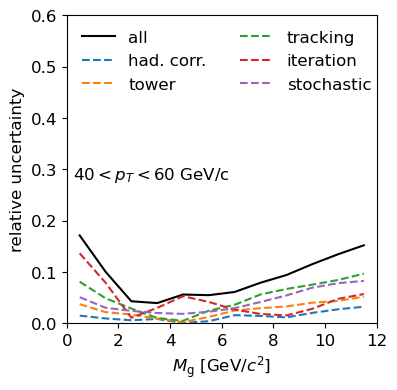

In [101]:
plt.figure(figsize=(4,4))

plt.plot(x, (err/y_arr[1]), color='k', label='all')
plt.plot(x, (err3/y_arr[1]), '--', label='had. corr.')
plt.plot(x, (err2/y_arr[1]), '--', label='tower')
plt.plot(x, (err1/y_arr[1]), '--', label='tracking')
# plt.plot(x, (err4/y_arr[1]), '--', label='Herwig')
# plt.plot(x, (err5/y_arr[1]), '--', label='Pythia8')
plt.plot(x, (err7/y_arr[1]), '--', label='iteration')
plt.plot(x, (err6/y_arr[1]), '--', label='stochastic')

plt.ylabel('relative uncertainty')
plt.xlabel('$M_{\mathrm{g}}$ [GeV/$c^2$]')
plt.legend(frameon=False, loc='upper left', ncol=2)
#plt.text(0.25,0.22,'$p$+$p$ $\sqrt{s}=200$ GeV\nanti-$k_\mathrm{T}$, $R=0.4$')
plt.text(0.25,0.28,'$40<p_T<60$ GeV/c')
plt.xlim(0,12)
plt.ylim(0,0.6)

In [102]:
mean_40_60 = y_arr[1]
err_40_60 = err

### Fig 7.13

<>:9: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:10: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:16: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:18: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:28: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:34: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:47: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will

([<matplotlib.axis.XTick at 0x145b848ca850>,
 [Text(0, 0, '0'),
  Text(2, 0, '2'),
  Text(4, 0, '4'),
  Text(6, 0, '6'),
  Text(8, 0, '8'),
  Text(10, 0, '10'),
  Text(12, 0, '12')])

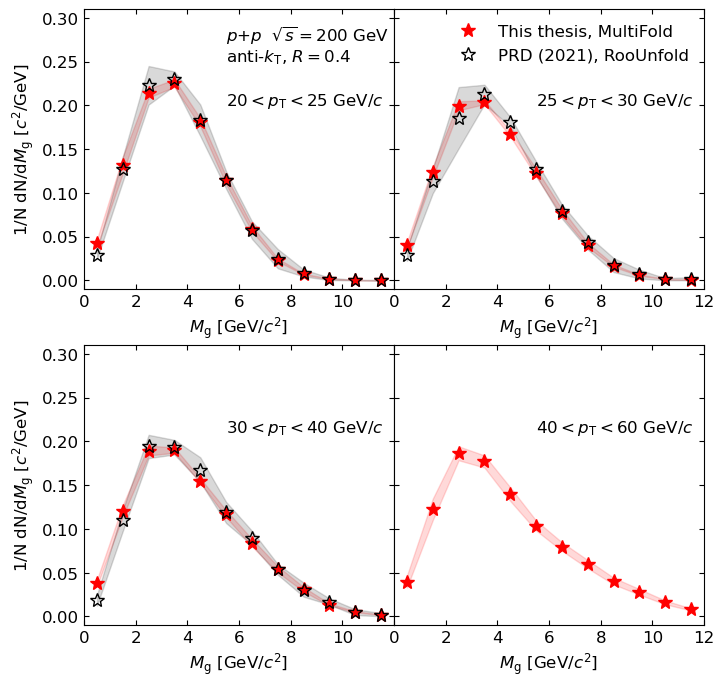

In [103]:
gs1 = gridspec.GridSpec(2,2,width_ratios=(1,1), height_ratios=(5,5))

fig = plt.figure(figsize=(8,8))
plt.subplots_adjust(wspace=0)

x = np.arange(0.5,12.5)

ax1 = fig.add_subplot(gs1[0])
plt.text(5.5,0.25,'$p$+$p$  $\sqrt{s}=200$ GeV\nanti-$k_\mathrm{T}$, $R=0.4$', fontsize=12)
plt.text(5.5,0.2,'$20 < p_\mathrm{T} < 25$ GeV/$c$', fontsize=12)
plt.plot(x, mean_20_25, color='red', marker='*', ls='none', markersize=10, label='MultiFold')
plt.fill_between(x, mean_20_25-err_20_25, mean_20_25+err_20_25, color='r', alpha=0.15)
plt.fill_between(x+0, mean_20_25_isaac-err_20_25_isaac, mean_20_25_isaac+err_20_25_isaac, color='k', alpha=0.15)
plt.plot(x+0, mean_20_25_isaac, label='PRD (2021), RooUnfold', ls='none', marker='*', markersize=10, color='none', mec='k')
plt.xlim(left=0, right=12)
plt.xlabel('$M_{\mathrm{g}}$ [GeV/$c^2$]')
plt.ylim(-0.01,0.31)
plt.ylabel('1/N dN/d$M_{\mathrm{g}}$ [$c^2$/GeV]')
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')
# ax.axes.xaxis.set_minor_locator(MultipleLocator(0.5))
# ax.axes.xaxis.set_major_locator(MultipleLocator(2))
# ax.axes.yaxis.set_minor_locator(MultipleLocator(0.01))
# ax.axes.yaxis.set_major_locator(MultipleLocator(0.05))
plt.xticks(np.arange(0,12,2))

ax2 = fig.add_subplot(gs1[1])
plt.text(5.5,0.2,'$25 < p_\mathrm{T} < 30$ GeV/$c$', fontsize=12)
plt.plot(x, mean_25_30, color='red', marker='*', ls='none', markersize=10, label='This thesis, MultiFold')
plt.fill_between(x, mean_25_30-err_25_30, mean_25_30+err_25_30, color='r', alpha=0.15)
plt.fill_between(x+0, mean_25_30_isaac-err_25_30_isaac, mean_25_30_isaac+err_25_30_isaac, color='k', alpha=0.15)
plt.plot(x+0, mean_25_30_isaac, label='PRD (2021), RooUnfold', ls='none', marker='*', markersize=10, color='none', mec='k')
plt.xlim(left=0, right=12)
plt.xlabel('$M_{\mathrm{g}}$ [GeV/$c^2$]')
plt.ylim(-0.01,0.31)
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')
ax.axes.yaxis.set_ticklabels([])
# ax.axes.xaxis.set_minor_locator(MultipleLocator(0.5))
# ax.axes.xaxis.set_major_locator(MultipleLocator(2))
# ax.axes.yaxis.set_minor_locator(MultipleLocator(0.01))
# ax.axes.yaxis.set_major_locator(MultipleLocator(0.05))
plt.legend(frameon=False, fontsize=12, loc='upper right')
plt.xticks(np.arange(0,14,2))

ax3 = fig.add_subplot(gs1[2])
plt.text(5.5,0.21,'$30 < p_\mathrm{T} < 40$ GeV/$c$', fontsize=12)
plt.plot(x, mean_30_40, color='red', marker='*', ls='none', markersize=10, label='MultiFold')
plt.fill_between(x, mean_30_40-err_30_40, mean_30_40+err_30_40, color='r', alpha=0.15)
plt.fill_between(x+0, mean_30_40_isaac[:-2]-err_30_40_isaac[:-2], mean_30_40_isaac[:-2]+err_30_40_isaac[:-2], color='k', alpha=0.15)
plt.plot(x+0, mean_30_40_isaac[:-2], label='PRD (2021), RooUnfold', ls='none', marker='*', markersize=10, color='none', mec='k')
plt.xlim(left=0, right=12)
plt.xlabel('$M_{\mathrm{g}}$ [GeV/$c^2$]')
plt.ylabel('1/N dN/d$M_{\mathrm{g}}$ [$c^2$/GeV]')
plt.ylim(-0.01,0.31)
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')
# ax.axes.xaxis.set_minor_locator(MultipleLocator(0.5))
# ax.axes.xaxis.set_major_locator(MultipleLocator(2))
# ax.axes.yaxis.set_minor_locator(MultipleLocator(0.01))
# ax.axes.yaxis.set_major_locator(MultipleLocator(0.05))
plt.xticks(np.arange(0.,12,2))

ax4 = fig.add_subplot(gs1[3])
plt.text(5.5,0.21,'$40 < p_\mathrm{T} < 60$ GeV/$c$', fontsize=12)
plt.plot(x, mean_40_60, color='red', marker='*', ls='none', markersize=10, label='MultiFold')
plt.fill_between(x, mean_40_60-err_40_60, mean_40_60+err_40_60, color='r', alpha=0.15)
plt.xlim(left=0, right=12)
plt.xlabel('$M_{\mathrm{g}}$ [GeV/$c^2$]')
plt.ylim(-0.01,0.31)
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')
ax.axes.yaxis.set_ticklabels([])
# ax.axes.xaxis.set_minor_locator(MultipleLocator(0.5))
# ax.axes.xaxis.set_major_locator(MultipleLocator(2))
# ax.axes.yaxis.set_minor_locator(MultipleLocator(0.01))
# ax.axes.yaxis.set_major_locator(MultipleLocator(0.05))
plt.xticks(np.arange(0,14,2))

# $R_g$

In [ ]:
mean_20_25_rithya = np.array([0.503,1.37,2.681,3.682,3.613,3.467,3.006,1.614,0.063])
err_stat_20_25_rithya = np.array([0.014,0.019,0.029,0.029,0.028,0.023,0.026,0.021,0.002])
err_sys_20_25_rithya = np.array([0.217,0.304,0.265,0.124,0.081,0.257,0.3,0.141,0.029])
err_20_25_rithya = np.sqrt(err_stat_20_25_rithya**2 + err_sys_20_25_rithya**2)

In [ ]:
mean_25_30_rithya = np.array([0.774,1.982,3.491,4.252,3.4,2.772,2.099,1.16,0.066])
err_stat_25_30_rithya = np.array([0.037,0.043,0.062,0.059,0.06,0.046,0.04,0.033,0.005])
err_sys_25_30_rithya = np.array([0.3,0.295,0.286,0.191,0.203,0.325,0.23,0.138,0.036])
err_25_30_rithya = np.sqrt(err_stat_25_30_rithya**2 + err_sys_25_30_rithya**2)

In [ ]:
mean_30_40_rithya = np.array([0.962,3.056,4.334,4.02,3.088,2.268,1.499,0.745,0.029])
err_stat_30_40_rithya = np.array([0.048,0.09,0.1,0.101,0.086,0.07,0.049,0.042,0.001])
err_sys_30_40_rithya = np.array([0.146,0.368,0.244,0.14,0.223,0.136,0.129,0.131,0.029])
err_30_40_rithya = np.sqrt(err_stat_30_40_rithya**2 + err_sys_30_40_rithya**2)

In [ ]:
mean_40_60_rithya = np.array([1.503,5.544,3.957,3.729,2.441,1.656,0.734,0.43,0.006])
err_stat_40_60_rithya = np.array([0.176,0.465,0.323,0.45,0.363,0.274,0.17,0.134,0.001])
err_sys_40_60_rithya = np.array([0.335,0.763,0.351,0.522,0.328,0.295,0.315,0.227,0.025])
err_40_60_rithya = np.sqrt(err_stat_40_60_rithya**2 + err_sys_40_60_rithya**2)

In [107]:
obs = ['rg','rg','rg','rg']
binedgess = [np.arange(0,0.45,0.05),np.arange(0,0.45,0.05),np.arange(0,0.45,0.05),np.arange(0,0.45,0.05)]
cuts = ['20<pt<25', '25<pt<30', '30<pt<40', '40<pt<60']

In [109]:
x, y_arr, err_arr = process_ob_nom(0)
# x, y_arr_hw, err_arr_hw = process_ob_hw(0)
# x, y_arr_py8, err_arr_py8 = process_ob_py8(0)
x, y_arr_eff096, err_arr_eff096 = process_ob_detector(0, "eff096", df1_eff096)
x, y_arr_tow104, err_arr_tow104 = process_ob_detector(0, "tow104", df1_tow104)
x, y_arr_hadcorr05, err_arr_hadcorr05 = process_ob_detector(0, "hadcorr05", df1_hadcorr05)

observable: rg
iteration 1
relative uncertainty from NN: [0.0030176  0.00226419 0.00147295 0.00090673 0.00063761 0.00079107
 0.00147908 0.00229269]
relative uncertainty from stat: [0.0178781  0.0072386  0.00525529 0.00462303 0.0046609  0.0046164
 0.00497436 0.00708208]
total (stat + NN + MC bootstrap + data bootstrap): [0.01813098 0.00758445 0.00545781 0.00471111 0.00470431 0.00468369
 0.00518959 0.00744394]
iteration 2
relative uncertainty from NN: [0.00313432 0.0020644  0.00125865 0.00084635 0.0005874  0.00073007
 0.00123725 0.00212025]
relative uncertainty from stat: [0.01794214 0.00726009 0.00528022 0.00463931 0.00466917 0.00461616
 0.00497741 0.00707192]
relative uncertainty from MC bootstrap: [0.02924562 0.01692665 0.01051761 0.00615882 0.00580924 0.00706851
 0.0095937  0.01497613]
relative uncertainty from data bootstrap: [0.01554595 0.01318618 0.0087802  0.00508678 0.00185981 0.00511957
 0.00887158 0.01216286]
total (stat + NN + MC bootstrap + data bootstrap): [0.03779851 0.022

In [ ]:
err1 = abs(np.array(y_arr[1])-np.array(y_arr_eff096[0]))
err2 = abs(np.array(y_arr[1])-np.array(y_arr_tow104[0]))
err3 = abs(np.array(y_arr[1])-np.array(y_arr_hadcorr05[0]))
err4 = np.zeros_like(err1)
err5 = np.zeros_like(err1)
err6 = err_arr[1]

delta_y = []
for it in range(2,7): 
    delta_y.append( abs(y_arr[it-1]-y_arr[1]) )
err7 = np.max(delta_y,axis=0)

err = []
for i in range(0,len(err1)):
    err.append( np.sqrt( (err1[i])**2 + (err2[i])**2 + (err3[i])**2 + (max(abs(err4[i]), abs(err5[i]), abs(err7[i])))**2 + (err6[i])**2 ) )
err = np.array(err)

<>:13: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:13: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/1662029045.py:13: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
  plt.xlabel('$R_{\mathrm{g}}$')


(0.0, 0.6)

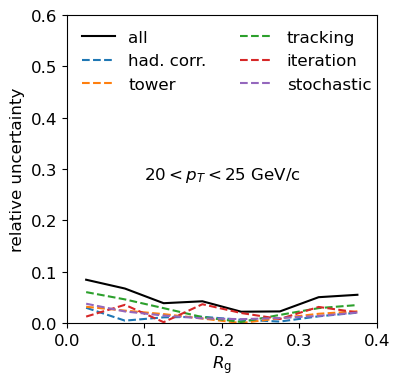

In [111]:
plt.figure(figsize=(4,4))

plt.plot(x, (err/y_arr[1]), color='k', label='all')
plt.plot(x, (err3/y_arr[1]), '--', label='had. corr.')
plt.plot(x, (err2/y_arr[1]), '--', label='tower')
plt.plot(x, (err1/y_arr[1]), '--', label='tracking')
# plt.plot(x, (err4/y_arr[1]), '--', label='Herwig')
# plt.plot(x, (err5/y_arr[1]), '--', label='Pythia8')
plt.plot(x, (err7/y_arr[1]), '--', label='iteration')
plt.plot(x, (err6/y_arr[1]), '--', label='stochastic')

plt.ylabel('relative uncertainty')
plt.xlabel('$R_{\mathrm{g}}$')
plt.legend(frameon=False, loc='upper left', ncol=2)
#plt.text(0.25,0.22,'$p$+$p$ $\sqrt{s}=200$ GeV\nanti-$k_\mathrm{T}$, $R=0.4$')
plt.text(0.1,0.28,'$20<p_T<25$ GeV/c')
plt.xlim(0,0.4)
plt.ylim(0,0.6)

In [112]:
mean_20_25 = y_arr[1]
err_20_25 = err
print(mean_20_25)
print(err_20_25)

[0.3093559  1.44836793 2.80230745 3.62103372 3.67876153 3.51273214
 2.96957743 1.65786391]
[0.02615137 0.09759603 0.10873615 0.15407555 0.08177566 0.08011125
 0.14999808 0.09151874]


In [113]:
x, y_arr, err_arr = process_ob_nom(1)
# x, y_arr_hw, err_arr_hw = process_ob_hw(1)
# x, y_arr_py8, err_arr_py8 = process_ob_py8(1)
x, y_arr_eff096, err_arr_eff096 = process_ob_detector(1, "eff096", df1_eff096)
x, y_arr_tow104, err_arr_tow104 = process_ob_detector(1, "tow104", df1_tow104)
x, y_arr_hadcorr05, err_arr_hadcorr05 = process_ob_detector(1, "hadcorr05", df1_hadcorr05)

observable: rg
iteration 1
relative uncertainty from NN: [0.00314688 0.00225091 0.00132195 0.00082674 0.00073847 0.00116382
 0.00212147 0.00319097]
relative uncertainty from stat: [0.01658856 0.00726721 0.00549181 0.00541669 0.00585839 0.00606724
 0.00715891 0.01089817]
total (stat + NN + MC bootstrap + data bootstrap): [0.0168844  0.00760782 0.00564868 0.00547942 0.00590475 0.00617785
 0.00746664 0.01135572]
iteration 2
relative uncertainty from NN: [0.00342973 0.00222001 0.00122612 0.00081762 0.00077853 0.00109902
 0.00186596 0.00312017]
relative uncertainty from stat: [0.0166322  0.0072905  0.0055086  0.00543915 0.00586782 0.00608369
 0.00716349 0.01085145]
relative uncertainty from MC bootstrap: [0.02603255 0.01639092 0.00906323 0.00715481 0.00736127 0.00915076
 0.01338009 0.02321569]
relative uncertainty from data bootstrap: [0.01393167 0.00999099 0.00521847 0.00284818 0.00195489 0.00485441
 0.00854269 0.01350508]
total (stat + NN + MC bootstrap + data bootstrap): [0.03406139 0.02

In [ ]:
err1 = abs(np.array(y_arr[1])-np.array(y_arr_eff096[0]))
err2 = abs(np.array(y_arr[1])-np.array(y_arr_tow104[0]))
err3 = abs(np.array(y_arr[1])-np.array(y_arr_hadcorr05[0]))
err4 = np.zeros_like(err1)
err5 = np.zeros_like(err1)
err6 = err_arr[1]
delta_y = []
for it in range(2,7):
    delta_y.append(abs(y_arr[it-1] - y_arr[1]))
err7 = np.max(delta_y, axis=0)

err = []
for i in range(0,len(err1)):
    err.append( np.sqrt( (err1[i])**2 + (err2[i])**2 + (err3[i])**2 + (max(abs(err4[i]),abs(err5[i])))**2 + (err6[i])**2 ) )
err = np.array(err)

In [115]:
mean_25_30 = y_arr[1]
err_25_30 = err
print(mean_25_30)
print(err_25_30)

[0.45343146 2.17410715 3.72337072 3.95321897 3.39878272 2.97195821
 2.21800405 1.10712673]
[0.03701499 0.12445371 0.11613533 0.06399424 0.05058079 0.09531035
 0.1124634  0.06639742]


In [116]:
x, y_arr, err_arr = process_ob_nom(2)
# x, y_arr_hw, err_arr_hw = process_ob_hw(2)
# x, y_arr_py8, err_arr_py8 = process_ob_py8(2)
x, y_arr_eff096, err_arr_eff096 = process_ob_detector(2, "eff096", df1_eff096)
x, y_arr_tow104, err_arr_tow104 = process_ob_detector(2, "tow104", df1_tow104)
x, y_arr_hadcorr05, err_arr_hadcorr05 = process_ob_detector(2, "hadcorr05", df1_hadcorr05)

observable: rg
iteration 1
relative uncertainty from NN: [0.00338658 0.00230719 0.00139826 0.00096691 0.00105887 0.00207438
 0.00348197 0.00502212]
relative uncertainty from stat: [0.01554459 0.00709553 0.00606645 0.00675454 0.00772803 0.00851669
 0.01035318 0.01612517]
total (stat + NN + MC bootstrap + data bootstrap): [0.01590922 0.00746121 0.0062255  0.0068234  0.00780024 0.00876567
 0.01092302 0.01688913]
iteration 2
relative uncertainty from NN: [0.0036599  0.00226911 0.00139749 0.00110841 0.00123842 0.00201407
 0.00327505 0.00492853]
relative uncertainty from stat: [0.01558523 0.00712387 0.00611848 0.00677074 0.00774007 0.00854763
 0.01042203 0.01597934]
relative uncertainty from MC bootstrap: [0.02532464 0.0149495  0.00931551 0.00795552 0.00906883 0.01304146
 0.0219604  0.03321165]
relative uncertainty from data bootstrap: [0.01146436 0.00661661 0.00357377 0.00260305 0.00253183 0.00540433
 0.01004392 0.01666949]
total (stat + NN + MC bootstrap + data bootstrap): [0.03207902 0.01

In [ ]:
err1 = abs(np.array(y_arr[1])-np.array(y_arr_eff096[0]))
err2 = abs(np.array(y_arr[1])-np.array(y_arr_tow104[0]))
err3 = abs(np.array(y_arr[1])-np.array(y_arr_hadcorr05[0]))
err4 = np.zeros_like(err1)
err5 = np.zeros_like(err1)
err6 = err_arr[1]
delta_y = []
for it in range(2,7):
    delta_y.append(abs(y_arr[it-1] - y_arr[1]))
err7 = np.max(delta_y, axis=0)

err = []
for i in range(0,len(err1)):
    err.append( np.sqrt( (err1[i])**2 + (err2[i])**2 + (err3[i])**2 + (max(abs(err4[i]),abs(err5[i])))**2 + (err6[i])**2 ) )
err = np.array(err)

In [118]:
mean_30_40 = y_arr[1]
err_30_40 = err
print(mean_30_40)
print(err_30_40)

[0.71641297 3.18725073 4.44191901 3.90980541 2.97711551 2.36982011
 1.64932051 0.74835576]
[0.05980002 0.16568353 0.11868471 0.05295976 0.08001114 0.10432302
 0.0975267  0.05466128]


In [119]:
x, y_arr, err_arr = process_ob_nom(3)
# x, y_arr_hw, err_arr_hw = process_ob_hw(3)
# x, y_arr_py8, err_arr_py8 = process_ob_py8(3)
x, y_arr_eff096, err_arr_eff096 = process_ob_detector(3, "eff096", df1_eff096)
x, y_arr_tow104, err_arr_tow104 = process_ob_detector(3, "tow104", df1_tow104)
x, y_arr_hadcorr05, err_arr_hadcorr05 = process_ob_detector(3, "hadcorr05", df1_hadcorr05)

observable: rg
iteration 1
relative uncertainty from NN: [0.00388831 0.00261813 0.00173522 0.00150435 0.00248006 0.00467362
 0.00695247 0.00922164]
relative uncertainty from stat: [0.01493021 0.00724196 0.00792558 0.01030323 0.01341329 0.01651087
 0.02102306 0.03059692]
total (stat + NN + MC bootstrap + data bootstrap): [0.01542823 0.00770069 0.00811331 0.01041247 0.01364064 0.01715959
 0.02214285 0.03195638]
iteration 2
relative uncertainty from NN: [0.0050673  0.00326732 0.00242024 0.00263331 0.00331835 0.00561156
 0.00827191 0.01097558]
relative uncertainty from stat: [0.01518518 0.0072995  0.00782127 0.01030713 0.01359495 0.01642866
 0.02076053 0.03024755]
relative uncertainty from MC bootstrap: [0.03144614 0.02047946 0.0164085  0.01277781 0.02298328 0.03917564
 0.05315291 0.06874414]
relative uncertainty from data bootstrap: [0.01482751 0.00877065 0.00470234 0.00617769 0.00867587 0.01172282
 0.01605546 0.02189383]
total (stat + NN + MC bootstrap + data bootstrap): [0.03827508 0.02

In [ ]:
err1 = abs(np.array(y_arr[1])-np.array(y_arr_eff096[0]))
err2 = abs(np.array(y_arr[1])-np.array(y_arr_tow104[0]))
err3 = abs(np.array(y_arr[1])-np.array(y_arr_hadcorr05[0]))
err4 = np.zeros_like(err1)
err5 = np.zeros_like(err1)
err6 = err_arr[1]

delta_y = []
for it in range(2,7): 
    delta_y.append( abs(y_arr[it-1]-y_arr[1]) )
err7 = np.max(delta_y,axis=0)

err = []
for i in range(0,len(err1)):
    err.append( np.sqrt( (err1[i])**2 + (err2[i])**2 + (err3[i])**2 + (max(abs(err4[i]), abs(err5[i]), abs(err7[i])))**2 + (err6[i])**2 ) )
err = np.array(err)

<>:13: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:13: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/1975866481.py:13: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
  plt.xlabel('$R_{\mathrm{g}}$')


(0.0, 0.6)

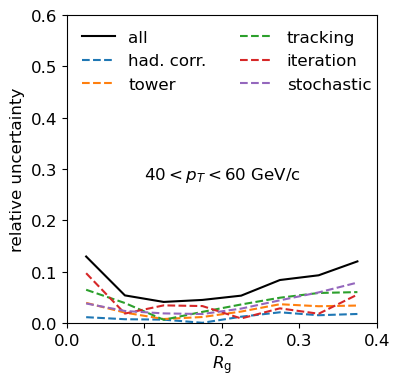

In [121]:
plt.figure(figsize=(4,4))

plt.plot(x, (err/y_arr[1]), color='k', label='all')
plt.plot(x, (err3/y_arr[1]), '--', label='had. corr.')
plt.plot(x, (err2/y_arr[1]), '--', label='tower')
plt.plot(x, (err1/y_arr[1]), '--', label='tracking')
# plt.plot(x, (err4/y_arr[1]), '--', label='Herwig')
# plt.plot(x, (err5/y_arr[1]), '--', label='Pythia8')
plt.plot(x, (err7/y_arr[1]), '--', label='iteration')
plt.plot(x, (err6/y_arr[1]), '--', label='stochastic')

plt.ylabel('relative uncertainty')
plt.xlabel('$R_{\mathrm{g}}$')
plt.legend(frameon=False, loc='upper left', ncol=2)
#plt.text(0.25,0.22,'$p$+$p$ $\sqrt{s}=200$ GeV\nanti-$k_\mathrm{T}$, $R=0.4$')
plt.text(0.1,0.28,'$40<p_T<60$ GeV/c')
plt.xlim(0,0.4)
plt.ylim(0,0.6)

In [122]:
mean_40_60 = y_arr[1]
err_40_60 = err
print(mean_40_60)
print(err_40_60)

[1.43520827 5.036192   4.88185309 3.32147372 2.19668166 1.61466539
 1.04496212 0.46896375]
[0.1862079  0.27198193 0.20158554 0.15007135 0.11758203 0.13557851
 0.09737366 0.05639995]


### Fig 7.14

<>:9: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:10: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:16: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:18: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:28: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:34: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:47: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will

([<matplotlib.axis.XTick at 0x145b56769f90>,
 [Text(0.0, 0, '0.0'),
  Text(0.1, 0, '0.1'),
  Text(0.2, 0, '0.2'),
  Text(0.30000000000000004, 0, '0.3'),
  Text(0.4, 0, '0.4')])

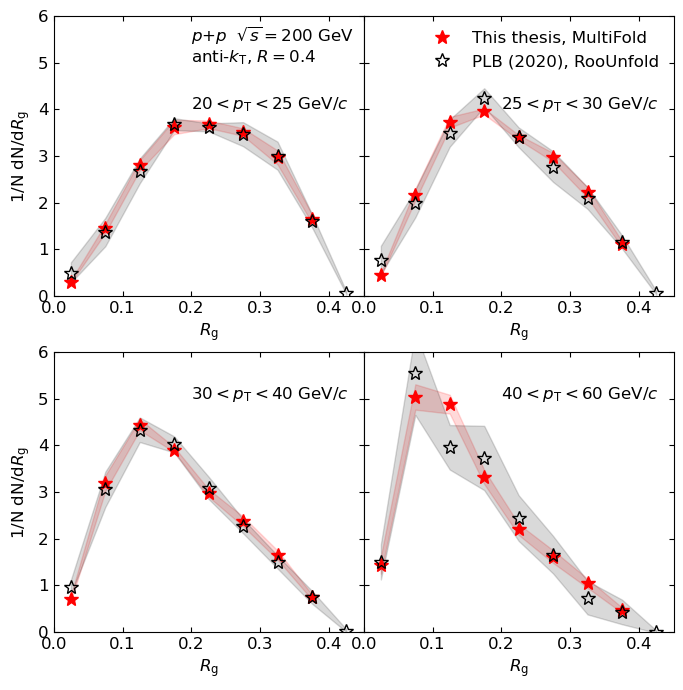

In [ ]:
gs1 = gridspec.GridSpec(2,2,width_ratios=(1,1), height_ratios=(5,5))

fig = plt.figure(figsize=(8,8))
plt.subplots_adjust(wspace=0)

x = np.arange(0.025,0.475,0.05)

ax1 = fig.add_subplot(gs1[0])
plt.text(0.2,5,'$p$+$p$  $\sqrt{s}=200$ GeV\nanti-$k_\mathrm{T}$, $R=0.4$', fontsize=12)
plt.text(0.2,4,'$20 < p_\mathrm{T} < 25$ GeV/$c$', fontsize=12)
plt.plot(x[:-1], mean_20_25, color='red', marker='*', ls='none', markersize=10)
plt.fill_between(x[:-1], mean_20_25-err_20_25, mean_20_25+err_20_25, color='r', alpha=0.15)
plt.fill_between(x+0, mean_20_25_rithya-err_20_25_rithya, mean_20_25_rithya+err_20_25_rithya, color='k', alpha=0.15)
plt.plot(x+0, mean_20_25_rithya, ls='none', marker='*', markersize=10, color='none', mec='k')
plt.xlim(left=0, right=0.45)
plt.xlabel('$R_{\mathrm{g}}$')
plt.ylim(0,6)
plt.ylabel('1/N dN/d$R_{\mathrm{g}}$')
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')
#ax.axes.xaxis.set_minor_locator(MultipleLocator(0.5))
#ax.axes.xaxis.set_major_locator(MultipleLocator(2))
#ax.axes.yaxis.set_minor_locator(MultipleLocator(0.01))
#ax.axes.yaxis.set_major_locator(MultipleLocator(0.05))
plt.xticks(np.arange(0,0.5,0.1))

ax2 = fig.add_subplot(gs1[1])
plt.text(0.2,4,'$25 < p_\mathrm{T} < 30$ GeV/$c$', fontsize=12)
plt.plot(x[:-1], mean_25_30, color='red', marker='*', ls='none', markersize=10, label='This thesis, MultiFold')
plt.fill_between(x[:-1], mean_25_30-err_25_30, mean_25_30+err_25_30, color='r', alpha=0.15)
plt.fill_between(x+0, mean_25_30_rithya-err_25_30_rithya, mean_25_30_rithya+err_25_30_rithya, color='k', alpha=0.15)
plt.plot(x+0, mean_25_30_rithya, label='PLB (2020), RooUnfold', ls='none', marker='*', markersize=10, color='none', mec='k')
plt.xlim(left=0, right=0.45)
plt.xlabel('$R_{\mathrm{g}}$')
plt.ylim(0,6)
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')
ax.axes.yaxis.set_ticklabels([])
#ax.axes.xaxis.set_minor_locator(MultipleLocator(0.5))
#ax.axes.xaxis.set_major_locator(MultipleLocator(2))
#ax.axes.yaxis.set_minor_locator(MultipleLocator(0.01))
#ax.axes.yaxis.set_major_locator(MultipleLocator(0.05))
plt.legend(frameon=False, fontsize=12, loc='upper right')
plt.xticks(np.arange(0,0.5,0.1))

ax3 = fig.add_subplot(gs1[2])
plt.text(0.2,5,'$30 < p_\mathrm{T} < 40$ GeV/$c$', fontsize=12)
plt.plot(x[:-1], mean_30_40, color='red', marker='*', ls='none', markersize=10)
plt.fill_between(x[:-1], mean_30_40-err_30_40, mean_30_40+err_30_40, color='r', alpha=0.15)
plt.fill_between(x+0, mean_30_40_rithya-err_30_40_rithya, mean_30_40_rithya+err_30_40_rithya, color='k', alpha=0.15)
plt.plot(x+0, mean_30_40_rithya, ls='none', marker='*', markersize=10, color='none', mec='k')
plt.xlim(left=0, right=0.45)
plt.xlabel('$R_{\mathrm{g}}$')
plt.ylabel('1/N dN/d$R_{\mathrm{g}}$')
plt.ylim(0,6)
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')
#ax.axes.xaxis.set_minor_locator(MultipleLocator(0.5))
#ax.axes.xaxis.set_major_locator(MultipleLocator(2))
#ax.axes.yaxis.set_minor_locator(MultipleLocator(0.01))
#ax.axes.yaxis.set_major_locator(MultipleLocator(0.05))
plt.xticks(np.arange(0,0.5,0.1))

ax4 = fig.add_subplot(gs1[3])
plt.text(0.2,5,'$40 < p_\mathrm{T} < 60$ GeV/$c$', fontsize=12)
plt.plot(x[:-1], mean_40_60, color='red', marker='*', ls='none', markersize=10)
plt.fill_between(x[:-1], mean_40_60-err_40_60, mean_40_60+err_40_60, color='r', alpha=0.15)
plt.fill_between(x+0, mean_40_60_rithya-err_40_60_rithya, mean_40_60_rithya+err_40_60_rithya, color='k', alpha=0.15)
plt.plot(x+0, mean_40_60_rithya, ls='none', marker='*', markersize=10, color='none', mec='k')
plt.xlim(left=0, right=0.45)
plt.xlabel('$R_{\mathrm{g}}$')
plt.ylim(0,6)
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')
ax.axes.yaxis.set_ticklabels([])
#ax.axes.xaxis.set_minor_locator(MultipleLocator(0.5))
#ax.axes.xaxis.set_major_locator(MultipleLocator(2))
#ax.axes.yaxis.set_minor_locator(MultipleLocator(0.01))
#ax.axes.yaxis.set_major_locator(MultipleLocator(0.05))
plt.xticks(np.arange(0,0.5,0.1))

# $z_g$

In [ ]:
mean_20_25_rithya = np.array([5.573,3.622,2.45,1.986,1.787,1.571,1.416,1.371])
err_stat_20_25_rithya = np.array([0.034,0.031,0.019,0.012,0.012,0.012,0.013,0.018])
err_sys_20_25_rithya = np.array([0.22,0.136,0.156,0.116,0.075,0.122,0.23,0.1])
err_20_25_rithya = np.sqrt(err_stat_20_25_rithya**2 + err_sys_20_25_rithya**2)

In [ ]:
mean_25_30_rithya = np.array([5.484,3.457,2.744,2.1,1.813,1.522,1.422,1.286])
err_stat_25_30_rithya = np.array([0.071,0.054,0.037,0.033,0.035,0.029,0.028,0.03])
err_sys_25_30_rithya = np.array([0.281,0.186,0.125,0.156,0.132,0.16,0.141,0.175])
err_25_30_rithya = np.sqrt(err_stat_25_30_rithya**2 + err_sys_25_30_rithya**2)

In [ ]:
mean_30_40_rithya = np.array([6.012,3.643,2.773,1.918,1.63,1.402,1.188,1.235])
err_stat_30_40_rithya = np.array([0.105,0.093,0.071,0.045,0.044,0.041,0.041,0.058])
err_sys_30_40_rithya = np.array([0.547,0.202,0.269,0.324,0.119,0.143,0.195,0.236])
err_30_40_rithya = np.sqrt(err_stat_30_40_rithya**2 + err_sys_30_40_rithya**2)

In [ ]:
mean_40_60_rithya = np.array([5.971,3.797,2.366,2.083,1.631,1.4,1.387,1.336])
err_stat_40_60_rithya = np.array([0.445,0.326,0.202,0.181,0.188,0.243,0.261,0.163])
err_sys_40_60_rithya = np.array([0.365,0.356,0.179,0.169,0.29,0.342,0.116,0.27])
err_40_60_rithya = np.sqrt(err_stat_40_60_rithya**2 + err_sys_40_60_rithya**2)

In [130]:
obs = ['zg','zg','zg','zg']
binedgess = [np.arange(0.1,0.55,0.05),np.arange(0.1,0.55,0.05),np.arange(0.1,0.55,0.05),np.arange(0.1,0.55,0.05)]
cuts = ['20<pt<25', '25<pt<30', '30<pt<40', '40<pt<60']

In [131]:
x, y_arr, err_arr = process_ob_nom(0)
# x, y_arr_hw, err_arr_hw = process_ob_hw(0)
# x, y_arr_py8, err_arr_py8 = process_ob_py8(0)
x, y_arr_eff096, err_arr_eff096 = process_ob_detector(0, "eff096", df1_eff096)
x, y_arr_tow104, err_arr_tow104 = process_ob_detector(0, "tow104", df1_tow104)
x, y_arr_hadcorr05, err_arr_hadcorr05 = process_ob_detector(0, "hadcorr05", df1_hadcorr05)

observable: zg
iteration 1
relative uncertainty from NN: [0.00075438 0.00057316 0.0003757  0.00034406 0.00062056 0.00095139
 0.00127415 0.00162862]
relative uncertainty from stat: [0.0037477  0.00457782 0.00543368 0.00597781 0.00662947 0.00706122
 0.00746773 0.0076882 ]
total (stat + NN + MC bootstrap + data bootstrap): [0.00382287 0.00461356 0.00544665 0.0059877  0.00665845 0.00712502
 0.00757565 0.0078588 ]
iteration 2
relative uncertainty from NN: [0.00089661 0.00064532 0.00041909 0.000475   0.00075253 0.00104479
 0.00136801 0.00172833]
relative uncertainty from stat: [0.00375525 0.0045896  0.00543611 0.0059751  0.00663642 0.00706949
 0.00748884 0.00771289]
relative uncertainty from MC bootstrap: [0.0063885  0.00608309 0.00598843 0.00623273 0.00713252 0.00939007
 0.01222691 0.01641782]
relative uncertainty from data bootstrap: [0.00277591 0.0021127  0.0016411  0.00165248 0.00241341 0.00342939
 0.00485213 0.00620246]
total (stat + NN + MC bootstrap + data bootstrap): [0.00796395 0.00

In [ ]:
err1 = abs(np.array(y_arr[1])-np.array(y_arr_eff096[0]))
err2 = abs(np.array(y_arr[1])-np.array(y_arr_tow104[0]))
err3 = abs(np.array(y_arr[1])-np.array(y_arr_hadcorr05[0]))
err4 = np.zeros_like(err1)
err5 = np.zeros_like(err1)
err6 = err_arr[1]

delta_y = []
for it in range(2,7): 
    delta_y.append( abs(y_arr[it-1]-y_arr[1]) )
err7 = np.max(delta_y,axis=0)

err = []
for i in range(0,len(err1)):
    err.append( np.sqrt( (err1[i])**2 + (err2[i])**2 + (err3[i])**2 + (max(abs(err4[i]), abs(err5[i]), abs(err7[i])))**2 + (err6[i])**2 ) )
err = np.array(err)

(0.0, 0.6)

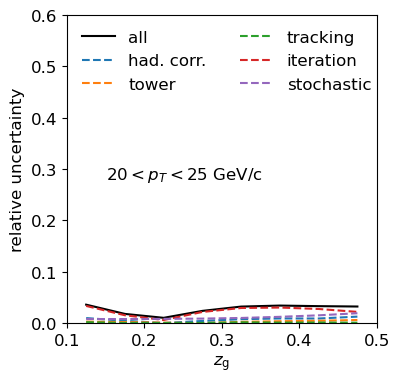

In [135]:
plt.figure(figsize=(4,4))

plt.plot(x, (err/y_arr[1]), color='k', label='all')
plt.plot(x, (err3/y_arr[1]), '--', label='had. corr.')
plt.plot(x, (err2/y_arr[1]), '--', label='tower')
plt.plot(x, (err1/y_arr[1]), '--', label='tracking')
# plt.plot(x, (err4/y_arr[1]), '--', label='Herwig')
# plt.plot(x, (err5/y_arr[1]), '--', label='Pythia8')
plt.plot(x, (err7/y_arr[1]), '--', label='iteration')
plt.plot(x, (err6/y_arr[1]), '--', label='stochastic')

plt.ylabel('relative uncertainty')
plt.xlabel(r'$z_{\rm{g}}$')
plt.legend(frameon=False, loc='upper left', ncol=2)
#plt.text(0.25,0.22,'$p$+$p$ $\sqrt{s}=200$ GeV\nanti-$k_\rm{T}$, $R=0.4$')
plt.text(0.15,0.28,'$20<p_T<25$ GeV/c')
plt.xlim(0.1,0.5)
plt.ylim(0,0.6)

In [136]:
mean_20_25 = y_arr[1]
err_20_25 = err
print(mean_20_25)
print(err_20_25)

[5.32155342 3.63684387 2.69033232 2.1171456  1.78068986 1.56680122
 1.46333132 1.42330239]
[0.19135406 0.06530969 0.02773874 0.05049682 0.05736719 0.05357254
 0.04839351 0.04604825]


In [137]:
x, y_arr, err_arr = process_ob_nom(1)
# x, y_arr_hw, err_arr_hw = process_ob_hw(1)
# x, y_arr_py8, err_arr_py8 = process_ob_py8(1)
x, y_arr_eff096, err_arr_eff096 = process_ob_detector(1, "eff096", df1_eff096)
x, y_arr_tow104, err_arr_tow104 = process_ob_detector(1, "tow104", df1_tow104)
x, y_arr_hadcorr05, err_arr_hadcorr05 = process_ob_detector(1, "hadcorr05", df1_hadcorr05)

observable: zg
iteration 1
relative uncertainty from NN: [0.00087146 0.00060077 0.00037611 0.00043566 0.00075225 0.0011057
 0.00146684 0.00184038]
relative uncertainty from stat: [0.00443341 0.00550027 0.00656704 0.00765514 0.00835217 0.00902811
 0.00926819 0.00935679]
total (stat + NN + MC bootstrap + data bootstrap): [0.00451824 0.00553298 0.0065778  0.00766752 0.00838597 0.00909557
 0.00938355 0.00953607]
iteration 2
relative uncertainty from NN: [0.00106229 0.00068019 0.0005177  0.00064817 0.00090933 0.00121653
 0.00157059 0.00196604]
relative uncertainty from stat: [0.00444855 0.00550543 0.00657912 0.00766074 0.00838725 0.00910326
 0.00932374 0.0093447 ]
relative uncertainty from MC bootstrap: [0.00715147 0.00564195 0.00682865 0.00816433 0.00965219 0.01153281
 0.01395865 0.01882556]
relative uncertainty from data bootstrap: [0.00364046 0.00257129 0.00206203 0.00214968 0.00305141 0.00451826
 0.00617246 0.00765673]
total (stat + NN + MC bootstrap + data bootstrap): [0.00923658 0.008

In [ ]:
err1 = abs(np.array(y_arr[1])-np.array(y_arr_eff096[0]))
err2 = abs(np.array(y_arr[1])-np.array(y_arr_tow104[0]))
err3 = abs(np.array(y_arr[1])-np.array(y_arr_hadcorr05[0]))
err4 = np.zeros_like(err1)
err5 = np.zeros_like(err1)
err6 = err_arr[1]
delta_y = []
for it in range(2,7):
    delta_y.append(abs(y_arr[it-1] - y_arr[1]))
err7 = np.max(delta_y, axis=0)

err = []
for i in range(0,len(err1)):
    err.append( np.sqrt( (err1[i])**2 + (err2[i])**2 + (err3[i])**2 + (max(abs(err4[i]),abs(err5[i])))**2 + (err6[i])**2 ) )
err = np.array(err)

In [139]:
mean_25_30 = y_arr[1]
err_25_30 = err
print(mean_25_30)
print(err_25_30)

[5.71670267 3.69875379 2.63110701 2.03851058 1.70939282 1.49913047
 1.36360044 1.34280222]
[0.07475489 0.03343645 0.02586272 0.02704336 0.02778771 0.0261483
 0.02638405 0.03209632]


In [140]:
x, y_arr, err_arr = process_ob_nom(2)
# x, y_arr_hw, err_arr_hw = process_ob_hw(2)
# x, y_arr_py8, err_arr_py8 = process_ob_py8(2)
x, y_arr_eff096, err_arr_eff096 = process_ob_detector(2, "eff096", df1_eff096)
x, y_arr_tow104, err_arr_tow104 = process_ob_detector(2, "tow104", df1_tow104)
x, y_arr_hadcorr05, err_arr_hadcorr05 = process_ob_detector(2, "hadcorr05", df1_hadcorr05)

observable: zg
iteration 1
relative uncertainty from NN: [0.00116003 0.00070073 0.00046053 0.00066563 0.00101616 0.00142983
 0.00187116 0.00230785]
relative uncertainty from stat: [0.00523307 0.00670388 0.00823574 0.00937077 0.01032567 0.01132165
 0.01160219 0.0118318 ]
total (stat + NN + MC bootstrap + data bootstrap): [0.0053601  0.0067404  0.00824861 0.00939439 0.01037555 0.01141158
 0.01175211 0.01205478]
iteration 2
relative uncertainty from NN: [0.00141306 0.00083952 0.00071783 0.00096519 0.00124204 0.00162385
 0.00210237 0.00262186]
relative uncertainty from stat: [0.00524694 0.00674107 0.00822093 0.00947136 0.01044021 0.01149015
 0.01166989 0.01199518]
relative uncertainty from MC bootstrap: [0.0087724  0.00865077 0.00860413 0.00965513 0.01229494 0.01406218
 0.01688496 0.01907969]
relative uncertainty from data bootstrap: [0.00465317 0.00297991 0.00235205 0.00294734 0.00412525 0.00537833
 0.0075517  0.0090955 ]
total (stat + NN + MC bootstrap + data bootstrap): [0.01131964 0.01

In [ ]:
err1 = abs(np.array(y_arr[1])-np.array(y_arr_eff096[0]))
err2 = abs(np.array(y_arr[1])-np.array(y_arr_tow104[0]))
err3 = abs(np.array(y_arr[1])-np.array(y_arr_hadcorr05[0]))
err4 = np.zeros_like(err1)
err5 = np.zeros_like(err1)
err6 = err_arr[1]
delta_y = []
for it in range(2,7):
    delta_y.append(abs(y_arr[it-1] - y_arr[1]))
err7 = np.max(delta_y, axis=0)

err = []
for i in range(0,len(err1)):
    err.append( np.sqrt( (err1[i])**2 + (err2[i])**2 + (err3[i])**2 + (max(abs(err4[i]),abs(err5[i])))**2 + (err6[i])**2 ) )
err = np.array(err)

In [ ]:
mean_30_40 = y_arr[1]
err_30_40 = err
print(mean_30_40)
print(err_30_40)

[5.91605511 3.69733826 2.57330494 2.02399468 1.6690804  1.45857056
 1.35141143 1.31024462]
[0.16623799 0.04212167 0.03291105 0.04719001 0.03988698 0.03333708
 0.03293888 0.04029074]


In [143]:
x, y_arr, err_arr = process_ob_nom(3)
# x, y_arr_hw, err_arr_hw = process_ob_hw(3)
# x, y_arr_py8, err_arr_py8 = process_ob_py8(3)
x, y_arr_eff096, err_arr_eff096 = process_ob_detector(3, "eff096", df1_eff096)
x, y_arr_tow104, err_arr_tow104 = process_ob_detector(3, "tow104", df1_tow104)
x, y_arr_hadcorr05, err_arr_hadcorr05 = process_ob_detector(3, "hadcorr05", df1_hadcorr05)

observable: zg
iteration 1
relative uncertainty from NN: [0.00167895 0.00100083 0.00076841 0.00107199 0.00152979 0.00206598
 0.00266758 0.00333325]
relative uncertainty from stat: [0.00721852 0.00961107 0.01201334 0.01293122 0.0152367  0.01526564
 0.01577857 0.01648297]
total (stat + NN + MC bootstrap + data bootstrap): [0.0074112  0.00966304 0.01203789 0.01297558 0.01531331 0.01540481
 0.01600247 0.01681662]
iteration 2
relative uncertainty from NN: [0.00244935 0.00154319 0.00137432 0.00176734 0.00230879 0.00300743
 0.00390744 0.00492135]
relative uncertainty from stat: [0.00730736 0.0097186  0.0120695  0.01344221 0.01565859 0.01555627
 0.01574884 0.01729121]
relative uncertainty from MC bootstrap: [0.01352323 0.01163337 0.01259019 0.01300286 0.01628381 0.02152335
 0.02431504 0.02664994]
relative uncertainty from data bootstrap: [0.00834086 0.00577561 0.00376125 0.00472761 0.00749557 0.01110304
 0.01485287 0.0188328 ]
total (stat + NN + MC bootstrap + data bootstrap): [0.01765912 0.01

In [ ]:
err1 = abs(np.array(y_arr[1])-np.array(y_arr_eff096[0]))
err2 = abs(np.array(y_arr[1])-np.array(y_arr_tow104[0]))
err3 = abs(np.array(y_arr[1])-np.array(y_arr_hadcorr05[0]))
err4 = np.zeros_like(err1)
err5 = np.zeros_like(err1)
err6 = err_arr[1]

delta_y = []
for it in range(2,7): 
    delta_y.append( abs(y_arr[it-1]-y_arr[1]) )
err7 = np.max(delta_y,axis=0)

err = []
for i in range(0,len(err1)):
    err.append( np.sqrt( (err1[i])**2 + (err2[i])**2 + (err3[i])**2 + (max(abs(err4[i]), abs(err5[i]), abs(err7[i])))**2 + (err6[i])**2 ) )
err = np.array(err)

(0.0, 0.6)

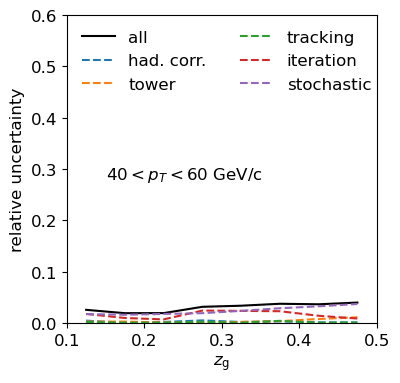

In [146]:
plt.figure(figsize=(4,4))

plt.plot(x, (err/y_arr[1]), color='k', label='all')
plt.plot(x, (err3/y_arr[1]), '--', label='had. corr.')
plt.plot(x, (err2/y_arr[1]), '--', label='tower')
plt.plot(x, (err1/y_arr[1]), '--', label='tracking')
# plt.plot(x, (err4/y_arr[1]), '--', label='Herwig')
# plt.plot(x, (err5/y_arr[1]), '--', label='Pythia8')
plt.plot(x, (err7/y_arr[1]), '--', label='iteration')
plt.plot(x, (err6/y_arr[1]), '--', label='stochastic')

plt.ylabel('relative uncertainty')
plt.xlabel(r'$z_{\rm{g}}$')
plt.legend(frameon=False, loc='upper left', ncol=2)
#plt.text(0.25,0.22,'$p$+$p$ $\sqrt{s}=200$ GeV\nanti-$k_\mathrm{T}$, $R=0.4$')
plt.text(0.15,0.28,'$40<p_T<60$ GeV/c')
plt.xlim(0.1,0.5)
plt.ylim(0,0.6)

In [147]:
mean_40_60 = y_arr[1]
err_40_60 = err
print(mean_40_60)
print(err_40_60)

[6.27388909 3.67704701 2.53633015 1.91595408 1.59676854 1.41945648
 1.30503787 1.27551678]
[0.16237023 0.07123859 0.04947193 0.06090414 0.05416692 0.05351699
 0.04790601 0.05104948]


### Fig 7.15

([<matplotlib.axis.XTick at 0x145b51f8e350>,
 [Text(0.1, 0, '0.1'),
  Text(0.2, 0, '0.2'),
  Text(0.30000000000000004, 0, '0.3'),
  Text(0.4, 0, '0.4'),
  Text(0.5, 0, '0.5')])

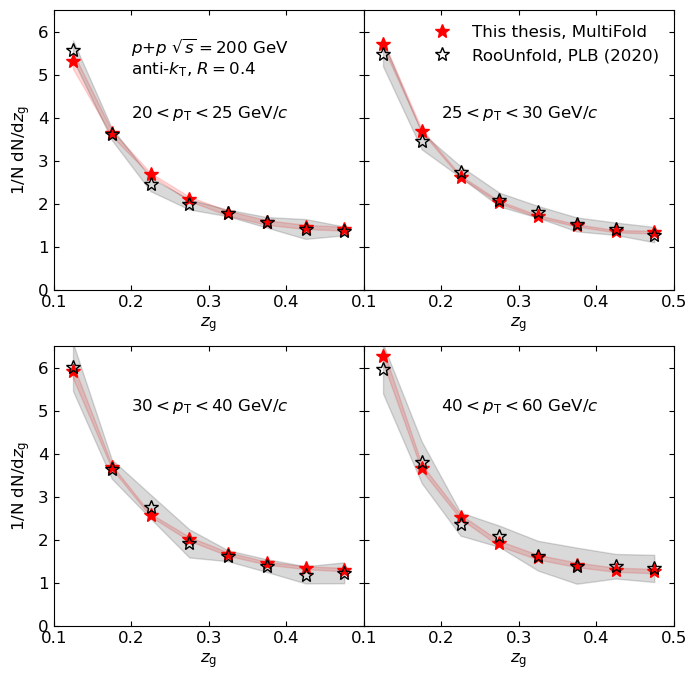

In [ ]:
gs1 = gridspec.GridSpec(2,2,width_ratios=(1,1), height_ratios=(5,5))

fig = plt.figure(figsize=(8,8))
plt.subplots_adjust(wspace=0)

x = np.arange(0.125,0.525,0.05)

ax1 = fig.add_subplot(gs1[0])
plt.text(0.2, 5, r'$p$+$p$ $\sqrt{s}=200$ GeV' '\n' r'anti-$k_{\rm{T}}$, $R=0.4$', fontsize=12)
plt.text(0.2,4,r'$20 < p_{\rm{T}} < 25$ GeV/$c$', fontsize=12)
plt.plot(x, mean_20_25, color='red', marker='*', ls='none', markersize=10, label='MultiFold')
plt.fill_between(x, mean_20_25-err_20_25, mean_20_25+err_20_25, color='r', alpha=0.15)
plt.fill_between(x+0, mean_20_25_rithya-err_20_25_rithya, mean_20_25_rithya+err_20_25_rithya, color='k', alpha=0.15)
plt.plot(x+0, mean_20_25_rithya, label='RooUnfold\nPLB (2020)', ls='none', marker='*', markersize=10, color='none', mec='k')
plt.xlim(left=0.1, right=0.5)
plt.xlabel(r'$z_{\rm{g}}$')
plt.ylim(0,6.5)
plt.ylabel(r'1/N dN/d$z_{\rm{g}}$')
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')
#ax.axes.xaxis.set_minor_locator(MultipleLocator(0.5))
#ax.axes.xaxis.set_major_locator(MultipleLocator(2))
#ax.axes.yaxis.set_minor_locator(MultipleLocator(0.01))
#ax.axes.yaxis.set_major_locator(MultipleLocator(0.05))
plt.xticks(np.arange(0.1,0.5,0.1))

ax2 = fig.add_subplot(gs1[1])
plt.text(0.2,4,r'$25 < p_{\rm{T}} < 30$ GeV/$c$', fontsize=12)
plt.plot(x, mean_25_30, color='red', marker='*', ls='none', markersize=10, label='This thesis, MultiFold')
plt.fill_between(x, mean_25_30-err_25_30, mean_25_30+err_25_30, color='r', alpha=0.15)
plt.fill_between(x+0, mean_25_30_rithya-err_25_30_rithya, mean_25_30_rithya+err_25_30_rithya, color='k', alpha=0.15)
plt.plot(x+0, mean_25_30_rithya, label='RooUnfold, PLB (2020)', ls='none', marker='*', markersize=10, color='none', mec='k')
plt.xlim(left=0.1, right=0.5)
plt.xlabel(r'$z_{\rm{g}}$')
plt.ylim(0,6.5)
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')
ax.axes.yaxis.set_ticklabels([])
#ax.axes.xaxis.set_minor_locator(MultipleLocator(0.5))
#ax.axes.xaxis.set_major_locator(MultipleLocator(2))
#ax.axes.yaxis.set_minor_locator(MultipleLocator(0.01))
#ax.axes.yaxis.set_major_locator(MultipleLocator(0.05))
plt.legend(frameon=False, fontsize=12, loc='upper right')
plt.xticks(np.arange(0.1,0.6,0.1))

ax3 = fig.add_subplot(gs1[2])
plt.text(0.2,5,r'$30 < p_{\rm{T}} < 40$ GeV/$c$', fontsize=12)
plt.plot(x, mean_30_40, color='red', marker='*', ls='none', markersize=10, label='MultiFold')
plt.fill_between(x, mean_30_40-err_30_40, mean_30_40+err_30_40, color='r', alpha=0.15)
plt.fill_between(x+0, mean_30_40_rithya-err_30_40_rithya, mean_30_40_rithya+err_30_40_rithya, color='k', alpha=0.15)
plt.plot(x+0, mean_30_40_rithya, label='RooUnfold\nPLB (2020)', ls='none', marker='*', markersize=10, color='none', mec='k')
plt.xlim(left=0.1, right=0.5)
plt.xlabel(r'$z_{\rm{g}}$')
plt.ylabel(r'1/N dN/d$z_{\rm{g}}$')
plt.ylim(0,6.5)
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')
#ax.axes.xaxis.set_minor_locator(MultipleLocator(0.5))
#ax.axes.xaxis.set_major_locator(MultipleLocator(2))
#ax.axes.yaxis.set_minor_locator(MultipleLocator(0.01))
#ax.axes.yaxis.set_major_locator(MultipleLocator(0.05))
plt.xticks(np.arange(0.1,0.5,0.1))

ax4 = fig.add_subplot(gs1[3])
plt.text(0.2,5,r'$40 < p_{\rm{T}} < 60$ GeV/$c$', fontsize=12)
plt.plot(x, mean_40_60, color='red', marker='*', ls='none', markersize=10, label='MultiFold')
plt.fill_between(x, mean_40_60-err_40_60, mean_40_60+err_40_60, color='r', alpha=0.15)
plt.fill_between(x+0, mean_40_60_rithya-err_40_60_rithya, mean_40_60_rithya+err_40_60_rithya, color='k', alpha=0.15)
plt.plot(x+0, mean_40_60_rithya, label='RooUnfold\nPLB (2020)', ls='none', marker='*', markersize=10, color='none', mec='k')
plt.xlim(left=0.1, right=0.5)
plt.xlabel(r'$z_{\rm{g}}$')
plt.ylim(0,6.5)
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')
ax.axes.yaxis.set_ticklabels([])
#ax.axes.xaxis.set_minor_locator(MultipleLocator(0.5))
#ax.axes.xaxis.set_major_locator(MultipleLocator(2))
#ax.axes.yaxis.set_minor_locator(MultipleLocator(0.01))
#ax.axes.yaxis.set_major_locator(MultipleLocator(0.05))
plt.xticks(np.arange(0.1,0.6,0.1))

# $log(a)$

In [158]:
obs = ['loga','loga','loga','loga']
binedgess = [np.arange(-4.25,0.25,0.25),np.arange(-4.25,0.25,0.25),np.arange(-4.25,0.25,0.25),np.arange(-4.25,0.25,0.25)]
cuts = ['20<pt<25 and rg>0', '25<pt<30 and rg>0', '30<pt<40 and rg>0', '40<pt<60 and rg>0']

In [159]:
x, y_arr, err_arr = process_ob_nom(0)
# x, y_arr_hw, err_arr_hw = process_ob_hw(0)
# x, y_arr_py8, err_arr_py8 = process_ob_py8(0)
x, y_arr_eff096, err_arr_eff096 = process_ob_detector(0, "eff096", df1_eff096)
x, y_arr_tow104, err_arr_tow104 = process_ob_detector(0, "tow104", df1_tow104)
x, y_arr_hadcorr05, err_arr_hadcorr05 = process_ob_detector(0, "hadcorr05", df1_hadcorr05)

observable: loga
iteration 1


/tmp/tmp.XRiY78Fvze/ipykernel_3170111/434652342.py:8: RuntimeWarning: invalid value encountered in divide
  rels_stat_err.append(np.sqrt(np.histogram(df[ob], bins=binedges, weights=df[column_name]**2, density=False)[0])/\
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/434652342.py:12: RuntimeWarning: invalid value encountered in divide
  print("relative uncertainty from NN:", y_err/y)
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/1454986056.py:30: RuntimeWarning: invalid value encountered in divide
  rel_err = np.sqrt( (err_stat/y_seed)**2 + (err_seed/y_seed)**2 + (err_mc_bs/y_mc_bs)**2 + (err_data_bs/y_data_bs)**2 )


relative uncertainty from NN: [0.00070171        nan 0.0070113  0.00525404 0.00314109 0.00278175
 0.00210336 0.00080094 0.00043798 0.00057787 0.00066919 0.00075936
 0.0008862  0.0012174  0.00219158        nan        nan]
relative uncertainty from stat: [0.00296115        nan 1.01192892 0.84427649 0.24421188 0.05361104
 0.01747757 0.00654488 0.00523225 0.00518106 0.00640224 0.00860011
 0.01397242 0.04522913 0.279553          nan        nan]
total (stat + NN + MC bootstrap + data bootstrap): [0.00304315        nan 1.01195321 0.84429284 0.24423208 0.05368316
 0.01760368 0.0065937  0.00525055 0.00521319 0.00643712 0.00863357
 0.01400049 0.04524551 0.27956159        nan        nan]
iteration 2
relative uncertainty from NN: [0.00068463        nan 0.00723665 0.00622767 0.0032558  0.00261152
 0.001797   0.00067946 0.00043184 0.00065247 0.00078299 0.00087438
 0.00101174 0.00139922 0.00258759        nan        nan]
relative uncertainty from stat: [0.0029593         nan 1.01192892 0.84041983 0.23

/tmp/tmp.XRiY78Fvze/ipykernel_3170111/434652342.py:8: RuntimeWarning: invalid value encountered in divide
  rels_stat_err.append(np.sqrt(np.histogram(df[ob], bins=binedges, weights=df[column_name]**2, density=False)[0])/\
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/434652342.py:12: RuntimeWarning: invalid value encountered in divide
  print("relative uncertainty from NN:", y_err/y)
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/3548961755.py:22: RuntimeWarning: invalid value encountered in divide
  rel_err = np.sqrt( (err_stat/y_seed)**2 + (err_seed/y_seed)**2 )


relative uncertainty from NN: [0.0005843         nan 0.00829003 0.0080952  0.00389379 0.00348224
 0.00221123 0.00068382 0.0004019  0.00053683 0.0006627  0.00073906
 0.00090943 0.00159972 0.00320523        nan        nan]
relative uncertainty from stat: [0.00303519        nan 1.05409253 0.83568501 0.25254792 0.05453179
 0.01787032 0.00671239 0.00537545 0.00531335 0.00661029 0.00877295
 0.01416477 0.04637831 0.30616173        nan        nan]
total (stat + NN): [0.00309092        nan 1.05412512 0.83572422 0.25257794 0.05464286
 0.01800661 0.00674713 0.00539045 0.0053404  0.00664342 0.00880402
 0.01419394 0.04640589 0.30617851        nan        nan]
observable: loga
iteration 2


/tmp/tmp.XRiY78Fvze/ipykernel_3170111/434652342.py:8: RuntimeWarning: invalid value encountered in divide
  rels_stat_err.append(np.sqrt(np.histogram(df[ob], bins=binedges, weights=df[column_name]**2, density=False)[0])/\
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/434652342.py:12: RuntimeWarning: invalid value encountered in divide
  print("relative uncertainty from NN:", y_err/y)
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/3548961755.py:22: RuntimeWarning: invalid value encountered in divide
  rel_err = np.sqrt( (err_stat/y_seed)**2 + (err_seed/y_seed)**2 )


relative uncertainty from NN: [0.00059855        nan 0.0073379  0.00815496 0.0042196  0.00346955
 0.00227484 0.00077986 0.00040853 0.00054102 0.00069661 0.00084898
 0.00102831 0.00159384 0.00285322        nan        nan]
relative uncertainty from stat: [0.00294806        nan 0.94280905 0.83798701 0.24431357 0.05298778
 0.01736824 0.00652795 0.00520153 0.0051775  0.00638215 0.00850946
 0.01385308 0.04422927 0.27791563        nan        nan]
total (stat + NN): [0.00300821        nan 0.9428376  0.83802669 0.24435    0.05310125
 0.01751659 0.00657437 0.00521755 0.00520569 0.00642005 0.00855171
 0.01389119 0.04425798 0.27793027        nan        nan]
observable: loga
iteration 2


/tmp/tmp.XRiY78Fvze/ipykernel_3170111/434652342.py:8: RuntimeWarning: invalid value encountered in divide
  rels_stat_err.append(np.sqrt(np.histogram(df[ob], bins=binedges, weights=df[column_name]**2, density=False)[0])/\


relative uncertainty from NN: [0.00061259        nan 0.00699982 0.0062584  0.00300186 0.00265573
 0.00192149 0.00072456 0.00040833 0.00056743 0.00063947 0.00070405
 0.00084249 0.00133029 0.00248275        nan        nan]
relative uncertainty from stat: [0.00294607        nan 1.09992266 0.83900177 0.22611345 0.05277395
 0.0174561  0.0065558  0.00522861 0.00516025 0.00636941 0.00854032
 0.01385789 0.04470085 0.27858832        nan        nan]
total (stat + NN): [0.00300908        nan 1.09994493 0.83902512 0.22613338 0.05284073
 0.01756154 0.00659572 0.00524453 0.00519136 0.00640143 0.00856929
 0.01388348 0.04472064 0.27859939        nan        nan]


/tmp/tmp.XRiY78Fvze/ipykernel_3170111/434652342.py:12: RuntimeWarning: invalid value encountered in divide
  print("relative uncertainty from NN:", y_err/y)
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/3548961755.py:22: RuntimeWarning: invalid value encountered in divide
  rel_err = np.sqrt( (err_stat/y_seed)**2 + (err_seed/y_seed)**2 )


In [ ]:
err1 = abs(np.array(y_arr[1])-np.array(y_arr_eff096[0]))
err2 = abs(np.array(y_arr[1])-np.array(y_arr_tow104[0]))
err3 = abs(np.array(y_arr[1])-np.array(y_arr_hadcorr05[0]))
err4 = np.zeros_like(err1)
err5 = np.zeros_like(err1)
err6 = err_arr[1]

delta_y = []
for it in range(2,7): 
    delta_y.append( abs(y_arr[it-1]-y_arr[1]) )
err7 = np.max(delta_y,axis=0)

err = []
for i in range(0,len(err1)):
    err.append( np.sqrt( (err1[i])**2 + (err2[i])**2 + (err3[i])**2 + (max(abs(err4[i]), abs(err5[i]), abs(err7[i])))**2 + (err6[i])**2 ) )
err = np.array(err)

In [161]:
def process_array(array):
    return np.concatenate(([array[0]], array[5:-3]))

In [163]:
x_plot = process_array(x)
y_plot = process_array(y_arr[1])
err_plot = process_array(err)
err1_plot = process_array(err1)
err2_plot = process_array(err2)
err3_plot = process_array(err3)
err4_plot = process_array(err4)
err5_plot = process_array(err5)
err6_plot = process_array(err6)
err7_plot = process_array(err7)

(0.0, 0.6)

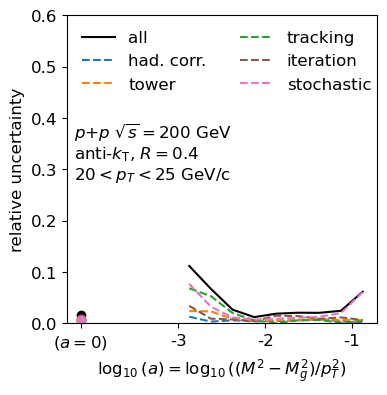

In [164]:
plt.figure(figsize=(4,4))

plt.plot(x_plot[1:], (err_plot/y_plot)[1:], color='k', label='all')
plt.plot(x_plot[1:], (err3_plot/y_plot)[1:], '--', color='tab:blue', label='had. corr.')
plt.plot(x_plot[1:], (err2_plot/y_plot)[1:], '--', color='tab:orange', label='tower')
plt.plot(x_plot[1:], (err1_plot/y_plot)[1:], '--', color='tab:green', label='tracking')
# plt.plot(x_plot[1:], (err4_plot/y_plot)[1:], '--', color='tab:red', label='Herwig')
# plt.plot(x_plot[1:], (err5_plot/y_plot)[1:], '--', color='tab:purple', label='Pythia8')
plt.plot(x_plot[1:], (err7_plot/y_plot)[1:], '--', color='tab:brown', label='iteration')
plt.plot(x_plot[1:], (err6_plot/y_plot)[1:], '--', color='tab:pink', label='stochastic')

plt.plot(x_plot[0], (err_plot/y_plot)[0], 'o', color='k')
plt.plot(x_plot[0], (err3_plot/y_plot)[0], 'o', color='tab:blue')
plt.plot(x_plot[0], (err2_plot/y_plot)[0], 'o', color='tab:orange')
plt.plot(x_plot[0], (err1_plot/y_plot)[0], 'o', color='tab:green')
# plt.plot(x_plot[0], (err4_plot/y_plot)[0], 'o', color='tab:red')
# plt.plot(x_plot[0], (err5_plot/y_plot)[0], 'o', color='tab:purple')
plt.plot(x_plot[0], (err7_plot/y_plot)[0], 'o', color='tab:brown')
plt.plot(x_plot[0], (err6_plot/y_plot)[0], 'o', color='tab:pink')

plt.ylabel('relative uncertainty')
plt.xlabel(r'$\log_{10}(a) = \log_{10}((M^2-M_g^2)/p_T^2)$')
plt.legend(frameon=False, loc='upper left', ncol=2)
plt.text(-4.2,0.32, r'$p$+$p$ $\sqrt{s}=200$ GeV' + '\n' + r'anti-$k_{\rm{T}}$, $R=0.4$')
plt.text(-4.2,0.28,r'$20<p_T<25$ GeV/c')
plt.xticks([-4.125,-3,-2,-1], [r'$(a=0)$','-3','-2','-1'])
plt.ylim(0,0.6)

In [165]:
mean_20_25 = y_arr[1]
err_20_25 = err
print(mean_20_25)
print(err_20_25)

[1.82172282e+00 0.00000000e+00 2.27758344e-06 2.50420843e-05
 5.26071950e-04 4.39696715e-03 4.31100630e-02 3.49360789e-01
 5.28596967e-01 5.51807065e-01 3.82527970e-01 2.21473875e-01
 8.80623421e-02 8.26656421e-03 1.21189634e-04 0.00000000e+00
 0.00000000e+00]
[2.94692283e-02            nan 3.08884284e-06 3.01177517e-05
 1.85717176e-04 4.91815400e-04 2.90150023e-03 9.32264853e-03
 6.49911683e-03 1.04550082e-02 7.97647146e-03 4.57716152e-03
 2.16810451e-03 5.10598913e-04 4.94244997e-05            nan
            nan]


In [166]:
x, y_arr, err_arr = process_ob_nom(1)
# x, y_arr_hw, err_arr_hw = process_ob_hw(1)
# x, y_arr_py8, err_arr_py8 = process_ob_py8(1)
x, y_arr_eff096, err_arr_eff096 = process_ob_detector(1, "eff096", df1_eff096)
x, y_arr_tow104, err_arr_tow104 = process_ob_detector(1, "tow104", df1_tow104)
x, y_arr_hadcorr05, err_arr_hadcorr05 = process_ob_detector(1, "hadcorr05", df1_hadcorr05)

observable: loga
iteration 1


/tmp/tmp.XRiY78Fvze/ipykernel_3170111/434652342.py:8: RuntimeWarning: invalid value encountered in divide
  rels_stat_err.append(np.sqrt(np.histogram(df[ob], bins=binedges, weights=df[column_name]**2, density=False)[0])/\
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/434652342.py:12: RuntimeWarning: invalid value encountered in divide
  print("relative uncertainty from NN:", y_err/y)
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/1454986056.py:30: RuntimeWarning: invalid value encountered in divide
  rel_err = np.sqrt( (err_stat/y_seed)**2 + (err_seed/y_seed)**2 + (err_mc_bs/y_mc_bs)**2 + (err_data_bs/y_data_bs)**2 )


relative uncertainty from NN: [0.00107624        nan 0.00471642 0.0036048  0.00369861 0.00299812
 0.00170204 0.00050684 0.00056856 0.00067907 0.00082693 0.00092636
 0.00117792 0.00186681 0.00498033        nan        nan]
relative uncertainty from stat: [0.00402516        nan 0.95531672 0.43771279 0.11950188 0.03899768
 0.01401414 0.00706511 0.00620956 0.00589129 0.00719776 0.01011862
 0.01896062 0.12740082 0.99188781        nan        nan]
total (stat + NN + MC bootstrap + data bootstrap): [0.00416656        nan 0.95532836 0.43772763 0.1195591  0.03911276
 0.01411711 0.00708326 0.00623554 0.0059303  0.0072451  0.01016093
 0.01899717 0.12741449 0.99190031        nan        nan]
iteration 2
relative uncertainty from NN: [0.00113243        nan 0.00660545 0.00377084 0.00403072 0.00298432
 0.00150664 0.00047756 0.0006129  0.00086    0.00107229 0.00114099
 0.00135146 0.00216196 0.00507673        nan        nan]
relative uncertainty from stat: [0.00403385        nan 0.95273334 0.44779328 0.11

/tmp/tmp.XRiY78Fvze/ipykernel_3170111/434652342.py:8: RuntimeWarning: invalid value encountered in divide
  rels_stat_err.append(np.sqrt(np.histogram(df[ob], bins=binedges, weights=df[column_name]**2, density=False)[0])/\
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/434652342.py:12: RuntimeWarning: invalid value encountered in divide
  print("relative uncertainty from NN:", y_err/y)
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/3548961755.py:22: RuntimeWarning: invalid value encountered in divide
  rel_err = np.sqrt( (err_stat/y_seed)**2 + (err_seed/y_seed)**2 )


relative uncertainty from NN: [0.00097881        nan 0.00626232 0.00469849 0.00505373 0.00368669
 0.00168298 0.00049538 0.00055079 0.0007171  0.00092333 0.00100707
 0.00132378 0.00241007 0.00650627        nan        nan]
relative uncertainty from stat: [0.00408567        nan 0.95742708 0.4655177  0.12282489 0.03953552
 0.01425756 0.00718464 0.00631335 0.00599751 0.00731295 0.01031437
 0.01931019 0.13648999 0.99241388        nan        nan]
total (stat + NN): [0.00420128        nan 0.95744756 0.46554141 0.12292882 0.03970704
 0.01435655 0.0072017  0.00633733 0.00604022 0.00737101 0.01036342
 0.01935551 0.13651126 0.99243521        nan        nan]
observable: loga
iteration 2


/tmp/tmp.XRiY78Fvze/ipykernel_3170111/434652342.py:8: RuntimeWarning: invalid value encountered in divide
  rels_stat_err.append(np.sqrt(np.histogram(df[ob], bins=binedges, weights=df[column_name]**2, density=False)[0])/\
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/434652342.py:12: RuntimeWarning: invalid value encountered in divide
  print("relative uncertainty from NN:", y_err/y)
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/3548961755.py:22: RuntimeWarning: invalid value encountered in divide
  rel_err = np.sqrt( (err_stat/y_seed)**2 + (err_seed/y_seed)**2 )


relative uncertainty from NN: [0.00100741        nan 0.00721165 0.00489699 0.00473834 0.00363876
 0.00190542 0.00058107 0.00057846 0.00075803 0.00096451 0.00112659
 0.00137358 0.00225254 0.00635899        nan        nan]
relative uncertainty from stat: [0.00402251        nan 0.94672465 0.45562804 0.12271392 0.03899981
 0.01403014 0.00706612 0.00621189 0.00589453 0.00720827 0.01013348
 0.01890455 0.12645267 0.98884678        nan        nan]
total (stat + NN): [0.00414674        nan 0.94675212 0.45565435 0.12280536 0.0391692
 0.01415893 0.00708997 0.00623876 0.00594307 0.00727251 0.01019591
 0.01895438 0.12647273 0.98886723        nan        nan]
observable: loga
iteration 2


/tmp/tmp.XRiY78Fvze/ipykernel_3170111/434652342.py:8: RuntimeWarning: invalid value encountered in divide
  rels_stat_err.append(np.sqrt(np.histogram(df[ob], bins=binedges, weights=df[column_name]**2, density=False)[0])/\


relative uncertainty from NN: [0.00094567        nan 0.00596323 0.00415319 0.00406109 0.00307767
 0.00162281 0.00050409 0.00055345 0.00070818 0.00080981 0.00086199
 0.00121774 0.0020192  0.00576416        nan        nan]
relative uncertainty from stat: [0.00402454        nan 0.92336762 0.45641121 0.12026151 0.03884566
 0.01403994 0.00706982 0.00622093 0.00590614 0.00719917 0.01013042
 0.0190163  0.12790607 0.99647141        nan        nan]
total (stat + NN): [0.00413416        nan 0.92338687 0.45643011 0.12033005 0.03896739
 0.01413342 0.00708777 0.0062455  0.00594844 0.00724458 0.01016702
 0.01905525 0.12792201 0.99648808        nan        nan]


/tmp/tmp.XRiY78Fvze/ipykernel_3170111/434652342.py:12: RuntimeWarning: invalid value encountered in divide
  print("relative uncertainty from NN:", y_err/y)
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/3548961755.py:22: RuntimeWarning: invalid value encountered in divide
  rel_err = np.sqrt( (err_stat/y_seed)**2 + (err_seed/y_seed)**2 )


In [ ]:
err1 = abs(np.array(y_arr[1])-np.array(y_arr_eff096[0]))
err2 = abs(np.array(y_arr[1])-np.array(y_arr_tow104[0]))
err3 = abs(np.array(y_arr[1])-np.array(y_arr_hadcorr05[0]))
err4 = np.zeros_like(err1)
err5 = np.zeros_like(err1)
err6 = err_arr[1]
delta_y = []
for it in range(2,7):
    delta_y.append(abs(y_arr[it-1] - y_arr[1]))
err7 = np.max(delta_y, axis=0)

err = []
for i in range(0,len(err1)):
    err.append( np.sqrt( (err1[i])**2 + (err2[i])**2 + (err3[i])**2 + (max(abs(err4[i]),abs(err5[i])))**2 + (err6[i])**2 ) )
err = np.array(err)

(0.0, 0.6)

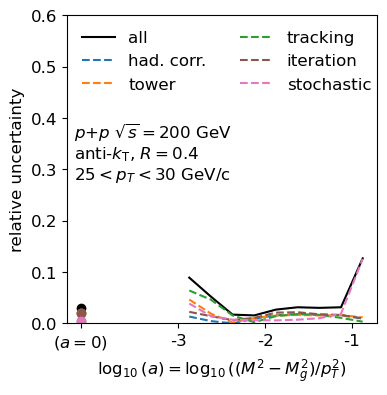

In [171]:
x_plot = process_array(x)
y_plot = process_array(y_arr[1])
err_plot = process_array(err)
err1_plot = process_array(err1)
err2_plot = process_array(err2)
err3_plot = process_array(err3)
err4_plot = process_array(err4)
err5_plot = process_array(err5)
err6_plot = process_array(err6)
err7_plot = process_array(err7)

plt.figure(figsize=(4,4))

plt.plot(x_plot[1:], (err_plot/y_plot)[1:], color='k', label='all')
plt.plot(x_plot[1:], (err3_plot/y_plot)[1:], '--', color='tab:blue', label='had. corr.')
plt.plot(x_plot[1:], (err2_plot/y_plot)[1:], '--', color='tab:orange', label='tower')
plt.plot(x_plot[1:], (err1_plot/y_plot)[1:], '--', color='tab:green', label='tracking')
# plt.plot(x_plot[1:], (err4_plot/y_plot)[1:], '--', color='tab:red', label='Herwig')
# plt.plot(x_plot[1:], (err5_plot/y_plot)[1:], '--', color='tab:purple', label='Pythia8')
plt.plot(x_plot[1:], (err7_plot/y_plot)[1:], '--', color='tab:brown', label='iteration')
plt.plot(x_plot[1:], (err6_plot/y_plot)[1:], '--', color='tab:pink', label='stochastic')

plt.plot(x_plot[0], (err_plot/y_plot)[0], 'o', color='k')
plt.plot(x_plot[0], (err3_plot/y_plot)[0], 'o', color='tab:blue')
plt.plot(x_plot[0], (err2_plot/y_plot)[0], 'o', color='tab:orange')
plt.plot(x_plot[0], (err1_plot/y_plot)[0], 'o', color='tab:green')
# plt.plot(x_plot[0], (err4_plot/y_plot)[0], 'o', color='tab:red')
# plt.plot(x_plot[0], (err5_plot/y_plot)[0], 'o', color='tab:purple')
plt.plot(x_plot[0], (err7_plot/y_plot)[0], 'o', color='tab:brown')
plt.plot(x_plot[0], (err6_plot/y_plot)[0], 'o', color='tab:pink')

plt.ylabel('relative uncertainty')
plt.xlabel(r'$\log_{10}(a) = \log_{10}((M^2-M_g^2)/p_T^2)$')
plt.legend(frameon=False, loc='upper left', ncol=2)
plt.text(-4.2,0.32, r'$p$+$p$ $\sqrt{s}=200$ GeV' + '\n' + r'anti-$k_{\rm{T}}$, $R=0.4$')
plt.text(-4.2,0.28,r'$25<p_T<30$ GeV/c')
plt.xticks([-4.125,-3,-2,-1], [r'$(a=0)$','-3','-2','-1'])
plt.ylim(0,0.6)

In [172]:
mean_25_30 = y_arr[1]
err_25_30 = err
print(mean_25_30)
print(err_25_30)

[1.47078805e+00 0.00000000e+00 9.97773190e-06 1.69432264e-04
 1.22994502e-03 1.38454697e-02 1.10222056e-01 4.69044409e-01
 5.70852513e-01 6.34567064e-01 4.27275902e-01 2.33776063e-01
 6.41633226e-02 4.01109346e-03 4.46985609e-05 0.00000000e+00
 0.00000000e+00]
[4.35776337e-02            nan 9.22423490e-06 7.80106610e-05
 1.83074162e-04 1.23512781e-03 5.74956407e-03 8.04082870e-03
 8.93202252e-03 1.70822349e-02 1.34491267e-02 7.08436585e-03
 2.01820201e-03 5.08417923e-04 4.26171452e-05            nan
            nan]


In [173]:
x, y_arr, err_arr = process_ob_nom(2)
# x, y_arr_hw, err_arr_hw = process_ob_hw(2)
# x, y_arr_py8, err_arr_py8 = process_ob_py8(2)
x, y_arr_eff096, err_arr_eff096 = process_ob_detector(2, "eff096", df1_eff096)
x, y_arr_tow104, err_arr_tow104 = process_ob_detector(2, "tow104", df1_tow104)
x, y_arr_hadcorr05, err_arr_hadcorr05 = process_ob_detector(2, "hadcorr05", df1_hadcorr05)

observable: loga
iteration 1


/tmp/tmp.XRiY78Fvze/ipykernel_3170111/434652342.py:8: RuntimeWarning: invalid value encountered in divide
  rels_stat_err.append(np.sqrt(np.histogram(df[ob], bins=binedges, weights=df[column_name]**2, density=False)[0])/\
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/434652342.py:12: RuntimeWarning: invalid value encountered in divide
  print("relative uncertainty from NN:", y_err/y)
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/1454986056.py:30: RuntimeWarning: invalid value encountered in divide
  rel_err = np.sqrt( (err_stat/y_seed)**2 + (err_seed/y_seed)**2 + (err_mc_bs/y_mc_bs)**2 + (err_data_bs/y_data_bs)**2 )


relative uncertainty from NN: [0.00174139        nan 0.00462926 0.00481991 0.00419361 0.00297242
 0.00136797 0.00050023 0.00072309 0.00082926 0.00107497 0.0012659
 0.00170964 0.00254145        nan        nan        nan]
relative uncertainty from stat: [0.00560765        nan 0.28921023 0.23542899 0.07590912 0.0301731
 0.01224252 0.00836538 0.00716047 0.00675207 0.00847552 0.0127828
 0.02967492 0.18188941        nan        nan        nan]
total (stat + NN + MC bootstrap + data bootstrap): [0.00587181        nan 0.28924728 0.23547832 0.07602487 0.03031915
 0.01231871 0.00838032 0.00719689 0.0068028  0.00854342 0.01284533
 0.02972413 0.18190717        nan        nan        nan]
iteration 2
relative uncertainty from NN: [0.00183201        nan 0.00519767 0.00622767 0.00503656 0.00321046
 0.00138537 0.0005801  0.00080034 0.00108625 0.00141754 0.00153706
 0.00195604 0.0030892         nan        nan        nan]
relative uncertainty from stat: [0.0056304         nan 0.27169424 0.23031907 0.07548

/tmp/tmp.XRiY78Fvze/ipykernel_3170111/434652342.py:8: RuntimeWarning: invalid value encountered in divide
  rels_stat_err.append(np.sqrt(np.histogram(df[ob], bins=binedges, weights=df[column_name]**2, density=False)[0])/\
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/434652342.py:12: RuntimeWarning: invalid value encountered in divide
  print("relative uncertainty from NN:", y_err/y)
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/3548961755.py:22: RuntimeWarning: invalid value encountered in divide
  rel_err = np.sqrt( (err_stat/y_seed)**2 + (err_seed/y_seed)**2 )


relative uncertainty from NN: [0.00170236        nan 0.00670953 0.00773573 0.0063168  0.00384026
 0.00154985 0.00064247 0.00082326 0.00096946 0.00129151 0.00142271
 0.0019774  0.00327654        nan        nan        nan]
relative uncertainty from stat: [0.00565484        nan 0.2963689  0.24012767 0.07685577 0.03071805
 0.01223916 0.00851799 0.00725356 0.00680423 0.00856469 0.01295798
 0.02976795 0.18386616        nan        nan        nan]
total (stat + NN): [0.00590553        nan 0.29644484 0.24025224 0.07711492 0.03095717
 0.0123369  0.00854219 0.00730012 0.00687295 0.00866152 0.01303585
 0.02983356 0.18389535        nan        nan        nan]
observable: loga
iteration 2


/tmp/tmp.XRiY78Fvze/ipykernel_3170111/434652342.py:8: RuntimeWarning: invalid value encountered in divide
  rels_stat_err.append(np.sqrt(np.histogram(df[ob], bins=binedges, weights=df[column_name]**2, density=False)[0])/\
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/434652342.py:12: RuntimeWarning: invalid value encountered in divide
  print("relative uncertainty from NN:", y_err/y)
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/3548961755.py:22: RuntimeWarning: invalid value encountered in divide
  rel_err = np.sqrt( (err_stat/y_seed)**2 + (err_seed/y_seed)**2 )


relative uncertainty from NN: [0.00182109        nan 0.00687533 0.00717213 0.00588008 0.0039051
 0.00179044 0.00072621 0.0008585  0.00104753 0.0013861  0.00162557
 0.00215794 0.00327574        nan        nan        nan]
relative uncertainty from stat: [0.00562381        nan 0.25945947 0.23140529 0.07688835 0.03081815
 0.01226424 0.00841069 0.00718818 0.00676523 0.00849717 0.0128584
 0.0298916  0.18018509        nan        nan        nan]
total (stat + NN): [0.00591132        nan 0.25955054 0.23151641 0.07711287 0.03106458
 0.01239424 0.00844198 0.00723926 0.00684585 0.00860948 0.01296074
 0.02996939 0.18021487        nan        nan        nan]
observable: loga
iteration 2


/tmp/tmp.XRiY78Fvze/ipykernel_3170111/434652342.py:8: RuntimeWarning: invalid value encountered in divide
  rels_stat_err.append(np.sqrt(np.histogram(df[ob], bins=binedges, weights=df[column_name]**2, density=False)[0])/\


relative uncertainty from NN: [0.00173539        nan 0.00593733 0.00641334 0.00533467 0.00359611
 0.00165564 0.00068223 0.00081881 0.00105073 0.00130654 0.00150556
 0.00204757 0.00315817        nan        nan        nan]
relative uncertainty from stat: [0.00562679        nan 0.31137991 0.2366496  0.07611027 0.03040968
 0.01229211 0.0084398  0.00721126 0.00685206 0.00855538 0.01283847
 0.02994968 0.1819191         nan        nan        nan]
total (stat + NN): [0.00588832        nan 0.31143651 0.23673649 0.07629699 0.03062158
 0.01240311 0.00846733 0.00725759 0.00693215 0.00865457 0.01292645
 0.03001959 0.18194651        nan        nan        nan]


/tmp/tmp.XRiY78Fvze/ipykernel_3170111/434652342.py:12: RuntimeWarning: invalid value encountered in divide
  print("relative uncertainty from NN:", y_err/y)
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/3548961755.py:22: RuntimeWarning: invalid value encountered in divide
  rel_err = np.sqrt( (err_stat/y_seed)**2 + (err_seed/y_seed)**2 )


(0.0, 0.6)

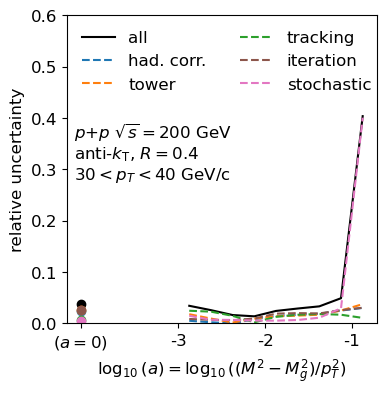

In [174]:
x_plot = process_array(x)
y_plot = process_array(y_arr[1])
err_plot = process_array(err)
err1_plot = process_array(err1)
err2_plot = process_array(err2)
err3_plot = process_array(err3)
err4_plot = process_array(err4)
err5_plot = process_array(err5)
err6_plot = process_array(err6)
err7_plot = process_array(err7)

plt.figure(figsize=(4,4))

plt.plot(x_plot[1:], (err_plot/y_plot)[1:], color='k', label='all')
plt.plot(x_plot[1:], (err3_plot/y_plot)[1:], '--', color='tab:blue', label='had. corr.')
plt.plot(x_plot[1:], (err2_plot/y_plot)[1:], '--', color='tab:orange', label='tower')
plt.plot(x_plot[1:], (err1_plot/y_plot)[1:], '--', color='tab:green', label='tracking')
# plt.plot(x_plot[1:], (err4_plot/y_plot)[1:], '--', color='tab:red', label='Herwig')
# plt.plot(x_plot[1:], (err5_plot/y_plot)[1:], '--', color='tab:purple', label='Pythia8')
plt.plot(x_plot[1:], (err7_plot/y_plot)[1:], '--', color='tab:brown', label='iteration')
plt.plot(x_plot[1:], (err6_plot/y_plot)[1:], '--', color='tab:pink', label='stochastic')

plt.plot(x_plot[0], (err_plot/y_plot)[0], 'o', color='k')
plt.plot(x_plot[0], (err3_plot/y_plot)[0], 'o', color='tab:blue')
plt.plot(x_plot[0], (err2_plot/y_plot)[0], 'o', color='tab:orange')
plt.plot(x_plot[0], (err1_plot/y_plot)[0], 'o', color='tab:green')
# plt.plot(x_plot[0], (err4_plot/y_plot)[0], 'o', color='tab:red')
# plt.plot(x_plot[0], (err5_plot/y_plot)[0], 'o', color='tab:purple')
plt.plot(x_plot[0], (err7_plot/y_plot)[0], 'o', color='tab:brown')
plt.plot(x_plot[0], (err6_plot/y_plot)[0], 'o', color='tab:pink')

plt.ylabel('relative uncertainty')
plt.xlabel(r'$\log_{10}(a) = \log_{10}((M^2-M_g^2)/p_T^2)$')
plt.legend(frameon=False, loc='upper left', ncol=2)
plt.text(-4.2,0.32, r'$p$+$p$ $\sqrt{s}=200$ GeV' + '\n' + r'anti-$k_{\rm{T}}$, $R=0.4$')
plt.text(-4.2,0.28,r'$30<p_T<40$ GeV/c')
plt.xticks([-4.125,-3,-2,-1], [r'$(a=0)$','-3','-2','-1'])
plt.ylim(0,0.6)

In [175]:
mean_30_40 = y_arr[1]
err_30_40 = err
print(mean_30_40)
print(err_30_40)

[1.17955930e+00 0.00000000e+00 2.95774980e-05 3.38121760e-04
 4.10867605e-03 3.59629883e-02 2.22220043e-01 4.92073923e-01
 6.44769553e-01 7.02154526e-01 4.63433318e-01 2.13007485e-01
 4.10832623e-02 1.25923057e-03 0.00000000e+00 0.00000000e+00
 0.00000000e+00]
[4.35776337e-02            nan 9.22423490e-06 7.80106610e-05
 1.83074162e-04 1.23512781e-03 5.74956407e-03 8.04082870e-03
 8.93202252e-03 1.70822349e-02 1.34491267e-02 7.08436585e-03
 2.01820201e-03 5.08417923e-04 4.26171452e-05            nan
            nan]


In [177]:
x, y_arr, err_arr = process_ob_nom(3)
# x, y_arr_hw, err_arr_hw = process_ob_hw(3)
# x, y_arr_py8, err_arr_py8 = process_ob_py8(3)
x, y_arr_eff096, err_arr_eff096 = process_ob_detector(3, "eff096", df1_eff096)
x, y_arr_tow104, err_arr_tow104 = process_ob_detector(3, "tow104", df1_tow104)
x, y_arr_hadcorr05, err_arr_hadcorr05 = process_ob_detector(3, "hadcorr05", df1_hadcorr05)

observable: loga
iteration 1


/tmp/tmp.XRiY78Fvze/ipykernel_3170111/434652342.py:8: RuntimeWarning: invalid value encountered in divide
  rels_stat_err.append(np.sqrt(np.histogram(df[ob], bins=binedges, weights=df[column_name]**2, density=False)[0])/\
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/434652342.py:12: RuntimeWarning: invalid value encountered in divide
  print("relative uncertainty from NN:", y_err/y)
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/1454986056.py:30: RuntimeWarning: invalid value encountered in divide
  rel_err = np.sqrt( (err_stat/y_seed)**2 + (err_seed/y_seed)**2 + (err_mc_bs/y_mc_bs)**2 + (err_data_bs/y_data_bs)**2 )


relative uncertainty from NN: [0.00337651 0.00987481 0.00764514 0.00619681 0.0049283  0.00314317
 0.00130956 0.00108236 0.00110286 0.00130878 0.00166928 0.00213981
 0.00323793 0.00529429        nan        nan        nan]
relative uncertainty from stat: [0.00935309 0.46767434 0.309946   0.08638994 0.06610677 0.02385822
 0.01339953 0.01133076 0.00892044 0.00932004 0.01272445 0.02316822
 0.0665739  0.46489099        nan        nan        nan]
total (stat + NN + MC bootstrap + data bootstrap): [0.0099439  0.46777859 0.31004027 0.08661191 0.06629022 0.02406438
 0.01346337 0.01138234 0.00898835 0.00941149 0.01283348 0.02326683
 0.0666526  0.46492113        nan        nan        nan]
iteration 2
relative uncertainty from NN: [0.00417933 0.0153303  0.01150005 0.00921687 0.00713141 0.00428582
 0.00193833 0.00146121 0.00145778 0.00199565 0.00253731 0.00295664
 0.0041321  0.00665746        nan        nan        nan]
relative uncertainty from stat: [0.00957914 0.49690402 0.31309772 0.08924073 0.06

/tmp/tmp.XRiY78Fvze/ipykernel_3170111/434652342.py:8: RuntimeWarning: invalid value encountered in divide
  rels_stat_err.append(np.sqrt(np.histogram(df[ob], bins=binedges, weights=df[column_name]**2, density=False)[0])/\
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/434652342.py:12: RuntimeWarning: invalid value encountered in divide
  print("relative uncertainty from NN:", y_err/y)
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/3548961755.py:22: RuntimeWarning: invalid value encountered in divide
  rel_err = np.sqrt( (err_stat/y_seed)**2 + (err_seed/y_seed)**2 )


relative uncertainty from NN: [0.0041465  0.0161323  0.01341588 0.01066136 0.00800133 0.00454638
 0.00201561 0.00157764 0.00152281 0.00201003 0.00246856 0.00309148
 0.00454654 0.00693193        nan        nan        nan]
relative uncertainty from stat: [0.00973022 0.49230769 0.30986971 0.08596606 0.06618636 0.02425099
 0.0135519  0.01175014 0.00900494 0.00944232 0.01271065 0.0226517
 0.06622601 0.46422592        nan        nan        nan]
total (stat + NN): [0.01057689 0.49257194 0.31015999 0.08662464 0.06666825 0.02467347
 0.01370097 0.01185558 0.00913279 0.00965389 0.01294814 0.02286169
 0.06638189 0.46427767        nan        nan        nan]
observable: loga
iteration 2


/tmp/tmp.XRiY78Fvze/ipykernel_3170111/434652342.py:8: RuntimeWarning: invalid value encountered in divide
  rels_stat_err.append(np.sqrt(np.histogram(df[ob], bins=binedges, weights=df[column_name]**2, density=False)[0])/\
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/434652342.py:12: RuntimeWarning: invalid value encountered in divide
  print("relative uncertainty from NN:", y_err/y)
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/3548961755.py:22: RuntimeWarning: invalid value encountered in divide
  rel_err = np.sqrt( (err_stat/y_seed)**2 + (err_seed/y_seed)**2 )


relative uncertainty from NN: [0.00476856 0.01768838 0.01254372 0.01050077 0.00799145 0.00475276
 0.00200424 0.00157327 0.00160804 0.00218247 0.00275891 0.00348092
 0.00506982 0.00751846        nan        nan        nan]
relative uncertainty from stat: [0.00938067 0.47702405 0.3000485  0.09086481 0.06465384 0.02456867
 0.01364746 0.0112412  0.0089974  0.00931369 0.01275162 0.02431001
 0.06754551 0.45981899        nan        nan        nan]
total (stat + NN): [0.01052313 0.47735188 0.30031059 0.09146955 0.06514585 0.02502415
 0.01379384 0.01135076 0.00913997 0.00956598 0.01304666 0.02455796
 0.06773551 0.45988045        nan        nan        nan]
observable: loga
iteration 2


/tmp/tmp.XRiY78Fvze/ipykernel_3170111/434652342.py:8: RuntimeWarning: invalid value encountered in divide
  rels_stat_err.append(np.sqrt(np.histogram(df[ob], bins=binedges, weights=df[column_name]**2, density=False)[0])/\


relative uncertainty from NN: [0.00434576 0.0178875  0.01342847 0.01077978 0.00836555 0.0051533
 0.00228327 0.00162778 0.00158096 0.00220097 0.00283461 0.0035036
 0.00472124 0.00732132        nan        nan        nan]
relative uncertainty from stat: [0.00952539 0.48196197 0.30378047 0.08767115 0.06771839 0.02462918
 0.0136051  0.01153404 0.00885862 0.00936451 0.01260697 0.02354336
 0.06553534 0.4677268         nan        nan        nan]
total (stat + NN): [0.01046989 0.48229379 0.30407712 0.08833139 0.06823315 0.02516254
 0.01379536 0.01164834 0.00899859 0.00961968 0.01292172 0.02380262
 0.06570519 0.46778409        nan        nan        nan]


/tmp/tmp.XRiY78Fvze/ipykernel_3170111/434652342.py:12: RuntimeWarning: invalid value encountered in divide
  print("relative uncertainty from NN:", y_err/y)
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/3548961755.py:22: RuntimeWarning: invalid value encountered in divide
  rel_err = np.sqrt( (err_stat/y_seed)**2 + (err_seed/y_seed)**2 )


(0.0, 0.6)

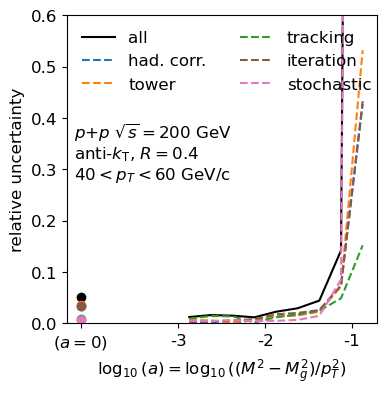

In [178]:
x_plot = process_array(x)
y_plot = process_array(y_arr[1])
err_plot = process_array(err)
err1_plot = process_array(err1)
err2_plot = process_array(err2)
err3_plot = process_array(err3)
err4_plot = process_array(err4)
err5_plot = process_array(err5)
err6_plot = process_array(err6)
err7_plot = process_array(err7)

plt.figure(figsize=(4,4))

plt.plot(x_plot[1:], (err_plot/y_plot)[1:], color='k', label='all')
plt.plot(x_plot[1:], (err3_plot/y_plot)[1:], '--', color='tab:blue', label='had. corr.')
plt.plot(x_plot[1:], (err2_plot/y_plot)[1:], '--', color='tab:orange', label='tower')
plt.plot(x_plot[1:], (err1_plot/y_plot)[1:], '--', color='tab:green', label='tracking')
# plt.plot(x_plot[1:], (err4_plot/y_plot)[1:], '--', color='tab:red', label='Herwig')
# plt.plot(x_plot[1:], (err5_plot/y_plot)[1:], '--', color='tab:purple', label='Pythia8')
plt.plot(x_plot[1:], (err7_plot/y_plot)[1:], '--', color='tab:brown', label='iteration')
plt.plot(x_plot[1:], (err6_plot/y_plot)[1:], '--', color='tab:pink', label='stochastic')

plt.plot(x_plot[0], (err_plot/y_plot)[0], 'o', color='k')
plt.plot(x_plot[0], (err3_plot/y_plot)[0], 'o', color='tab:blue')
plt.plot(x_plot[0], (err2_plot/y_plot)[0], 'o', color='tab:orange')
plt.plot(x_plot[0], (err1_plot/y_plot)[0], 'o', color='tab:green')
# plt.plot(x_plot[0], (err4_plot/y_plot)[0], 'o', color='tab:red')
# plt.plot(x_plot[0], (err5_plot/y_plot)[0], 'o', color='tab:purple')
plt.plot(x_plot[0], (err7_plot/y_plot)[0], 'o', color='tab:brown')
plt.plot(x_plot[0], (err6_plot/y_plot)[0], 'o', color='tab:pink')

plt.ylabel('relative uncertainty')
plt.xlabel(r'$\log_{10}(a) = \log_{10}((M^2-M_g^2)/p_T^2)$')
plt.legend(frameon=False, loc='upper left', ncol=2)
plt.text(-4.2,0.32, r'$p$+$p$ $\sqrt{s}=200$ GeV' + '\n' + r'anti-$k_{\rm{T}}$, $R=0.4$')
plt.text(-4.2,0.28,r'$40<p_T<60$ GeV/c')
plt.xticks([-4.125,-3,-2,-1], [r'$(a=0)$','-3','-2','-1'])
plt.ylim(0,0.6)

In [179]:
mean_40_60 = y_arr[1]
err_40_60 = err
print(mean_40_60)
print(err_40_60)

[8.59245545e-01 3.45945672e-05 2.52947141e-04 2.23468263e-03
 1.81194187e-02 9.88273849e-02 3.53764984e-01 5.31289463e-01
 7.56096936e-01 7.51032737e-01 4.55433718e-01 1.59360709e-01
 1.42179572e-02 8.89226117e-05 0.00000000e+00 0.00000000e+00
 0.00000000e+00]
[4.35776337e-02            nan 9.22423490e-06 7.80106610e-05
 1.83074162e-04 1.23512781e-03 5.74956407e-03 8.04082870e-03
 8.93202252e-03 1.70822349e-02 1.34491267e-02 7.08436585e-03
 2.01820201e-03 5.08417923e-04 4.26171452e-05            nan
            nan]


### Fig 7.16

([<matplotlib.axis.XTick at 0x145b52b87750>,
 [Text(-4.125, 0, '$(a=0)$'),
  Text(-3.0, 0, '-3'),
  Text(-2.0, 0, '-2'),
  Text(-1.0, 0, '-1'),
  Text(0.0, 0, '0')])

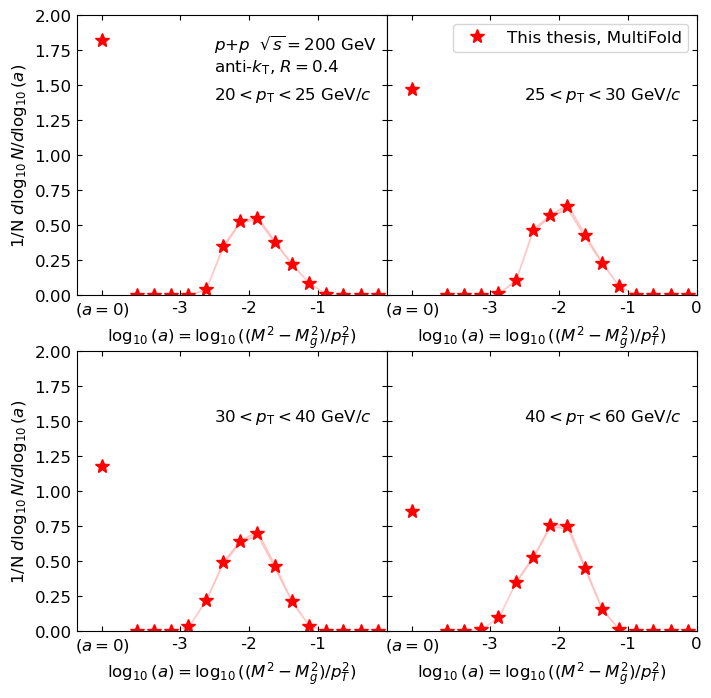

In [183]:
gs1 = gridspec.GridSpec(2,2,width_ratios=(1,1), height_ratios=(5,5))

fig = plt.figure(figsize=(8,8))
plt.subplots_adjust(wspace=0)

binedges = binedgess[0]
x = []
for i in range(0, len(binedges)-1):
    midpoint = 0.5 * (binedges[i] + binedges[i+1])
    x.append(midpoint)

ax1 = fig.add_subplot(gs1[0])
plt.text(-2.5,1.6, r'$p$+$p$  $\sqrt{s}=200$ GeV' '\n' r'anti-$k_{\rm{T}}$, $R=0.4$', fontsize=12)
plt.text(-2.5,1.4,r'$20 < p_{\rm{T}} < 25$ GeV/$c$', fontsize=12)
plt.plot(x[2:], mean_20_25[2:], color='red', marker='*', ls='none', markersize=10, label='MultiFold')
plt.fill_between(x[2:], mean_20_25[2:]-err_20_25[2:], mean_20_25[2:]+err_20_25[2:], color='r', alpha=0.15)
plt.plot(x[0], mean_20_25[0], color='red', marker='*', ls='none', markersize=10, label='MultiFold')
plt.xlim(-4.5,0)
plt.xlabel(r'$\log_{10}(a) = \log_{10}((M^2-M_g^2)/p_T^2)$')
plt.ylim(0,2)
plt.ylabel(r'1/N $d\log_{10}N/d\log_{10}(a)$')
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')
#ax.axes.yaxis.set_ticklabels([])
#ax.axes.xaxis.set_ticklabels([])
#ax.axes.xaxis.set_minor_locator(MultipleLocator(0.5))
#ax.axes.xaxis.set_major_locator(MultipleLocator(2))
#ax.axes.yaxis.set_minor_locator(MultipleLocator(0.01))
#ax.axes.yaxis.set_major_locator(MultipleLocator(0.05))
plt.xticks([-4.125,-3,-2,-1],['$(a=0)$','-3','-2','-1'])

ax2 = fig.add_subplot(gs1[1])
plt.text(-2.5,1.4,r'$25 < p_{\rm{T}} < 30$ GeV/$c$', fontsize=12)
plt.plot(x[2:], mean_25_30[2:], color='red', marker='*', ls='none', markersize=10, label='This thesis, MultiFold')
plt.fill_between(x[2:], mean_25_30[2:]-err_25_30[2:], mean_25_30[2:]+err_25_30[2:], color='r', alpha=0.15)
plt.plot(x[0], mean_25_30[0], color='red', marker='*', ls='none', markersize=10)
plt.xlim(-4.5,0)
plt.xlabel(r'$\log_{10}(a) = \log_{10}((M^2-M_g^2)/p_T^2)$')
plt.ylim(0,2)
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')
ax.axes.yaxis.set_ticklabels([])
#ax.axes.xaxis.set_ticklabels([])
#ax.axes.xaxis.set_minor_locator(MultipleLocator(0.5))
#ax.axes.xaxis.set_major_locator(MultipleLocator(2))
#ax.axes.yaxis.set_minor_locator(MultipleLocator(0.01))
#ax.axes.yaxis.set_major_locator(MultipleLocator(0.05))
plt.legend(fontsize=12, loc='upper right')
plt.xticks([-4.125,-3,-2,-1,0],['$(a=0)$','-3','-2','-1','0'])

ax3 = fig.add_subplot(gs1[2])
#plt.subplot(233)
plt.text(-2.5,1.5,r'$30 < p_{\rm{T}} < 40$ GeV/$c$', fontsize=12)
plt.plot(x[2:], mean_30_40[2:], color='red', marker='*', ls='none', markersize=10, label='MultiFold')
plt.fill_between(x[2:], mean_30_40[2:]-err_30_40[2:], mean_30_40[2:]+err_30_40[2:], color='r', alpha=0.15)
plt.plot(x[0], mean_30_40[0], color='red', marker='*', ls='none', markersize=10)
plt.xlim(-4.5,0)
plt.xlabel(r'$\log_{10}(a) = \log_{10}((M^2-M_g^2)/p_T^2)$')
plt.ylabel(r'1/N $d\log_{10}N/d\log_{10}(a)$')
plt.ylim(0,2)
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')
#ax.axes.yaxis.set_ticklabels([])
#ax.axes.xaxis.set_ticklabels([])
#ax.axes.xaxis.set_minor_locator(MultipleLocator(0.5))
#ax.axes.xaxis.set_major_locator(MultipleLocator(2))
#ax.axes.yaxis.set_minor_locator(MultipleLocator(0.01))
#ax.axes.yaxis.set_major_locator(MultipleLocator(0.05))
plt.xticks([-4.125,-3,-2,-1],['$(a=0)$','-3','-2','-1'])

ax4 = fig.add_subplot(gs1[3])
#plt.subplot(233)
plt.text(-2.5,1.5,r'$40 < p_{\rm{T}} < 60$ GeV/$c$', fontsize=12)
plt.plot(x[2:], mean_40_60[2:], color='red', marker='*', ls='none', markersize=10, label='MultiFold')
plt.fill_between(x[2:], mean_40_60[2:]-err_40_60[2:], mean_40_60[2:]+err_40_60[2:], color='r', alpha=0.15)
plt.plot(x[0], mean_40_60[0], color='red', marker='*', ls='none', markersize=10)
plt.xlim(-4.5,0)
plt.xlabel(r'$\log_{10}(a) = \log_{10}((M^2-M_g^2)/p_T^2)$')
plt.ylim(0,2)
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')
ax.axes.yaxis.set_ticklabels([])
#ax.axes.xaxis.set_ticklabels([])
#ax.axes.xaxis.set_minor_locator(MultipleLocator(0.5))
#ax.axes.xaxis.set_major_locator(MultipleLocator(2))
#ax.axes.yaxis.set_minor_locator(MultipleLocator(0.01))
#ax.axes.yaxis.set_major_locator(MultipleLocator(0.05))
plt.xticks([-4.125,-3,-2,-1,0],['$(a=0)$','-3','-2','-1','0'])

In [184]:
obs = ['loga','loga','loga','loga']
binedgess = [np.arange(-4.5, 0.5, 0.5), np.arange(-4.5, 0.5, 0.5), np.arange(-4.5, 0.5, 0.5), np.arange(-4.5, 0.5, 0.5)]
cuts = ['20<pt<30 and 0.4<zg<0.5 and 0<rg<0.1', '20<pt<30 and 0.4<zg<0.5 and 0.15<rg<0.25', '20<pt<30 and 0.1<zg<0.2 and 0.15<rg<0.25', '20<pt<30 and 0.1<zg<0.2 and 0.3<rg<0.4']

In [205]:
x, y_arr, err_arr = process_ob_nom(0)
# x, y_arr_hw, err_arr_hw = process_ob_hw(0)
# x, y_arr_py8, err_arr_py8 = process_ob_py8(0)
x, y_arr_eff096, err_arr_eff096 = process_ob_detector(0, "eff096", df1_eff096)
x, y_arr_tow104, err_arr_tow104 = process_ob_detector(0, "tow104", df1_tow104)
x, y_arr_hadcorr05, err_arr_hadcorr05 = process_ob_detector(0, "hadcorr05", df1_hadcorr05)

observable: loga
iteration 1


/tmp/tmp.XRiY78Fvze/ipykernel_3170111/434652342.py:8: RuntimeWarning: invalid value encountered in divide
  rels_stat_err.append(np.sqrt(np.histogram(df[ob], bins=binedges, weights=df[column_name]**2, density=False)[0])/\
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/434652342.py:12: RuntimeWarning: invalid value encountered in divide
  print("relative uncertainty from NN:", y_err/y)
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/1454986056.py:30: RuntimeWarning: invalid value encountered in divide
  rel_err = np.sqrt( (err_stat/y_seed)**2 + (err_seed/y_seed)**2 + (err_mc_bs/y_mc_bs)**2 + (err_data_bs/y_data_bs)**2 )


relative uncertainty from NN: [0.00178663        nan 0.00263001 0.00123284 0.00048303 0.00067769
 0.00126853 0.00239167        nan]
relative uncertainty from stat: [0.02910443        nan 0.19800286 0.03313018 0.01928881 0.01645241
 0.02817418 0.25105953        nan]
total (stat + NN + MC bootstrap + data bootstrap): [0.02915922        nan 0.19802033 0.03315311 0.01929485 0.01646636
 0.02820273 0.25107092        nan]
iteration 2
relative uncertainty from NN: [0.002391          nan 0.00381442 0.001632   0.0006546  0.00095274
 0.00158902 0.00307321        nan]
relative uncertainty from stat: [0.02878878        nan 0.19831501 0.03307519 0.01938017 0.0165424
 0.02849073 0.24994949        nan]
relative uncertainty from MC bootstrap: [0.03370295        nan 0.19149684 0.03244972 0.01639778 0.0142016
 0.02690069 0.27688858        nan]
relative uncertainty from data bootstrap: [0.0089193         nan 0.01918115 0.00676452 0.00238113 0.00359909
 0.00677613 0.01085727        nan]
total (stat + NN + 

/tmp/tmp.XRiY78Fvze/ipykernel_3170111/434652342.py:8: RuntimeWarning: invalid value encountered in divide
  rels_stat_err.append(np.sqrt(np.histogram(df[ob], bins=binedges, weights=df[column_name]**2, density=False)[0])/\
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/434652342.py:12: RuntimeWarning: invalid value encountered in divide
  print("relative uncertainty from NN:", y_err/y)
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/3548961755.py:22: RuntimeWarning: invalid value encountered in divide
  rel_err = np.sqrt( (err_stat/y_seed)**2 + (err_seed/y_seed)**2 )


relative uncertainty from NN: [0.00228719        nan 0.00478248 0.00179877 0.00073924 0.00088967
 0.00187956 0.00326866        nan]
relative uncertainty from stat: [0.02979033        nan 0.20217779 0.03402713 0.01941114 0.01690771
 0.02927761 0.25938988        nan]
total (stat + NN): [0.029878          nan 0.20223435 0.03407464 0.01942521 0.0169311
 0.02933788 0.25941047        nan]
observable: loga
iteration 2


/tmp/tmp.XRiY78Fvze/ipykernel_3170111/434652342.py:8: RuntimeWarning: invalid value encountered in divide
  rels_stat_err.append(np.sqrt(np.histogram(df[ob], bins=binedges, weights=df[column_name]**2, density=False)[0])/\
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/434652342.py:12: RuntimeWarning: invalid value encountered in divide
  print("relative uncertainty from NN:", y_err/y)
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/3548961755.py:22: RuntimeWarning: invalid value encountered in divide
  rel_err = np.sqrt( (err_stat/y_seed)**2 + (err_seed/y_seed)**2 )


relative uncertainty from NN: [0.00282137        nan 0.00490303 0.00213768 0.00073933 0.00107466
 0.00200058 0.00327601        nan]
relative uncertainty from stat: [0.029131          nan 0.20357248 0.03305542 0.01945814 0.0164874
 0.02832635 0.24475765        nan]
total (stat + NN): [0.02926731        nan 0.20363152 0.03312447 0.01947218 0.01652239
 0.02839691 0.24477958        nan]
observable: loga
iteration 2


/tmp/tmp.XRiY78Fvze/ipykernel_3170111/434652342.py:8: RuntimeWarning: invalid value encountered in divide
  rels_stat_err.append(np.sqrt(np.histogram(df[ob], bins=binedges, weights=df[column_name]**2, density=False)[0])/\


relative uncertainty from NN: [0.0024505         nan 0.00356207 0.00169353 0.00058998 0.00090983
 0.00151968 0.00291562        nan]
relative uncertainty from stat: [0.02911623        nan 0.18708284 0.03300204 0.01991975 0.01641495
 0.02802916 0.24220723        nan]
total (stat + NN): [0.02921917        nan 0.18711675 0.03304546 0.01992849 0.01644014
 0.02807033 0.24222478        nan]


/tmp/tmp.XRiY78Fvze/ipykernel_3170111/434652342.py:12: RuntimeWarning: invalid value encountered in divide
  print("relative uncertainty from NN:", y_err/y)
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/3548961755.py:22: RuntimeWarning: invalid value encountered in divide
  rel_err = np.sqrt( (err_stat/y_seed)**2 + (err_seed/y_seed)**2 )


In [ ]:
err1 = abs(np.array(y_arr[1])-np.array(y_arr_eff096[0]))
err2 = abs(np.array(y_arr[1])-np.array(y_arr_tow104[0]))
err3 = abs(np.array(y_arr[1])-np.array(y_arr_hadcorr05[0]))
err4 = np.zeros_like(err1)
err5 = np.zeros_like(err1)
err6 = err_arr[1]

delta_y = []
for it in range(2,7): 
    delta_y.append( abs(y_arr[it-1]-y_arr[1]) )
err7 = np.max(delta_y,axis=0)

err = []
for i in range(0,len(err1)):
    err.append( np.sqrt( (err1[i])**2 + (err2[i])**2 + (err3[i])**2 + (max(abs(err4[i]), abs(err5[i]), abs(err7[i])))**2 + (err6[i])**2 ) )
err = np.array(err)

In [207]:
y_plot_1 = y_arr[1]
err_plot_1 = err

In [208]:
x, y_arr, err_arr = process_ob_nom(1)
# x, y_arr_hw, err_arr_hw = process_ob_hw(1)
# x, y_arr_py8, err_arr_py8 = process_ob_py8(1)
x, y_arr_eff096, err_arr_eff096 = process_ob_detector(1, "eff096", df1_eff096)
x, y_arr_tow104, err_arr_tow104 = process_ob_detector(1, "tow104", df1_tow104)
x, y_arr_hadcorr05, err_arr_hadcorr05 = process_ob_detector(1, "hadcorr05", df1_hadcorr05)

observable: loga
iteration 1


/tmp/tmp.XRiY78Fvze/ipykernel_3170111/434652342.py:8: RuntimeWarning: invalid value encountered in divide
  rels_stat_err.append(np.sqrt(np.histogram(df[ob], bins=binedges, weights=df[column_name]**2, density=False)[0])/\
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/434652342.py:12: RuntimeWarning: invalid value encountered in divide
  print("relative uncertainty from NN:", y_err/y)
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/1454986056.py:30: RuntimeWarning: invalid value encountered in divide
  rel_err = np.sqrt( (err_stat/y_seed)**2 + (err_seed/y_seed)**2 + (err_mc_bs/y_mc_bs)**2 + (err_data_bs/y_data_bs)**2 )


relative uncertainty from NN: [0.00077602        nan 0.00413615 0.00139379 0.00031797 0.0005937
 0.00114046 0.00196275        nan]
relative uncertainty from stat: [0.01463008        nan 0.9982     0.07198431 0.01450871 0.01257576
 0.02409511 0.12634642        nan]
total (stat + NN + MC bootstrap + data bootstrap): [0.01465065        nan 0.99820857 0.0719978  0.01451219 0.01258977
 0.02412208 0.12636167        nan]
iteration 2
relative uncertainty from NN: [0.00100653        nan 0.00479243 0.00157547 0.0004334  0.00080785
 0.0014811  0.00252055        nan]
relative uncertainty from stat: [0.01463046        nan 1.00120842 0.072079   0.0144793  0.01256779
 0.02397831 0.12644021        nan]
relative uncertainty from MC bootstrap: [0.01210349        nan 1.040385   0.07789844 0.01072406 0.01194993
 0.02378401 0.11766798        nan]
relative uncertainty from data bootstrap: [0.00254287        nan 0.02826216 0.00820383 0.00118077 0.00221262
 0.0040904  0.00809623        nan]
total (stat + NN +

/tmp/tmp.XRiY78Fvze/ipykernel_3170111/434652342.py:8: RuntimeWarning: invalid value encountered in divide
  rels_stat_err.append(np.sqrt(np.histogram(df[ob], bins=binedges, weights=df[column_name]**2, density=False)[0])/\
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/434652342.py:12: RuntimeWarning: invalid value encountered in divide
  print("relative uncertainty from NN:", y_err/y)
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/3548961755.py:22: RuntimeWarning: invalid value encountered in divide
  rel_err = np.sqrt( (err_stat/y_seed)**2 + (err_seed/y_seed)**2 )


relative uncertainty from NN: [0.00086306        nan 0.00444816 0.00153859 0.00038117 0.00070069
 0.00133552 0.00249019        nan]
relative uncertainty from stat: [0.01489447        nan 1.00117493 0.07211705 0.01480748 0.01283044
 0.02466396 0.13386571        nan]
total (stat + NN): [0.01491946        nan 1.00118481 0.07213346 0.01481239 0.01284955
 0.02470009 0.13388887        nan]
observable: loga
iteration 2


/tmp/tmp.XRiY78Fvze/ipykernel_3170111/434652342.py:8: RuntimeWarning: invalid value encountered in divide
  rels_stat_err.append(np.sqrt(np.histogram(df[ob], bins=binedges, weights=df[column_name]**2, density=False)[0])/\
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/434652342.py:12: RuntimeWarning: invalid value encountered in divide
  print("relative uncertainty from NN:", y_err/y)
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/3548961755.py:22: RuntimeWarning: invalid value encountered in divide
  rel_err = np.sqrt( (err_stat/y_seed)**2 + (err_seed/y_seed)**2 )


relative uncertainty from NN: [0.00114257        nan 0.00527924 0.00218778 0.00045583 0.00093064
 0.00163829 0.00276524        nan]
relative uncertainty from stat: [0.01453408        nan 0.99867427 0.07124222 0.0144333  0.01252901
 0.02386564 0.12564018        nan]
total (stat + NN): [0.01457892        nan 0.99868823 0.07127581 0.01444049 0.01256353
 0.0239218  0.12567061        nan]
observable: loga
iteration 2


/tmp/tmp.XRiY78Fvze/ipykernel_3170111/434652342.py:8: RuntimeWarning: invalid value encountered in divide
  rels_stat_err.append(np.sqrt(np.histogram(df[ob], bins=binedges, weights=df[column_name]**2, density=False)[0])/\


relative uncertainty from NN: [0.00108585        nan 0.00495666 0.00165537 0.00038464 0.00086601
 0.00137505 0.00217674        nan]
relative uncertainty from stat: [0.01460194        nan 1.00054598 0.07116615 0.01442082 0.01253027
 0.02388806 0.1263788         nan]
total (stat + NN): [0.01464226        nan 1.00055826 0.0711854  0.01442595 0.01256016
 0.02392761 0.12639755        nan]


/tmp/tmp.XRiY78Fvze/ipykernel_3170111/434652342.py:12: RuntimeWarning: invalid value encountered in divide
  print("relative uncertainty from NN:", y_err/y)
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/3548961755.py:22: RuntimeWarning: invalid value encountered in divide
  rel_err = np.sqrt( (err_stat/y_seed)**2 + (err_seed/y_seed)**2 )


In [ ]:
err1 = abs(np.array(y_arr[1])-np.array(y_arr_eff096[0]))
err2 = abs(np.array(y_arr[1])-np.array(y_arr_tow104[0]))
err3 = abs(np.array(y_arr[1])-np.array(y_arr_hadcorr05[0]))
err4 = np.zeros_like(err1)
err5 = np.zeros_like(err1)
err6 = err_arr[1]

delta_y = []
for it in range(2,7): 
    delta_y.append( abs(y_arr[it-1]-y_arr[1]) )
err7 = np.max(delta_y,axis=0)

err = []
for i in range(0,len(err1)):
    err.append( np.sqrt( (err1[i])**2 + (err2[i])**2 + (err3[i])**2 + (max(abs(err4[i]), abs(err5[i]), abs(err7[i])))**2 + (err6[i])**2 ) )
err = np.array(err)

In [210]:
y_plot_2 = y_arr[1]
err_plot_2 = err
print(y_plot_2)
print(err_plot_2)

[6.14931761e-01 0.00000000e+00 4.53239401e-05 1.16545000e-02
 5.43506168e-01 6.25354795e-01 1.98886213e-01 5.62123863e-03
 0.00000000e+00]
[2.34875510e-02            nan 6.54817586e-05 1.29790199e-03
 1.02381643e-02 1.98053775e-02 9.11326745e-03 9.81857869e-04
            nan]


In [211]:
x, y_arr, err_arr = process_ob_nom(2)
# x, y_arr_hw, err_arr_hw = process_ob_hw(2)
# x, y_arr_py8, err_arr_py8 = process_ob_py8(2)
x, y_arr_eff096, err_arr_eff096 = process_ob_detector(2, "eff096", df1_eff096)
x, y_arr_tow104, err_arr_tow104 = process_ob_detector(2, "tow104", df1_tow104)
x, y_arr_hadcorr05, err_arr_hadcorr05 = process_ob_detector(2, "hadcorr05", df1_hadcorr05)

observable: loga


iteration 1


/tmp/tmp.XRiY78Fvze/ipykernel_3170111/434652342.py:8: RuntimeWarning: invalid value encountered in divide
  rels_stat_err.append(np.sqrt(np.histogram(df[ob], bins=binedges, weights=df[column_name]**2, density=False)[0])/\
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/434652342.py:12: RuntimeWarning: invalid value encountered in divide
  print("relative uncertainty from NN:", y_err/y)
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/1454986056.py:30: RuntimeWarning: invalid value encountered in divide
  rel_err = np.sqrt( (err_stat/y_seed)**2 + (err_seed/y_seed)**2 + (err_mc_bs/y_mc_bs)**2 + (err_data_bs/y_data_bs)**2 )


relative uncertainty from NN: [0.00050817        nan 0.00144622 0.00081806 0.00016641 0.00044034
 0.0007077  0.00135177        nan]
relative uncertainty from stat: [0.00708167        nan 0.33882928 0.0329611  0.00714536 0.00772782
 0.01460621 0.11673211        nan]
total (stat + NN + MC bootstrap + data bootstrap): [0.00709987        nan 0.33883237 0.03297125 0.0071473  0.00774036
 0.01462334 0.11673994        nan]
iteration 2
relative uncertainty from NN: [0.0006725         nan 0.00182052 0.00102475 0.00022715 0.00058327
 0.00086965 0.00163206        nan]
relative uncertainty from stat: [0.00707167        nan 0.33970836 0.03278791 0.00716958 0.007752
 0.01467589 0.11470357        nan]
relative uncertainty from MC bootstrap: [0.00626685        nan 0.30877588 0.03807635 0.00608994 0.00766533
 0.013972   0.11420424        nan]
relative uncertainty from data bootstrap: [0.00164872        nan 0.00777755 0.00550701 0.00079327 0.00166121
 0.00278922 0.00736546        nan]
total (stat + NN + 

/tmp/tmp.XRiY78Fvze/ipykernel_3170111/434652342.py:8: RuntimeWarning: invalid value encountered in divide
  rels_stat_err.append(np.sqrt(np.histogram(df[ob], bins=binedges, weights=df[column_name]**2, density=False)[0])/\
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/434652342.py:12: RuntimeWarning: invalid value encountered in divide
  print("relative uncertainty from NN:", y_err/y)
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/3548961755.py:22: RuntimeWarning: invalid value encountered in divide
  rel_err = np.sqrt( (err_stat/y_seed)**2 + (err_seed/y_seed)**2 )


relative uncertainty from NN: [0.0005504         nan 0.00208497 0.00108403 0.00024516 0.00052312
 0.00085433 0.00196974        nan]
relative uncertainty from stat: [0.00722957        nan 0.3379873  0.03295408 0.00732674 0.0078546
 0.01475274 0.11997069        nan]
total (stat + NN): [0.00725049        nan 0.33799373 0.0329719  0.00733084 0.007872
 0.01477745 0.11998686        nan]
observable: loga
iteration 2


/tmp/tmp.XRiY78Fvze/ipykernel_3170111/434652342.py:8: RuntimeWarning: invalid value encountered in divide
  rels_stat_err.append(np.sqrt(np.histogram(df[ob], bins=binedges, weights=df[column_name]**2, density=False)[0])/\
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/434652342.py:12: RuntimeWarning: invalid value encountered in divide
  print("relative uncertainty from NN:", y_err/y)
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/3548961755.py:22: RuntimeWarning: invalid value encountered in divide
  rel_err = np.sqrt( (err_stat/y_seed)**2 + (err_seed/y_seed)**2 )


relative uncertainty from NN: [0.00069124        nan 0.00193791 0.00114826 0.00022665 0.00060925
 0.00092923 0.00181236        nan]
relative uncertainty from stat: [0.00706397        nan 0.34150648 0.03255644 0.00717733 0.00774649
 0.01469145 0.11512634        nan]
total (stat + NN): [0.00709771        nan 0.34151198 0.03257668 0.0071809  0.00777041
 0.0147208  0.11514061        nan]
observable: loga
iteration 2


/tmp/tmp.XRiY78Fvze/ipykernel_3170111/434652342.py:8: RuntimeWarning: invalid value encountered in divide
  rels_stat_err.append(np.sqrt(np.histogram(df[ob], bins=binedges, weights=df[column_name]**2, density=False)[0])/\


relative uncertainty from NN: [0.00051968        nan 0.00171509 0.00088271 0.00022303 0.00047034
 0.00076879 0.00174143        nan]
relative uncertainty from stat: [0.00706142        nan 0.34104195 0.03272577 0.00720735 0.00774549
 0.01462749 0.11828512        nan]
total (stat + NN): [0.00708052        nan 0.34104626 0.03273768 0.0072108  0.00775975
 0.01464768 0.11829794        nan]


/tmp/tmp.XRiY78Fvze/ipykernel_3170111/434652342.py:12: RuntimeWarning: invalid value encountered in divide
  print("relative uncertainty from NN:", y_err/y)
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/3548961755.py:22: RuntimeWarning: invalid value encountered in divide
  rel_err = np.sqrt( (err_stat/y_seed)**2 + (err_seed/y_seed)**2 )


In [ ]:
err1 = abs(np.array(y_arr[1])-np.array(y_arr_eff096[0]))
err2 = abs(np.array(y_arr[1])-np.array(y_arr_tow104[0]))
err3 = abs(np.array(y_arr[1])-np.array(y_arr_hadcorr05[0]))
err4 = np.zeros_like(err1)
err5 = np.zeros_like(err1)
err6 = err_arr[1]

delta_y = []
for it in range(2,7): 
    delta_y.append( abs(y_arr[it-1]-y_arr[1]) )
err7 = np.max(delta_y,axis=0)

err = []
for i in range(0,len(err1)):
    err.append( np.sqrt( (err1[i])**2 + (err2[i])**2 + (err3[i])**2 + (max(abs(err4[i]), abs(err5[i]), abs(err7[i])))**2 + (err6[i])**2 ) )
err = np.array(err)

In [213]:
y_plot_3 = y_arr[1]
err_plot_3 = err
print(y_plot_3)
print(err_plot_3)

[6.72636390e-01 0.00000000e+00 1.65528626e-04 1.86822663e-02
 5.81383641e-01 5.53827241e-01 1.69847428e-01 3.45750634e-03
 0.00000000e+00]
[1.97339511e-02            nan 7.65115718e-05 1.13578263e-03
 7.31552696e-03 1.33905176e-02 5.16392776e-03 5.62631140e-04
            nan]


In [214]:
x, y_arr, err_arr = process_ob_nom(3)
# x, y_arr_hw, err_arr_hw = process_ob_hw(3)
# x, y_arr_py8, err_arr_py8 = process_ob_py8(3)
x, y_arr_eff096, err_arr_eff096 = process_ob_detector(3, "eff096", df1_eff096)
x, y_arr_tow104, err_arr_tow104 = process_ob_detector(3, "tow104", df1_tow104)
x, y_arr_hadcorr05, err_arr_hadcorr05 = process_ob_detector(3, "hadcorr05", df1_hadcorr05)

observable: loga


iteration 1


/tmp/tmp.XRiY78Fvze/ipykernel_3170111/434652342.py:8: RuntimeWarning: invalid value encountered in divide
  rels_stat_err.append(np.sqrt(np.histogram(df[ob], bins=binedges, weights=df[column_name]**2, density=False)[0])/\
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/434652342.py:12: RuntimeWarning: invalid value encountered in divide
  print("relative uncertainty from NN:", y_err/y)
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/1454986056.py:30: RuntimeWarning: invalid value encountered in divide
  rel_err = np.sqrt( (err_stat/y_seed)**2 + (err_seed/y_seed)**2 + (err_mc_bs/y_mc_bs)**2 + (err_data_bs/y_data_bs)**2 )


relative uncertainty from NN: [0.00010337        nan        nan 0.00051372 0.00038906 0.00057506
 0.00100224 0.00273147        nan]
relative uncertainty from stat: [0.00501968        nan        nan 0.2498394  0.01449098 0.01633599
 0.04323375 0.29086053        nan]
total (stat + NN + MC bootstrap + data bootstrap): [0.00502074        nan        nan 0.24983992 0.0144962  0.0163461
 0.04324536 0.29087336        nan]
iteration 2
relative uncertainty from NN: [0.00013228        nan        nan 0.00057284 0.00045367 0.0007579
 0.00134626 0.00307678        nan]
relative uncertainty from stat: [0.00500609        nan        nan 0.24924511 0.01451801 0.01629168
 0.04326855 0.29193234        nan]
relative uncertainty from MC bootstrap: [0.00167209        nan        nan 0.26558143 0.01123536 0.0138455
 0.0380984  0.28197199        nan]
relative uncertainty from data bootstrap: [0.00049443        nan        nan 0.00470924 0.00165448 0.00273132
 0.00488422 0.0196574         nan]
total (stat + NN + M

/tmp/tmp.XRiY78Fvze/ipykernel_3170111/434652342.py:8: RuntimeWarning: invalid value encountered in divide
  rels_stat_err.append(np.sqrt(np.histogram(df[ob], bins=binedges, weights=df[column_name]**2, density=False)[0])/\
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/434652342.py:12: RuntimeWarning: invalid value encountered in divide
  print("relative uncertainty from NN:", y_err/y)
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/3548961755.py:22: RuntimeWarning: invalid value encountered in divide
  rel_err = np.sqrt( (err_stat/y_seed)**2 + (err_seed/y_seed)**2 )


relative uncertainty from NN: [0.00012486        nan        nan 0.00067182 0.00041352 0.00072549
 0.00118167 0.00315126        nan]
relative uncertainty from stat: [0.00509344        nan        nan 0.25409034 0.01489443 0.01643867
 0.04333747 0.29213709        nan]
total (stat + NN): [0.00509497        nan        nan 0.25409123 0.01490017 0.01645467
 0.04335358 0.29215408        nan]
observable: loga
iteration 2


/tmp/tmp.XRiY78Fvze/ipykernel_3170111/434652342.py:8: RuntimeWarning: invalid value encountered in divide
  rels_stat_err.append(np.sqrt(np.histogram(df[ob], bins=binedges, weights=df[column_name]**2, density=False)[0])/\
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/434652342.py:12: RuntimeWarning: invalid value encountered in divide
  print("relative uncertainty from NN:", y_err/y)
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/3548961755.py:22: RuntimeWarning: invalid value encountered in divide
  rel_err = np.sqrt( (err_stat/y_seed)**2 + (err_seed/y_seed)**2 )


relative uncertainty from NN: [0.00014715        nan        nan 0.00064268 0.00051397 0.00083322
 0.00121881 0.00286478        nan]
relative uncertainty from stat: [0.00499346        nan        nan 0.25013646 0.01442577 0.01611329
 0.04246797 0.2779626         nan]
total (stat + NN): [0.00499563        nan        nan 0.25013729 0.01443493 0.01613482
 0.04248546 0.27797736        nan]
observable: loga
iteration 2


/tmp/tmp.XRiY78Fvze/ipykernel_3170111/434652342.py:8: RuntimeWarning: invalid value encountered in divide
  rels_stat_err.append(np.sqrt(np.histogram(df[ob], bins=binedges, weights=df[column_name]**2, density=False)[0])/\


relative uncertainty from NN: [0.00010084        nan        nan 0.00067636 0.00041796 0.00055448
 0.00103679 0.00318227        nan]
relative uncertainty from stat: [0.00500195        nan        nan 0.24902686 0.01459681 0.01619244
 0.04377205 0.2949135         nan]
total (stat + NN): [0.00500296        nan        nan 0.24902778 0.01460279 0.01620193
 0.04378433 0.29493067        nan]


/tmp/tmp.XRiY78Fvze/ipykernel_3170111/434652342.py:12: RuntimeWarning: invalid value encountered in divide
  print("relative uncertainty from NN:", y_err/y)
/tmp/tmp.XRiY78Fvze/ipykernel_3170111/3548961755.py:22: RuntimeWarning: invalid value encountered in divide
  rel_err = np.sqrt( (err_stat/y_seed)**2 + (err_seed/y_seed)**2 )


In [ ]:
err1 = abs(np.array(y_arr[1])-np.array(y_arr_eff096[0]))
err2 = abs(np.array(y_arr[1])-np.array(y_arr_tow104[0]))
err3 = abs(np.array(y_arr[1])-np.array(y_arr_hadcorr05[0]))
err4 = np.zeros_like(err1)
err5 = np.zeros_like(err1)
err6 = err_arr[1]

delta_y = []
for it in range(2,7): 
    delta_y.append( abs(y_arr[it-1]-y_arr[1]) )
err7 = np.max(delta_y,axis=0)

err = []
for i in range(0,len(err1)):
    err.append( np.sqrt( (err1[i])**2 + (err2[i])**2 + (err3[i])**2 + (max(abs(err4[i]), abs(err5[i]), abs(err7[i])))**2 + (err6[i])**2 ) )
err = np.array(err)

In [216]:
y_plot_4 = y_arr[1]
err_plot_4 = err
print(y_plot_4)
print(err_plot_4)

[1.64751044e+00 0.00000000e+00 0.00000000e+00 3.51746775e-04
 1.65555279e-01 1.51697471e-01 3.43890872e-02 4.95977649e-04
 0.00000000e+00]
[0.01216121        nan        nan 0.00012818 0.00436064 0.00547798
 0.00224784 0.00020225        nan]


In [217]:
x = np.array([-4.25, -3.75, -3.25, -2.75, -2.25, -1.75, -1.25, -0.75, -0.25])

### Fig 7.19

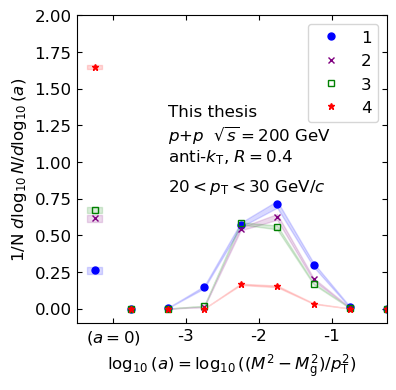

In [223]:
fig = plt.figure(figsize=(4,4))
plt.text(-3.25,1.0,r'This thesis' '\n' r'$p$+$p$  $\sqrt{s}=200$ GeV' '\n' r'anti-$k_{\rm{T}}$, $R=0.4$')
plt.text(-3.25,0.8,r'$20 < p_{\rm{T}} < 30$ GeV/$c$')
line1, = plt.plot(x, y_plot_1, label='1', color='b', marker='o', markersize = 5, ls='none')
plt.fill_between([x[0]-0.1, x[0]+0.1], (y_plot_1-err_plot_1)[0], (y_plot_1+err_plot_1)[0], color='b', alpha=0.15)
plt.fill_between(x[1:], (y_plot_1-err_plot_1)[1:], (y_plot_1+err_plot_1)[1:], color='b', alpha=0.15)
line2, = plt.plot(x, y_plot_2, label='2', color='purple', marker='x', markersize = 5, ls='none')
plt.fill_between([x[0]-0.1, x[0]+0.1], (y_plot_2-err_plot_2)[0], (y_plot_2+err_plot_2)[0], color='purple', alpha=0.15)
plt.fill_between(x[1:], (y_plot_2-err_plot_2)[1:], (y_plot_2+err_plot_2)[1:], color='purple', alpha=0.15)
line3, = plt.plot(x, y_plot_3, label='3', color='g', marker='s', fillstyle='none', markersize = 5, ls='none')
plt.fill_between([x[0]-0.1, x[0]+0.1], (y_plot_3-err_plot_3)[0], (y_plot_3+err_plot_3)[0], color='g', alpha=0.15)
plt.fill_between(x[1:], (y_plot_3-err_plot_3)[1:], (y_plot_3+err_plot_3)[1:], color='g', alpha=0.15)
line4, = plt.plot(x, y_plot_4, label='4', color='r', marker='*', markersize = 5, ls='none')
lined = plt.fill_between(x[1:], (y_plot_4-err_plot_4)[1:], (y_plot_4+err_plot_4)[1:], color='r', alpha=0.15)
plt.fill_between([x[0]-0.1, x[0]+0.1], (y_plot_4-err_plot_4)[0], (y_plot_4+err_plot_4)[0], color='r', alpha=0.15)
plt.xlim(-4.5,-0.25)
plt.xlabel(r'$\log_{10}(a) = \log_{10}((M^2-M_{\rm{g}}^2)/p_{\rm{T}}^2)$')
plt.ylim(-0.1,2)
plt.ylabel(r'1/N $d\log_{10}N/d\log_{10}(a)$')
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')
plt.xticks([-4,-3,-2,-1],['$(a=0)$','-3','-2','-1'])
plt.legend()